<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Multimodal RCC dataset (RNA + 27 proteins): per-channel positivity and gene enrichment per uRNA category.
> - **Manuscript panels:** Fig. 4C-D, ED Fig. 6A
> - **Inputs:** `rois/xenium_rcc` processed zarr
> - **Outputs:** Per-protein enrichment heatmaps/strip plots
> - **Environment / kernel:** `troutpy_updated`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

This is how we run all datasets on a batch manner, except MERSCOPE ones. Those have their code in:
`processing_pipeline_MERSCOPE.ipynb`, same folder

# Load packages

In [1]:
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
#import spatiomic as so

import anndata as ad
import spatialdata as sd
import matplotlib.pyplot as plt
from tqdm import tqdm
import sys
import scipy.stats as stats
import numpy as np

In [2]:
import zarr
from pathlib import Path


saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc")


Path(saving_path).mkdir(parents=True, exist_ok=True)

In [3]:


from troutpy_reproducibility.multimodal import *
from troutpy_reproducibility.plotting import *

In [4]:
import os
import pandas as pd
import numpy as np
import troutpy
import spatialdata as sd
from spatialdata import SpatialData

# --- SET YOUR PARAMETERS HERE ---
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc"  # Change this to your actual path
binsize = 3
background_filter = 0.4
gaussian_kernel_key = 2.0
sainsc_threads = 16
percentile_threshold = 10
square_size = 10
min_counts_env = 5
spatial_var_neighbors = 10
colocalization_threshold = 1
min_logfoldratio = 0.0
lambda_decay = 0.5
source_njobs = 10
max_p_val_noise=0.05
diffusion_params = {}
scatter_params = [
    ("mean_displacement", "extracellular_proportion", 1, 10, 0, 0),
    ("mean_displacement", "in_out_spearmanR", 1, 10, 0, 0),
]
spatial_map_categories = ["mean_displacement", "logfoldratio_over_noise",
    "in_out_spearmanR", "moran_I", "extracellular_proportion",
  "proportion_of_colocalized"]
spatial_map_top = 3
spatial_map_bottom = 3
spot_size_cells = 10
spot_size_extra = 15

# --- PIPELINE EXECUTION ---

# Prepare paths
figures_path = os.path.join(inpath, "figures")
os.makedirs(figures_path, exist_ok=True)
zarr_path = os.path.join(inpath, "data.zarr")
meta_path = os.path.join(inpath, "metadata.csv")

# Load data
sdata = sd.read_zarr(zarr_path) if hasattr(sd, "read_zarr") else SpatialData.read(zarr_path)
metadata = pd.read_csv(meta_path)


# Run troutpy workflow

In [ ]:
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import scanpy as sc
import scipy.sparse as sp
from spatialdata.transformations import get_transformation
import spatialdata_io
from spatialdata.models import PointsModel

# --- CONFIGURE LOCAL DEVELOPER MODULE PATHS ---
# Local troutpy reproducibility path
from troutpy_reproducibility.batch_running import *

    
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp


Proportion of cells retained after filtering: 80.36%
Final adata shape: (41266, 405)


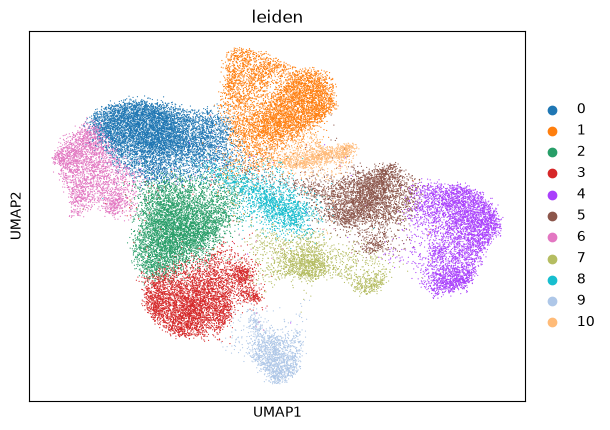

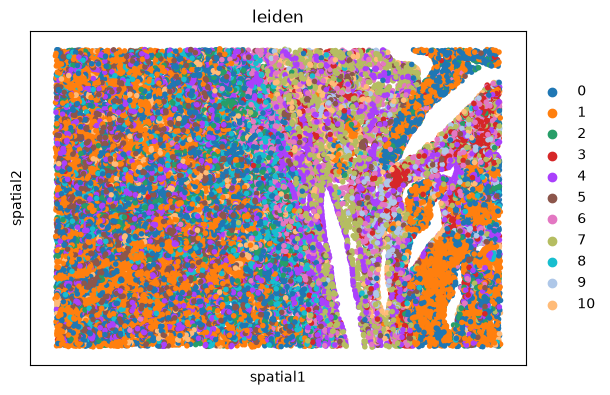

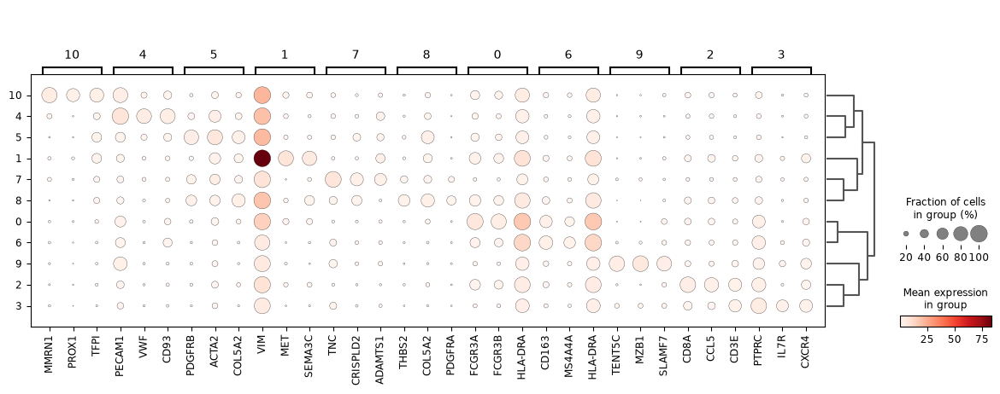

Identifying unique cells...
Loading transcripts for 500 cells...
Heuristic Radius from cell-subset: 1.5919
Calculating local counts for 7272244 transcripts...
Subsampling 500 cells to build likelihood distribution...
--- Analysis Complete ---
Expected Background Count: 1.78
Cell Model Median Count: 15.00


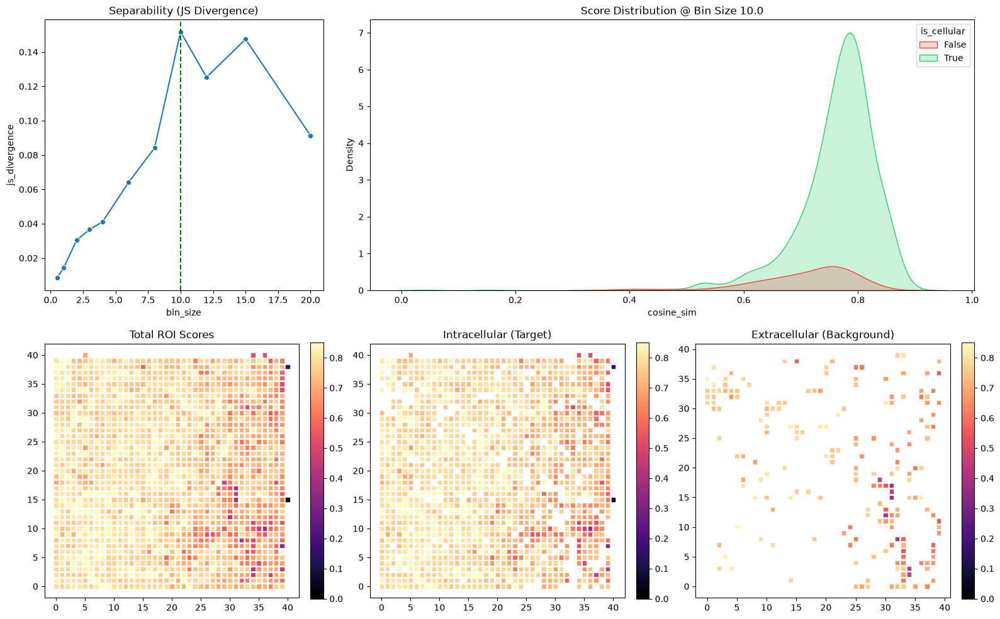

Text(0.5, 1.0, 'Cosine Similarity Distribution: Intra vs Extra-cellular')

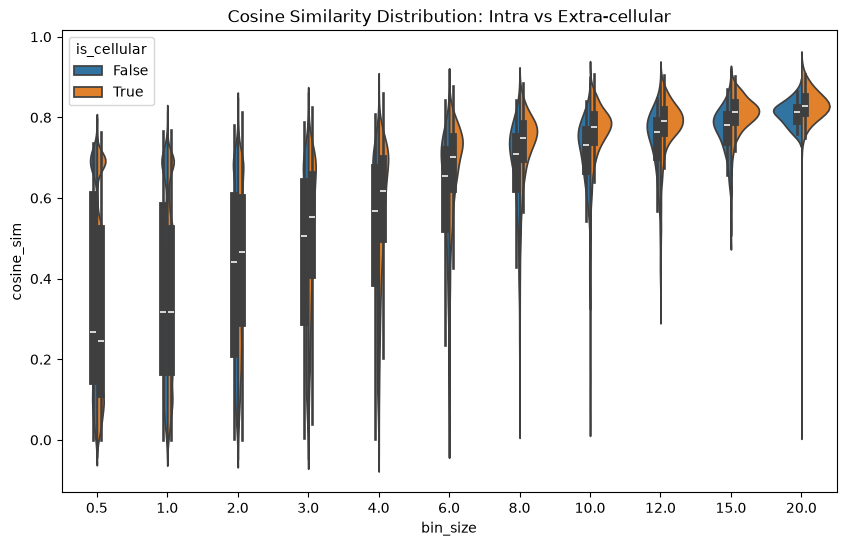

In [9]:
# --- METADATA & PLATFORM SPECIFIC PREPROCESSING ---
if 'metadata' in locals() and metadata is not None and len(metadata) > 0:
    # Technology-specific coordinate/identifier preprocessing
    if "technology" in metadata.columns:
        tech = metadata.loc[0, 'technology']
        
        if tech == 'CosMx':
            print("Applying platform-specific adjustments for CosMx data...")
            transcripts = sdata['transcripts'].compute().rename(columns={'cell_ID': 'cell_id'})
            transcripts['cell_id'] = transcripts['cell_id'].astype(str).replace(['0', '0.0'], 'UNASSIGNED')
            
            sdata['table'].obs = sdata['table'].obs.rename(columns={'cell_ID': 'cell_id'})
            sdata['table'].obs['cell_id'] = sdata['table'].obs['cell_id'].astype(str)
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            sdata['table'].uns['spatialdata_attrs']['instance_key'] = 'cell_id'
            
        elif tech == 'MERSCOPE':
            print("Applying platform-specific adjustments for MERSCOPE data...")
            transcripts = sdata['transcripts'].compute()
            transcripts['cell_id'] = transcripts['cell_id'].astype(str).replace(['-1'], 'UNASSIGNED')
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            sdata['table'].obs['cell_id'] = sdata['table'].obs['cell_id'].astype(str)
    
    # Segmentation fallback logic
    if "segmentation_method" in metadata.columns:
        if "nuclei" in str(metadata["segmentation_method"][0]):
            transcripts = sdata["transcripts"].compute()
            transcripts["overlaps_cell"] = transcripts["overlaps_nucleus"].astype(bool)
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            print("Redefined overlaps_cell in transcripts using nuclei segmentation.")
else:
    print("No metadata found or loaded. Skipping preprocessing & fallback logic.")

# --- TRANSCRIPT CONTROL PROBE CLEANUP ---
tran = sdata['transcripts'].compute()
condition = tran['gene'].str.startswith('Unassigned', na=False)
tran['control_probe'] = np.where(condition, True, tran['control_probe'])
parsed_transcripts = PointsModel.parse(tran)
sdata['transcripts'] = parsed_transcripts

# --- PIPELINE EXECUTION ---
clustering_pipeline(sdata)
try:
    pp.add_morphological_metrics(sdata)
except Exception as e: 
    print(f"Warning: Morphological metrics calculation failed ({e}). Check data integrity.")

opt_r = tl.calculate_heuristic_radius_by_cells(sdata, k=10, n_cells=500)
tl.density_similarity(sdata, radius=opt_r, process_all=True, segmentation_key='overlaps_cell')

# Find optimal bin size using the preset parameters or fallback options
results, met_df, binsize_selected = pp.find_optimal_segmentation_free_bin_size(
    sdata, bin_sizes=[0.5, 1, 2, 3, 4, 6, 8, 10, 12, 15, 20], roi_size=400
)

# Plotting Cosine Similarity
plt.figure(figsize=(10, 6))
sns.violinplot(data=results, x="bin_size", y="cosine_sim", hue="is_cellular", split=True)
plt.title("Cosine Similarity Distribution: Intra vs Extra-cellular")


Saved optimal bin size violin plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/figures/cosine_similarity_distribution.png
Defined 436337 URNA transcripts using Bayesian P > 0.5


Extracting gene counts: 100%|██████████| 493/493 [00:00<00:00, 5682.51it/s]


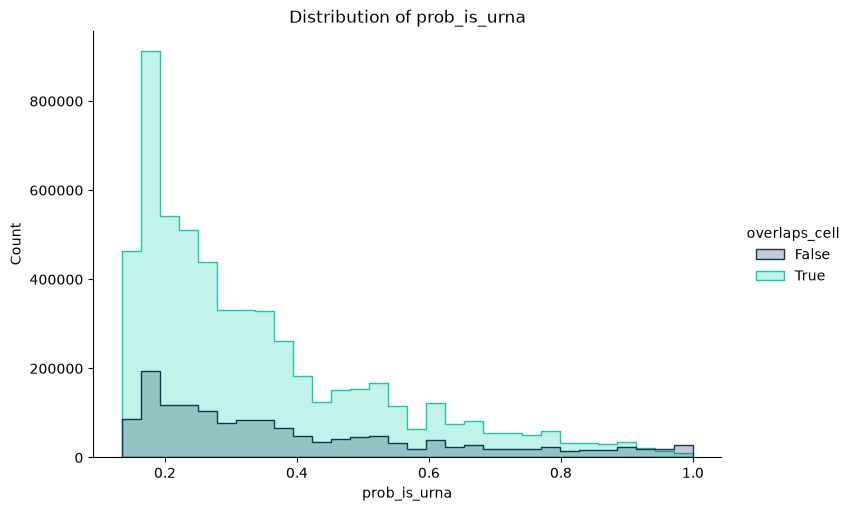

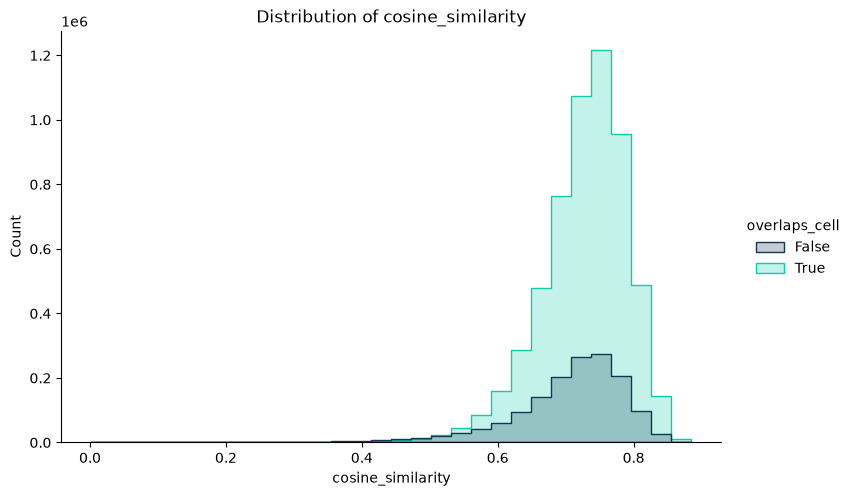

<Figure size 500x200 with 0 Axes>

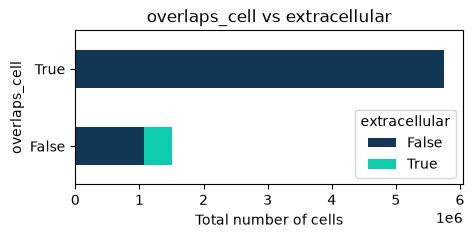

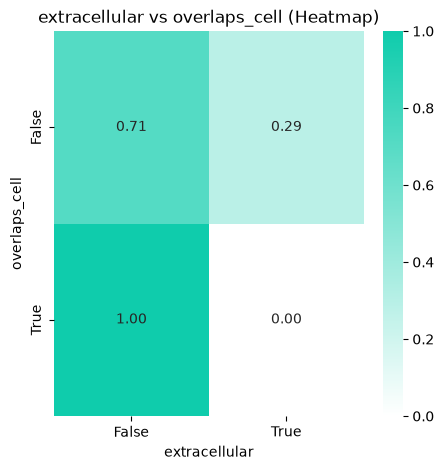

In [10]:
violin_out_path = os.path.join(figures_path, "cosine_similarity_distribution.png")
plt.savefig(violin_out_path, bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved optimal bin size violin plot to: {violin_out_path}")

# Segmentation-free SAiNSC using variables from Cell 1
pp.segmentation_free_sainsc(
    sdata, binsize=binsize_selected, celltype_key="leiden", 
    background_filter=background_filter, gaussian_kernel_key=gaussian_kernel_key, 
    n_threads=sainsc_threads
)
pp.define_urna_probability(sdata)
pp.define_urna(sdata, method='sainsc')

# Histogram of scores
pl.histogram(sdata, x="prob_is_urna", hue="overlaps_cell", palette="troutpy", save=True, figures_path=figures_path)
pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", palette="troutpy", save=True, figures_path=figures_path)

# Crosstabs and charts
pl.crosstab(
    sdata, yvar="extracellular", xvar="overlaps_cell", normalize=False, 
    cmap="troutpy", kind="barh", stacked=True, save=True, figures_path=figures_path, figsize=(5, 2)
)
pl.crosstab(
    sdata, xvar="extracellular", yvar="overlaps_cell", normalize=True, 
    cmap="Aquas", kind="heatmap", stacked=True, save=True, figures_path=figures_path
)

zarr_path_segfree = os.path.join(inpath, "data_with_segfree_2.zarr")
sdata.write(zarr_path_segfree, overwrite=True) 

# Single-value metrics computation
proportion_of_segmented = (sdata["transcripts"]["overlaps_cell"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())
proportion_of_extracellular = (sdata["transcripts"]["extracellular"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())

tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True])
tl.extracellular_enrichment(sdata, gene_key="gene")

# Aggregate extracellular metrics
pp.aggregate_urna(sdata, gene_key="gene", square_size=square_size)

# Environment Neighbor Estimation
nneighbors = estimate_environment_neighbors(
    sdata, cell_key="table", env_key="segmentation_free_table", min_counts=min_counts_env, plot=False
)

tl.spatial_variability(sdata, gene_key="gene", n_neighbors=spatial_var_neighbors, square_size=2 * square_size)
tl.in_out_correlation(sdata, n_neighbors=nneighbors)
tl.spatial_colocalization(sdata, threshold_colocalized=colocalization_threshold, copy=False)

sdata['xrna_metadata'].var['control_probe'] = ~sdata['xrna_metadata'].var['is_control']
sdata["xrna_metadata"].var["control_probe"] = sdata["xrna_metadata"].var["control_probe"].astype(bool)

# Calculate Noise & Gene Metadata profiles
gene_info = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var['is_control'] == False]
genes_prop_over_noise = (gene_info['p_val_noise'] < max_p_val_noise).sum() / gene_info.shape[0]
non_noise_genes = gene_info[gene_info['p_val_noise'] < max_p_val_noise].index
all_gene_ids = sdata['transcripts']['gene'].compute()
noise_RNA_proportion = np.sum(all_gene_ids.isin(non_noise_genes)) / len(all_gene_ids)

# Save fully processed intermediate state
sdata.write(os.path.join(inpath, "data_processed_full.zarr"), overwrite=True)


In [11]:
# --- QUANTIFY STAININGS (WITH FALLBACK) ---
try:
    tl.image_intensities_per_transcript(
        sdata, image_key="morphology_focus", scale="scale0", 
        transcript_key="transcripts", extracellular=False, copy=False
    )
    pp.define_urna_probability_stainings(sdata)
except Exception as e:
    print("Not possible to define probabilities based on stainings.")

# Source score modelling optimization
min_enrichment = sdata.points['transcripts'][
    sdata.points['transcripts']['density_similarity_score'] > 0.5
]['enrichment_over_random'].min().compute()

tl.urna_source_score(
    sdata, chunk_size=100000, cell_type_col='leiden', max_dist=200, 
    lmbda=lambda_decay, max_k=10, ambient_floor=min_enrichment, 
    signal_threshold=10, residual=0.1, copy=False
)

try:
    table_name = "image_intensity_per_transcript"
    sdata.tables[table_name].obs['gene'] = (
        sdata.tables[table_name].obs['gene']
        .astype(str)
        .replace('nan', 'unknown') 
    )
except Exception as e:
    print("Could not process image intensity per transcript table for source score modelling.")

# Segment protrusions with adjusted parameters
tl.segment_protrusions(
    sdata, n_neighbors=10, cluster_eps=2.0, 
    connectivity_threshold=4.0, min_samples=1
)

# Assess diffusion
tl.assess_diffusion(
    sdata, gene_key="gene", distance_key="distance_to_source", 
    filters={'enrichment_class': ('High Density', False)}
)

# Output final modeled data matrix
sdata.write(os.path.join(inpath, "data_with_source_score.zarr"), overwrite=True)

# Calculate categories and generate final CSV stats
categories = pp.get_transcript_categories(sdata)

stats_df = pd.DataFrame({
    "Metric": [
        "proportion_of_segmented", 
        "proportion_of_extracellular", 
        "genes_prop_over_noise", 
        "noise_RNA_proportion"
    ],
    "Value": [
        proportion_of_segmented, 
        proportion_of_extracellular, 
        genes_prop_over_noise, 
        noise_RNA_proportion
    ]
})

stats_df.to_csv(os.path.join(figures_path, "pipeline_stats.csv"), index=False)
categories.to_csv(os.path.join(figures_path, "transcript_categories.csv"), index=False)
print(f"Pipeline completed smoothly. Figures and metrics saved in {figures_path}")

Calculating cosine similarities...
Calculating Bayesian distributions using 101725 background transcripts...
Probabilistic boundary (P=0.5) at similarity: 0.6072
Aligning data and cleaning IDs...
Building global spatial shell...
Building transcript spatial tree...
Processing 1731838 transcripts in 18 chunks...


100%|██████████| 18/18 [23:36<00:00, 78.72s/it]


Reconstructing results into AnnData...
Updating xrna_metadata and cell scores...
Success: 1731276 transcripts assigned.
--- Step 1: Extracting structures from 'transcripts' ---
--- Step 2: Computing morphology and metrics ---
--- Step 3: Assignment logic for 69110 structures ---


Analyzing Parents: 100%|██████████| 69110/69110 [01:02<00:00, 1111.03it/s]


--- Step 4: Updating sdata ---
Success! Registered 'structure_table' with morphological and parent metrics.
--- Diffusion Analysis Debug ---
Initial transcripts: 7272244
Transcripts passing filters: 6127346
Transcripts shared with source_score: 586940
SUCCESS: Statistics added for 387 genes.
Pipeline completed smoothly. Figures and metrics saved in /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/figures


# Downstream analysis on image

# Downstream analysis

# Read results from sdata

In [5]:
sdata=sd.read_zarr(os.path.join(inpath, "data_with_source_score.zarr"))

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import correlate

def analyze_channels_and_get_thresholds(
    sdata,
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    saving_path: Path | str | None = None,
    step_size: int = 50,
    cmap: str = "gray",
    mode: str = "stringent"  # Options: "permissive", "standard", "stringent"
) -> pd.DataFrame:
    """
    Computes cumulative autocorrelation per channel, auto-detects thresholds based on
    the selected stringency mode, generates masks, and returns a summary DataFrame table.
    """
    print("\n=== STEP 1: Extracting XY Transcript Data ===")
    if 'transcripts' not in sdata.points:
        raise KeyError("The key 'transcripts' was not found in sdata.points.")
    
    trans_df = sdata.points['transcripts'][['x', 'y']].compute()
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  
    img_w, img_h = img_shape[2], img_shape[1]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    scale_factor = ((img_w / t_dx) + (img_h / t_dy)) / 2

    if roi is not None:
        print("\n=== STEP 4: Target ROI Transformation ===")
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        
        pixel_xmin = max(0, min(int(np.floor((roi_xmin - t_xmin) * scale_factor)), img_w))
        pixel_xmax = max(0, min(int(np.ceil((roi_xmax - t_xmin) * scale_factor)), img_w))
        pixel_ymin = max(0, min(int(np.floor((roi_ymin - t_ymin) * scale_factor)), img_h))
        pixel_ymax = max(0, min(int(np.ceil((roi_ymax - t_ymin) * scale_factor)), img_h))
        
        cropped_img = img_data[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img = img_data
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    if "c" in cropped_img.coords:
        channel_names = [str(ch) for ch in cropped_img.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(cropped_img.shape[0])]

    neighbor_kernel = np.array([[1, 1, 1],
                                [1, 0, 1],
                                [1, 1, 1]]) / 8.0
    total_pixels = cropped_img.shape[1] * cropped_img.shape[2]

    summary_data = []

    print("\n=== STEP 5: Cumulative Autocorrelation Engine ===")
    for idx, ch_name in enumerate(channel_names):
        channel_slice = cropped_img[idx, :, :].compute() if hasattr(cropped_img, "compute") else cropped_img[idx, :, :]
        img_np = np.asarray(channel_slice, dtype=np.float32)
        
        local_mean = correlate(img_np, neighbor_kernel, mode='constant', cval=0.0)
        flat_img = img_np.ravel()
        flat_mean = local_mean.ravel()
        
        max_intensity = int(np.ceil(flat_img.max()))
        upper_bounds = list(range(step_size, max_intensity + step_size, step_size))
        
        cumulative_correlations = []
        cumulative_pixel_percentages = []
        
        for max_val in upper_bounds:
            mask = (flat_img >= 0) & (flat_img <= max_val)
            pixel_count = np.sum(mask)
            cumulative_pixel_percentages.append((pixel_count / total_pixels) * 100)
            
            if pixel_count > 30:
                pixel_vals = flat_img[mask]
                neighbor_vals = flat_mean[mask]
                if np.std(pixel_vals) == 0 or np.std(neighbor_vals) == 0:
                    cumulative_correlations.append(0.0)
                else:
                    cumulative_correlations.append(np.corrcoef(pixel_vals, neighbor_vals)[0, 1])
            else:
                cumulative_correlations.append(np.nan)
        
        # ----------------------------------------------------
        # MULTI-MODE THRESHOLD FINDER
        # ----------------------------------------------------
        cumulative_correlations = np.array(cumulative_correlations)
        valid_idx = np.where(~np.isnan(cumulative_correlations))[0]
        
        if len(valid_idx) > 2:
            valley_idx = valid_idx[np.nanargmin(cumulative_correlations[valid_idx])]
            
            if mode == "permissive":
                # Matches early deceleration during background drop
                diffs = np.diff(cumulative_correlations)
                elbow_candidates = np.where(diffs > -0.04)[0]
                inflection_idx = valid_idx[elbow_candidates[0] + 1] if len(elbow_candidates) > 0 else valley_idx
                
            elif mode == "stringent":
                # HIGHER THRESHOLD: Look past the valley floor. 
                # Find where the curve begins its sharp upward surge into true structure.
                post_valley_idx = valid_idx[valid_idx >= valley_idx]
                if len(post_valley_idx) > 1:
                    # Look for the maximum upward acceleration step after the valley floor
                    diffs_post = np.diff(cumulative_correlations[post_valley_idx])
                    if len(diffs_post) > 0:
                        # Pick the step with the maximum upward change
                        inflection_idx = post_valley_idx[np.argmax(diffs_post) + 1]
                    else:
                        inflection_idx = post_valley_idx[-1]
                else:
                    # If the curve ends right at the valley floor, push it out manually by 2 steps
                    inflection_idx = min(valley_idx + 2, valid_idx[-1])
            
            else: # "standard" mode
                inflection_idx = valley_idx
                if inflection_idx == 0 and len(valid_idx) > 1:
                    diffs = np.diff(cumulative_correlations)
                    inflection_idx = np.where(diffs > -0.02)[0][0] + 1 if any(diffs > -0.02) else 1
            
            detected_threshold = upper_bounds[inflection_idx]
        else:
            detected_threshold = step_size
            
        # Calculate % of positive pixels
        positive_pixels_count = np.sum(img_np > detected_threshold)
        pct_positive_pixels = (positive_pixels_count / total_pixels) * 100
        
        summary_data.append({
            "Channel Name": ch_name,
            "Intensity Threshold": detected_threshold,
            "% Positive Pixels (Signal)": round(pct_positive_pixels, 2)
        })
        
        # ----------------------------------------------------
        # VISUALIZATION TRIPLE PANEL
        # ----------------------------------------------------
        fig, (ax_img, ax_corr, ax_mask) = plt.subplots(1, 3, figsize=(18, 5))
        extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
        
        ax_img.imshow(img_np, cmap=cmap, origin="lower", extent=extent)
        ax_img.set_title(f"{ch_name} - Raw Intensity", fontweight='bold', fontsize=11)
        ax_img.axis("off")
        
        color_corr = 'crimson'
        ax_corr.plot(upper_bounds, cumulative_correlations, marker='o', color=color_corr, linewidth=2, markersize=4, zorder=3)
        ax_corr.axvline(detected_threshold, color='darkgreen', linestyle='--', linewidth=2, label=f'{mode.capitalize()} Cutoff: {detected_threshold}')
        ax_corr.set_ylabel("Cumulative Spatial Correlation", color=color_corr, fontweight='bold')
        ax_corr.tick_params(axis='y', labelcolor=color_corr)
        ax_corr.set_xlabel("Upper Threshold Limit (X)")
        ax_corr.set_ylim(-0.05, 1.05)
        
        ax_perc = ax_corr.twinx()
        color_perc = 'navy'
        ax_perc.fill_between(upper_bounds, 0, cumulative_pixel_percentages, color=color_perc, alpha=0.08, zorder=1)
        ax_perc.set_ylabel("Total Pixels Included (%)", color=color_perc, fontweight='bold')
        ax_perc.tick_params(axis='y', labelcolor=color_perc)
        ax_corr.legend(loc='lower right')
        ax_corr.set_title("Autocorrelation Curve", fontweight='bold', fontsize=11)
        ax_corr.grid(True, linestyle=':', alpha=0.4)
        
        ax_mask.imshow(img_np > detected_threshold, cmap="gray", origin="lower", extent=extent)
        ax_mask.set_title(f"Stringent Mask (> {detected_threshold})\nCoverage: {pct_positive_pixels:.2f}%", fontweight='bold', fontsize=11, color='darkgreen')
        ax_mask.axis("off")
        
        plt.tight_layout()
        
        if saving_path is not None:
            save_dir = Path(saving_path)
            save_dir.mkdir(parents=True, exist_ok=True)
            roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}"
            clean_ch_name = ch_name.replace(" ", "_").replace("/", "-")
            filename = f"stringent_analysis_{clean_ch_name}{roi_suffix}.png"
            fig.savefig(save_dir / filename, bbox_inches="tight", dpi=150)
            
        plt.show()
        plt.close(fig)

    df_summary = pd.DataFrame(summary_data)
    return df_summary


=== STEP 1: Extracting XY Transcript Data ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Target ROI Transformation ===

=== STEP 5: Cumulative Autocorrelation Engine ===


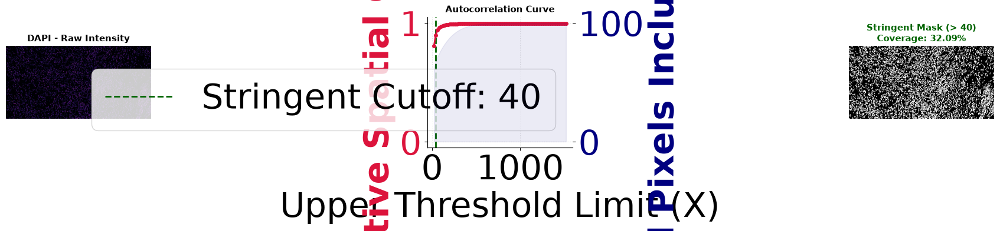

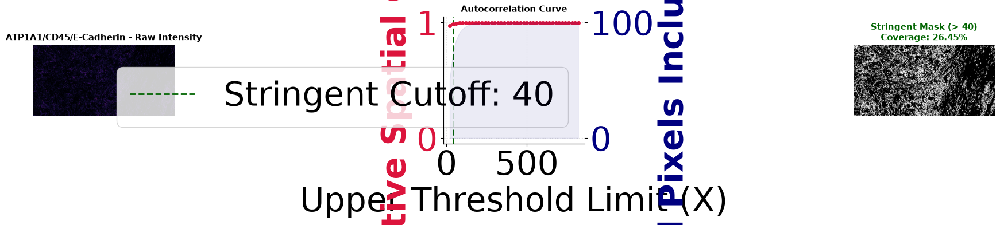

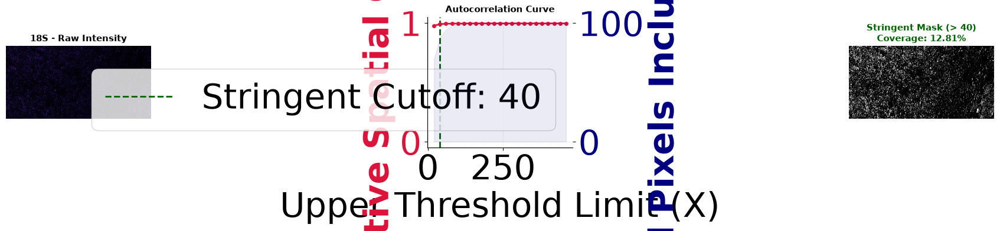

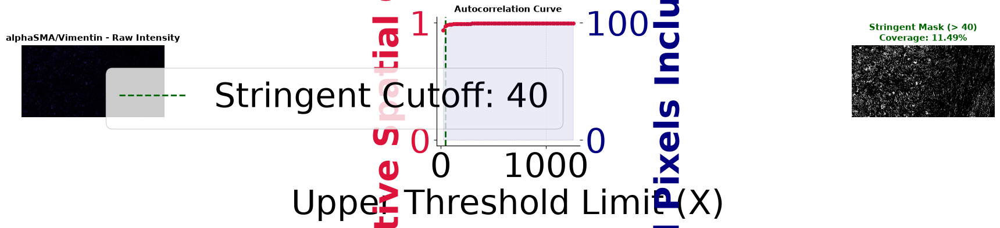

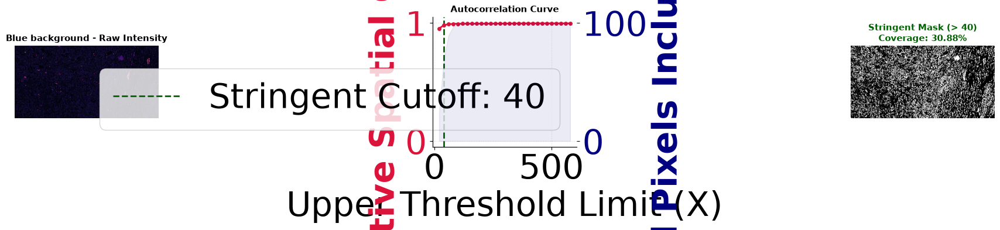

...

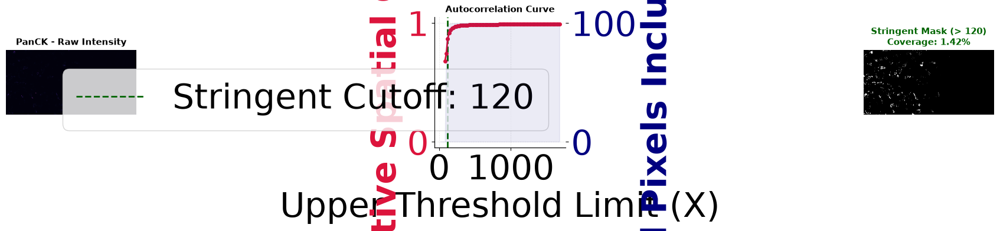

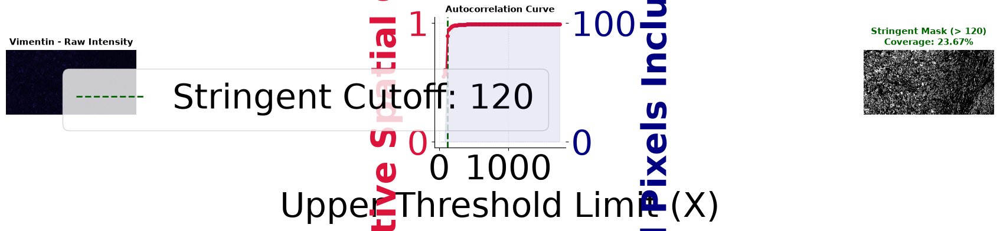

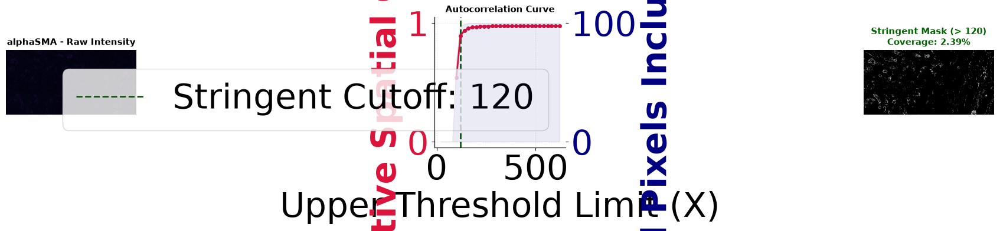

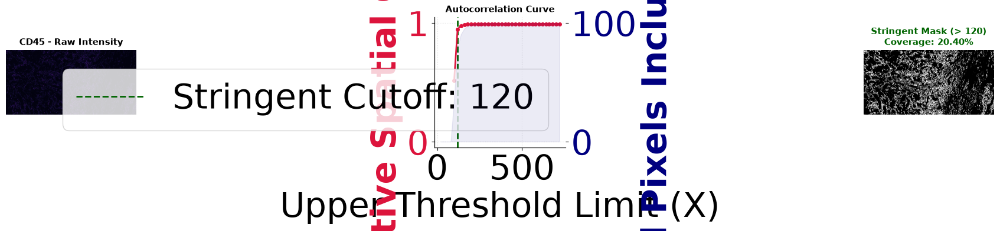

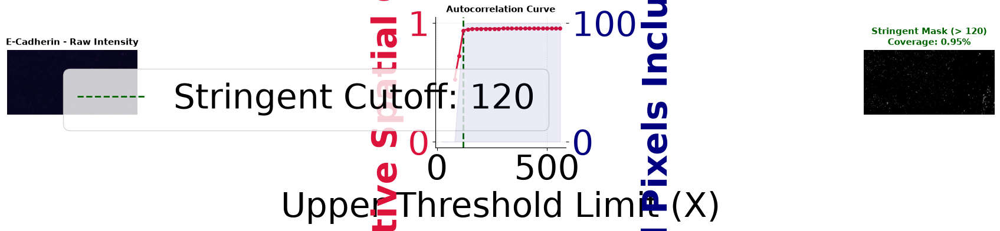

In [7]:
from pathlib import Path

# 1. Define where you want to save the diagnostic plots
# Change this path to wherever you want the output PNGs to land
# 2. Define your Region of Interest (ROI) using global transcript coordinates
# This 200x200 window is perfect for a fast, clear analysis
target_roi = (4000,5000,1500,2000) #(3500,6000,1000,3500)

# 3. Call the cumulative function
df_summary=analyze_channels_and_get_thresholds(
    sdata=sdata,                         # Your main SpatialData object
    image_key="morphology_focus",        # The key to your morphology image
    scale_key="scale0",                  # 'scale0' for full resolution
    roi=target_roi,                      # Your spatial bounding window
    cmap="magma",                        # Perceptually uniform colormap
    saving_path=saving_path,             # Directory where plots will be saved
    step_size=20, mode="stringent"      # Calculates windows: 0->100, 0->200, 0->300, etc.
)

In [8]:
import pandas as pd
import numpy as np

def compute_urna_percentages(sdata, df_summary, extracellular_key='extracellular', extracellular_value=True):
    # 1. Extract and compute the transcripts DataFrame efficiently
    transcripts_df = sdata['transcripts'][[extracellular_key, 'gene']].compute()
    transcripts_df.index = transcripts_df.index.astype(str)
    
    # Filter for target transcripts (e.g., extracellular == True or overlaps_cell == False)
    # properly mapping strings/booleans dynamically
    is_extracellular = transcripts_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    filtered_transcripts = transcripts_df[is_extracellular]
    
    # Compute global total number of uRNA for each gene
    # This serves as our denominator for df_values
    df_total_urna = filtered_transcripts.groupby('gene').size().to_frame(name='total_uRNA')
    
    # 2. Extract the AnnData info
    intensity_adata = sdata['image_intensity_per_transcript']
    channels = intensity_adata.var_names.tolist()
    
    if hasattr(intensity_adata.X, "toarray"):
        intensities_matrix = intensity_adata.X.toarray()
    else:
        intensities_matrix = intensity_adata.X
        
    intensities_df = pd.DataFrame(
        intensities_matrix, 
        index=intensity_adata.obs_names.astype(str), 
        columns=channels
    )
    
    # 3. Join the datasets based on the transcript index
    # We join on filtered_transcripts so we only track the relevant subset moving forward
    merged_df = filtered_transcripts.join(intensities_df, how='inner')
    
    # 4. Prepare the reference dictionary for thresholds
    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    
    # Initialize dictionary to collect raw counts
    freqs_dict = {}  
    unique_genes = merged_df['gene'].unique()
    
    # 5. Calculate absolute uRNA counts per channel
    for channel in channels:
        if channel not in threshold_dict:
            continue
            
        threshold = threshold_dict[channel]
        
        # Filter for rows where intensity exceeds the channel threshold
        is_positive_area = merged_df[channel] > threshold
        pos_df = merged_df[is_positive_area]
        
        # Count occurrences per gene within the positive zone
        urna_in_pos = pos_df.groupby('gene').size()
        
        # Save absolute counts
        freqs_dict[channel] = urna_in_pos
        
    # 6. Format into final DataFrames
    df_freqs = pd.DataFrame(freqs_dict, index=unique_genes).fillna(0)
    
    # Clean up total uRNA dataframe index to match unique_genes
    df_total_urna = df_total_urna.reindex(unique_genes).fillna(0)
    
    # --- DF_VALUES EVALUATION ---
    # Divide the local counts per channel by the global uRNA total for each gene
    df_values = df_freqs.div(df_total_urna['total_uRNA'], axis=0) * 100
    df_values = df_values.fillna(0)  # Handle any division-by-zero safely
    
    # Clean up index names and data types
    df_freqs.index.name = 'gene'
    df_values.index.name = 'gene'
    df_total_urna.index.name = 'gene'
    df_total_urna = df_total_urna.astype(int)
    
    return df_freqs, df_values, df_total_urna

In [9]:
df_freqs, df_values, df_total_urna = compute_urna_percentages(sdata, df_summary,extracellular_key='overlaps_cell', extracellular_value=False)
df_freqs_extra, df_values_extra, df_total_urna_extra = compute_urna_percentages(sdata, df_summary,extracellular_key='extracellular', extracellular_value=True)

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def filter_and_plot_urna(df_freqs, df_values, df_total_urna, n_counts=10, cmap='YlGnBu'):
    """
    Filters the precomputed uRNA dataframes based on a minimum global count threshold
    and generates a heatmap visualization.
    
    Parameters:
    - df_freqs: DataFrame of absolute uRNA counts per channel.
    - df_values: DataFrame of % of gene uRNA inside each channel.
    - df_total_urna: DataFrame of global total uRNA per gene.
    - n_counts: Minimum threshold of global uRNA counts required to keep a gene.
    - cmap: Colormap for the heatmap.
    
    Returns:
    - df_freqs_filtered, df_values_filtered, df_total_urna_filtered
    """
    # 1. Identify genes that meet the expression cutoff from the total counts
    passing_genes = df_total_urna[df_total_urna['total_uRNA'] >= n_counts].index
    
    # 2. Filter all 3 dataframes simultaneously using the passing genes
    df_freqs_filtered = df_freqs.loc[df_freqs.index.isin(passing_genes)]
    df_values_filtered = df_values.loc[df_values.index.isin(passing_genes)]
    df_total_urna_filtered = df_total_urna.loc[df_total_urna.index.isin(passing_genes)]
    
    print(f"--- Filtering Summary (Threshold: >= {n_counts} global counts) ---")
    print(f"Original unique genes: {len(df_total_urna)}")
    print(f"Genes matching criteria: {len(passing_genes)}")
    print(f"Filtered out: {len(df_total_urna) - len(passing_genes)} genes\n")
    
    if df_values_filtered.empty:
        print("Warning: The filtered DataFrame is empty. Try lowering n_counts.")
        return df_freqs_filtered, df_values_filtered, df_total_urna_filtered

    
    return df_freqs_filtered, df_values_filtered, df_total_urna_filtered


In [11]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.affinity import affine_transform

def compute_spatial_pixel_sharing(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries"
):
    """
    Calculates the percentage of positive pixels inside vs outside cells 
    for each channel using a manual isotropic scaling transformation.
    """
    print("=== STEP 1: Transcript Global Ranges ===")
    trans_df = sdata['transcripts'][['x', 'y']].compute()
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin
    print(f"Global Transcripts Bounds -> X: [{t_xmin:.2f} to {t_xmax:.2f}] (Delta: {t_dx:.2f})")
    print(f"Global Transcripts Bounds -> Y: [{t_ymin:.2f} to {t_ymax:.2f}] (Delta: {t_dy:.2f})")

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # Expecting (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]
    print(f"Raw Image Shape (c, y, x): {img_shape}")

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    # Calculate scale factor between the spatial bounding span vs the pixel canvas dimensions
    scale_x = img_w / t_dx
    scale_y = img_h / t_dy
    # Averaging to match identical proportional isotropic scaling
    scale_factor = (scale_x + scale_y) / 2
    print(f"Calculated Scale Factor (Pixels per Spatial Unit): {scale_factor:.5f}")

    print("\n=== STEP 4: Manual Geometry Transformation ===")
    # Load cell boundaries directly into a GeoDataFrame
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")

    # Mirror your manual transform matrix: Shift to 0,0 baseline and scale up to pixel grid
    # x_pixel = (x - t_xmin) * scale_factor
    # y_pixel = (y - t_ymin) * scale_factor
    # Affine matrix format: [a, b, d, e, xoff, yoff]
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    print("\n=== STEP 5: Generating Binary Cell Mask ===")
    # Use OpenCV to rasterize the transformed polygons directly into a pixel grid
    import cv2
    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: 
            continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    # Total area metrics
    total_pixels_inside = np.sum(cell_mask == 1)
    total_pixels_outside = np.sum(cell_mask == 0)
    print(f"Cell Mask Generated -> Pixels Inside: {total_pixels_inside} | Pixels Outside: {total_pixels_outside}")

    # Extract existing channel coordinate markers
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 6: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        
        # Pull single channel slice into memory safely
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        # Calculate boolean mask of pixels strictly exceeding threshold
        pos_mask = img_np > threshold
        
        # Intersect threshold mask with cellular compartments
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_outside = np.sum((pos_mask == True) & (cell_mask == 0))
        
        # Calculate final percentages based on total available pixels in that compartment
        pct_inside = (pos_inside / total_pixels_inside) * 100 if total_pixels_inside > 0 else 0
        pct_outside = (pos_outside / total_pixels_outside) * 100 if total_pixels_outside > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Outside Cells / Extracellular)": pct_outside
        })
        print(f"-> {ch_name}: Inside={pct_inside:.2f}%, Outside (Extracellular)={pct_outside:.2f}%")
        
    df_spatial_summary = pd.DataFrame(spatial_results)
    print("\n✓ Spatial threshold breakdown completed successfully.")
    return df_spatial_summary

In [12]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from shapely.affinity import affine_transform
import cv2

def compute_spatial_pixel_sharing_with_cell_like(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries",
    extracellular_key: str = "extracellular",
    extracellular_value: bool = False,
    overlaps_cell_key: str = "overlaps_cell",
    overlaps_cell_value: bool = False,
    cell_like_dilation_radius: int = 15,
    show_viz: bool = True
):
    """
    Calculates the percentage of positive pixels across 3 compartments:
    Inside Cells, Cell-Like Regions (Unsegmented), and True Extracellular space.
    Includes a diagnostic visualization of the generated masks.
    """
    print("=== STEP 1: Transcript Global Ranges & Filtering ===")
    trans_df = sdata['transcripts'][['x', 'y', extracellular_key, overlaps_cell_key]].compute()
    trans_df.index = trans_df.index.astype(str)
    
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    scale_factor = ((img_w / t_dx) + (img_h / t_dy)) / 2

    print("\n=== STEP 4: Creating Mask 1 - Inside Cells ===")
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    print("\n=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===")
    # Filter using string-safe matching for whatever values you pass down
    is_extra_match = trans_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    is_cell_match = trans_df[overlaps_cell_key].astype(str).str.lower() == str(overlaps_cell_value).lower()
    
    cell_like_transcripts = trans_df[is_extra_match & is_cell_match]
    print(f"Found {len(cell_like_transcripts)} cell-like transcripts matching target criteria.")
    
    # Map points to pixel grid space
    cl_x_pixel = np.clip(((cell_like_transcripts['x'] - t_xmin) * scale_factor).astype(int), 0, img_w - 1)
    cl_y_pixel = np.clip(((cell_like_transcripts['y'] - t_ymin) * scale_factor).astype(int), 0, img_h - 1)
    
    # Rasterize points and dilate to form regional structural masks
    cell_like_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    cell_like_mask[cl_y_pixel, cl_x_pixel] = 1
    
    if cell_like_dilation_radius > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (cell_like_dilation_radius, cell_like_dilation_radius))
        cell_like_mask = cv2.dilate(cell_like_mask, kernel)
    
    # Enforce priority rules (Segmented cell boundaries override cell-like transcripts)
    cell_like_mask[cell_mask == 1] = 0

    print("\n=== STEP 6: Creating Mask 3 - True Extracellular Space ===")
    true_extracellular_mask = np.where((cell_mask == 0) & (cell_like_mask == 0), 1, 0).astype(np.uint8)

    # Compute total area metrics per compartment
    total_inside = np.sum(cell_mask == 1)
    total_cell_like = np.sum(cell_like_mask == 1)
    total_true_extra = np.sum(true_extracellular_mask == 1)
    
    print(f"-> Compartment Areas (Pixels) | Inside Cells: {total_inside} | Cell-Like: {total_cell_like} | True Extracellular: {total_true_extra}")

    # --- Diagnostic Visualization ---
    if show_viz:
        print("\n=== Rendering Spatial Compartment Visualization ===")
        viz_map = np.zeros((img_h, img_w), dtype=np.uint8)
        viz_map[true_extracellular_mask == 1] = 0
        viz_map[cell_like_mask == 1] = 1
        viz_map[cell_mask == 1] = 2
        
        fig, ax = plt.subplots(figsize=(6, 6))
        cmap_custom = ListedColormap(['#ECEFF1', '#FFCC80', '#90CAF9'])  # Gray=Extra, Orange=Cell-Like, Blue=Inside Cell
        
        im = ax.imshow(viz_map, cmap=cmap_custom, origin='lower')
        ax.set_title("Generated Spatial Compartment Masks", fontweight='bold')
        ax.axis('off')
        
        cbar = plt.colorbar(im, ax=ax, ticks=[0.33, 1.0, 1.66], fraction=0.046, pad=0.04)
        cbar.ax.set_yticklabels(['True Extracellular', 'Cell-Like Region', 'Inside Cell'])
        plt.show()

    # --- Step 7: Signal Intensity Analysis ---
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 7: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        pos_mask = img_np > threshold
        
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_cell_like = np.sum((pos_mask == True) & (cell_like_mask == 1))
        pos_true_extra = np.sum((pos_mask == True) & (true_extracellular_mask == 1))
        
        pct_inside = (pos_inside / total_inside) * 100 if total_inside > 0 else 0
        pct_cell_like = (pos_cell_like / total_cell_like) * 100 if total_cell_like > 0 else 0
        pct_true_extra = (pos_true_extra / total_true_extra) * 100 if total_true_extra > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Cell-Like Regions)": pct_cell_like,
            "% Positive Pixels (True Extracellular)": pct_true_extra
        })
        print(f"-> {ch_name}: Inside={pct_inside:.1f}% | Cell-Like={pct_cell_like:.1f}% | True Extra={pct_true_extra:.1f}%")
        
    return pd.DataFrame(spatial_results)

=== STEP 1: Transcript Global Ranges & Filtering ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Creating Mask 1 - Inside Cells ===

=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===
Found 1078751 cell-like transcripts matching target criteria.

=== STEP 6: Creating Mask 3 - True Extracellular Space ===
-> Compartment Areas (Pixels) | Inside Cells: 84526173 | Cell-Like: 1002480 | True Extracellular: 64471347

=== Rendering Spatial Compartment Visualization ===


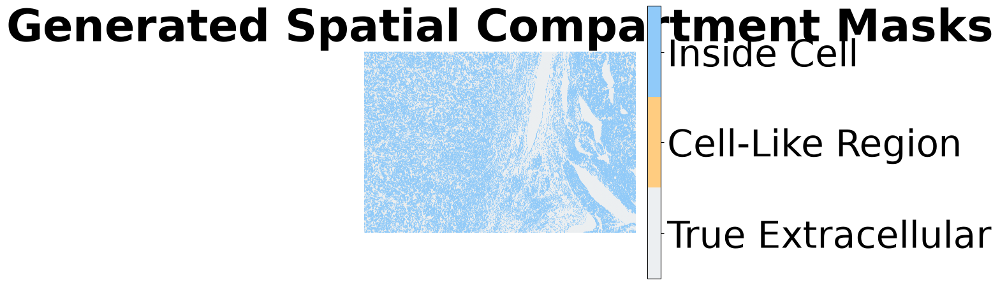


=== STEP 7: Processing Channels and Computing Compartment Positivity ===
-> DAPI: Inside=44.6% | Cell-Like=2.3% | True Extra=1.2%
-> ATP1A1/CD45/E-Cadherin: Inside=34.7% | Cell-Like=30.5% | True Extra=12.2%
-> 18S: Inside=26.1% | Cell-Like=25.8% | True Extra=6.1%
-> alphaSMA/Vimentin: Inside=16.4% | Cell-Like=21.9% | True Extra=7.7%
-> Blue background: Inside=41.8% | Cell-Like=16.3% | True Extra=6.9%
-> Green background: Inside=0.0% | Cell-Like=0.0% | True Extra=0.0%
-> Yellow background: Inside=0.0% | Cell-Like=0.1% | True Extra=0.1%
-> Red background: Inside=1.4% | Cell-Like=1.7% | True Extra=1.4%
-> CD4: Inside=99.7% | Cell-Like=99.9% | True Extra=99.9%
-> CD20: Inside=0.4% | Cell-Like=0.1% | True Extra=0.1%
-> CD8A: Inside=9.3% | Cell-Like=3.3% | True Extra=2.0%
-> CD3E: Inside=99.7% | Cell-Like=99.6% | True Extra=99.6%
-> CD138: Inside=99.5% | Cell-Like=99.8% | True Extra=99.9%
-> HLA-DR: Inside=13.6% | Cell-Like=13.5% | True Extra=5.0%
-> CD11c: Inside=0.4% | Cell-Like=0.3% | Tr

In [13]:
df_spatial_summary = compute_spatial_pixel_sharing_with_cell_like(
    sdata=sdata,
    df_summary=df_summary,
    image_key="morphology_focus",
    shapes_key="cell_boundaries",
    extracellular_key="extracellular",
    extracellular_value=False,
    overlaps_cell_key="overlaps_cell",
    overlaps_cell_value=False,
    cell_like_dilation_radius=0,  # Radius in pixels to grow around unsegmented transcripts
    show_viz=True
)

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_spatial_compartment_summary(df_spatial_summary: pd.DataFrame, title: str = "Signal Positivity Across Spatial Compartments"):
    """
    Creates a grouped horizontal bar chart visualizing the percentage of positive pixels 
    across Inside Cells, Cell-Like Regions, and True Extracellular space.
    """
    # 1. Melt the DataFrame from wide to long format for Seaborn compatibility
    melt_cols = [
        "% Positive Pixels (Inside Cells)", 
        "% Positive Pixels (Cell-Like Regions)", 
        "% Positive Pixels (True Extracellular)"
    ]
    
    # Ensure columns exist before melting
    available_cols = [col for col in melt_cols if col in df_spatial_summary.columns]
    
    df_long = df_spatial_summary.melt(
        id_vars=["Channel Name"], 
        value_vars=available_cols,
        var_name="Compartment", 
        value_name="Percent Positive Pixels"
    )
    
    # 2. Clean up the legend labels for display readability
    df_long["Compartment"] = df_long["Compartment"].str.extract(r"\((.*?)\)")

    # 3. Initialize the plot (Adjusted figsize to fit a vertical stack of channels comfortably)
    fig, ax = plt.subplots(figsize=(10, 12))
    
    # Use an elegant color scheme matching the spatial mask visualization palette
    palette_dict = {
        "Inside Cells": "#90CAF9",          # Blue
        "Cell-Like Regions": "#FFCC80",     # Orange
        "True Extracellular": "#90A4AE"     # Muted Gray-Blue
    }
    
    # SHIFT AXES: Assign 'Channel Name' to y and 'Percent Positive Pixels' to x
    sns.barplot(
        data=df_long, 
        y="Channel Name", 
        x="Percent Positive Pixels", 
        hue="Compartment", 
        palette=palette_dict,
        edgecolor="black",
        linewidth=0.7,
        ax=ax
    )
    
    # 4. Refine structural aesthetics
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_axisbelow(True)
    
    # Shift background grid line orientation to help match horizontal trends
    ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
    
    # ROTATE CHANNEL TICKS: Because channel labels are now on the Y axis, we rotate yticks instead.
    # Adjust rotation degrees (e.g., 45 or 0) and alignment to suit your text layouts.
    ax.set_yticklabels(ax.get_yticklabels(), rotation=30, ha="right")
    
    # Titles and Label refinement (Swapped axis descriptive text labels)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_ylabel("Imaging Channels", fontsize=12, labelpad=10)
    ax.set_xlabel("% Area Exceeding Threshold", fontsize=12, labelpad=10)
    
    # Keep the bounds locked inside normal percentages along the horizontal line
    ax.set_xlim(0, max(df_long["Percent Positive Pixels"].max() * 1.15, 10))
    
    # Finalize Layout layout
    plt.legend(frameon=False, loc="upper right", title="Compartment")
    plt.tight_layout()
    plt.show()

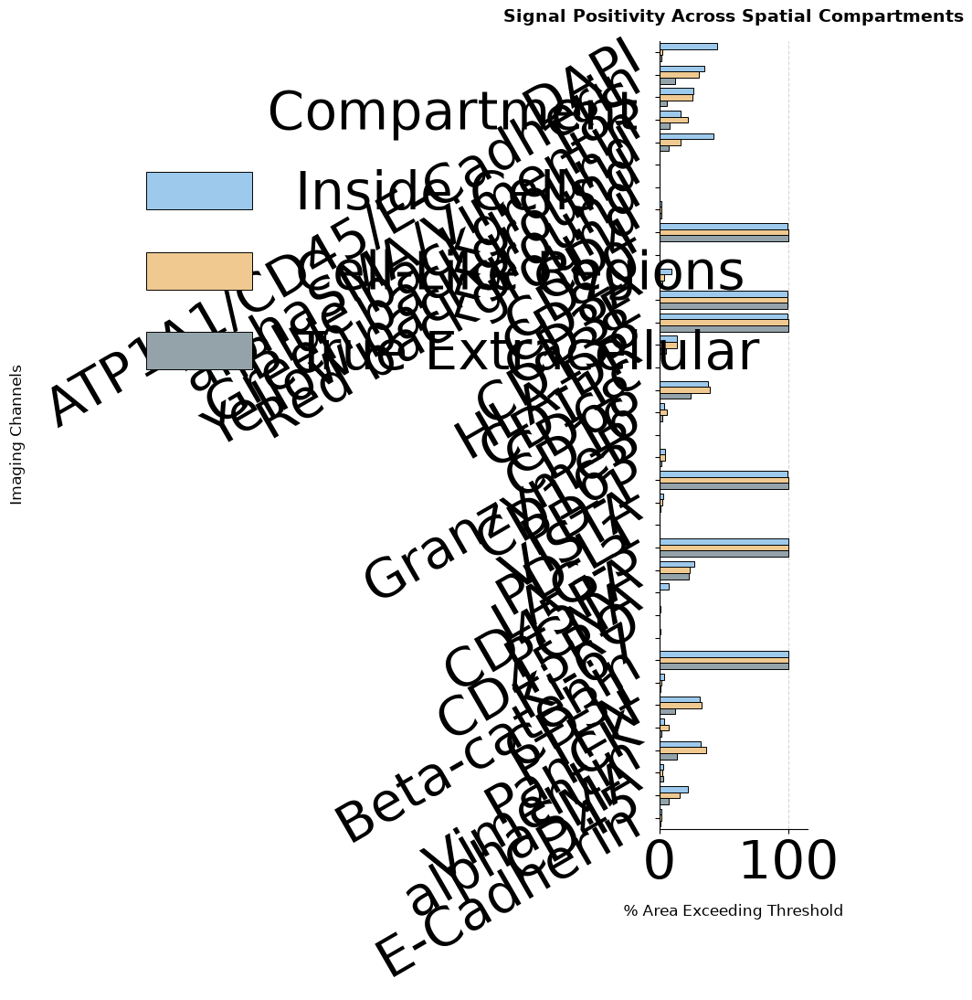

In [15]:
plot_spatial_compartment_summary(df_spatial_summary)

In [16]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

def metric_scatter_extracellular(
    df_values: pd.DataFrame,
    df_spatial_summary: pd.DataFrame,
    x: str,
    y: str,
    x_baselines: list[str] = ["% Positive Pixels (True Extracellular)"],
    y_baselines: list[str] = ["% Positive Pixels (True Extracellular)"],
    size: int = 15,
    label_top_n_x: int = 0,
    label_top_n_y: int = 0,
    label_bottom_n_x: int = 0,
    label_bottom_n_y: int = 0,
    title: str | None = None,
    linewidth: float = 0.5,
    figures_path: str = "",
    save: bool = False,
    custom_plot_filename: str = None,
    dot_color: str = "#1E90FF",
    gene_label: str = "Gene probes",
) -> None:
    """
    Creates a scatter plot comparing uRNA percentages of two specified channels (x and y).
    Draws custom horizontal and vertical lines indicating expected random positivity thresholds
    for multiple specified compartments from df_spatial_summary.
    """
    # --- Illustrator Editability Settings ---
    mpl.rcParams['pdf.fonttype'] = 42  
    mpl.rcParams['ps.fonttype'] = 42   

    # 1. Clean and isolate data from the metrics matrix (df_values)
    if x not in df_values.columns or y not in df_values.columns:
        raise ValueError(f"Ensure both axis channels '{x}' and '{y}' exist as columns in df_values.")
        
    plot_df = df_values[[x, y]].copy()
    plot_df.dropna(subset=[x, y], inplace=True)

    # 2. Build the plot setup
    fig, ax = plt.subplots(figsize=(6, 6))
    
    ax.scatter(
        plot_df[x], plot_df[y], 
        color=dot_color, 
        edgecolor="black", 
        s=size, 
        linewidth=linewidth, 
        alpha=0.9,
        zorder=5  # Keep dots on top of all lines
    )

    # Clean up spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Filter spatial summary for the target channels
    x_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == x]
    y_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == y]

    # Assign distinct colors and styles if plotting multiple distinct compartment lines
    # Order matches: True Extracellular, Cell-Like Regions, Inside Cells
    style_palette = {
        "% Positive Pixels (True Extracellular)": {"color": "#DC143C", "ls": "--", "label": "True Extra"},
        "% Positive Pixels (Cell-Like Regions)": {"color": "#FF8C00", "ls": "-.", "label": "Cell-Like"},
        "% Positive Pixels (Inside Cells)": {"color": "#4169E1", "ls": ":", "label": "Inside Cell"}
    }
    
    # Track values to safely expand the plot limits later
    all_baseline_x_vals = []
    all_baseline_y_vals = []
    used_labels = set()

    # 3. Draw requested vertical lines (X-axis channels)
    if not x_summary.empty:
        for col in x_baselines:
            if col in x_summary.columns:
                val = x_summary[col].values[0]
                all_baseline_x_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axvline(x=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 4. Draw requested horizontal lines (Y-axis channels)
    if not y_summary.empty:
        for col in y_baselines:
            if col in y_summary.columns:
                val = y_summary[col].values[0]
                all_baseline_y_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axhline(y=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 5. Label Handling
    label_genes = set()
    if label_top_n_x > 0:
        label_genes.update(plot_df.nlargest(label_top_n_x, x).index)
    if label_top_n_y > 0:
        label_genes.update(plot_df.nlargest(label_top_n_y, y).index)
    if label_bottom_n_x > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_x, x).index)
    if label_bottom_n_y > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_y, y).index)

    texts = []
    for gene in label_genes:
        texts.append(
            ax.text(plot_df.loc[gene, x], plot_df.loc[gene, y], gene, fontsize=11, ha="right")
        )

    # 6. Graph limit bounding with dynamic baseline safe-padding
    x_min, x_max = plot_df[x].min(), plot_df[x].max()
    y_min, y_max = plot_df[y].min(), plot_df[y].max()
    
    if all_baseline_x_vals:
        x_min = min(x_min, min(all_baseline_x_vals))
        x_max = max(x_max, max(all_baseline_x_vals))
    if all_baseline_y_vals:
        y_min = min(y_min, min(all_baseline_y_vals))
        y_max = max(y_max, max(all_baseline_y_vals))

    x_padding = max((x_max - x_min) * 0.1, 5)
    y_padding = max((y_max - y_min) * 0.1, 5)

    ax.set_xlim(max(0, x_min - x_padding), min(105, x_max + x_padding))
    ax.set_ylim(max(0, y_min - y_padding), min(105, y_max + y_padding))

    if texts:
        adjust_text(texts, arrowprops={"arrowstyle": "-", "color": "black", "lw": 1})

    # 7. Label assignments
    ax.set_xlabel(f"{x.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)
    ax.set_ylabel(f"{y.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)

    if title:
        ax.set_title(title, fontsize=14, fontweight="bold")

    # 8. Dynamic Legend Generation
    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label=gene_label, markerfacecolor=dot_color, markeredgecolor="black", markersize=8)
    ]
    for color, ls, lbl in sorted(used_labels, key=lambda item: item[2]):
        legend_elements.append(Line2D([0], [0], color=color, linestyle=ls, linewidth=1.2, label=lbl))
        
    ax.legend(handles=legend_elements, loc="best", frameon=False)
    ax.tick_params(labelsize=10)

    if save:
        fig_dir = Path(figures_path)
        fig_dir.mkdir(parents=True, exist_ok=True)
        plot_filename = custom_plot_filename or f"{x}_vs_{y}_compartments_scatter.pdf"
        plt.savefig(fig_dir / plot_filename, bbox_inches="tight")

    plt.show()

In [17]:
selgenes=sdata['xrna_metadata'].var[sdata['xrna_metadata'].var['logfoldchange_over_noise']>0.1].index
df_v=df_values[df_values.index.isin(selgenes)]
print(df_v.shape)

(64, 35)


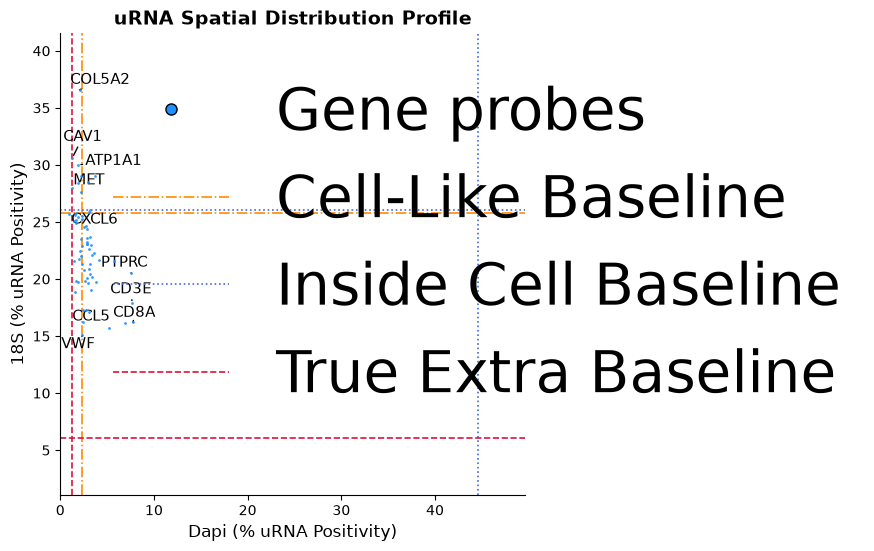

ValueError: Ensure both axis channels 'AlphaSMA/Vimentin' and '18S' exist as columns in df_values.

In [ ]:
metric_scatter_extracellular( df_values=df_v,
    df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    x='DAPI', y='CD8', label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,
    x='AlphaSMA/Vimentin', y='18S',x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    x='AlphaSMA/Vimentin', y='DAPI',
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

In [20]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

def metric_stripplot_extracellular(
    df_values: pd.DataFrame,
    df_spatial_summary: pd.DataFrame,
    channel: str,
    baselines: list[str] = [
        "% Positive Pixels (True Extracellular)",
        "% Positive Pixels (Cell-Like Regions)",
        "% Positive Pixels (Inside Cells)"
    ],
    size: int = 15,
    label_top_n: int = 0,
    label_bottom_n: int = 0,
    title: str | None = None,
    linewidth: float = 0.5,
    figures_path: str = "",
    save: bool = False,
    custom_plot_filename: str = None,
    dot_color: str = "#1E90FF",
    gene_label: str = "Gene probes",
    jitter_width: float = 0.18,      # <-- ADDED: Control your point spread width
    label_fontsize: int = 10,       # <-- ADDED: Control text label size
) -> None:
    """
    Creates a 1D stripplot tracking uRNA percentages for a single specified channel.
    Draws custom horizontal baseline lines indicating expected random positivity thresholds.
    """
    # --- Illustrator Editability Settings ---
    mpl.rcParams['pdf.fonttype'] = 42  
    mpl.rcParams['ps.fonttype'] = 42   

    # 1. Clean and isolate data from the metrics matrix (df_values)
    if channel not in df_values.columns:
        raise ValueError(f"Ensure target channel '{channel}' exists as a column in df_values.")
        
    plot_df = df_values[[channel]].copy()
    plot_df.dropna(subset=[channel], inplace=True)

    # Generate explicit horizontal jitter centered at x=0 using adjustable bounds
    np.random.seed(42)  
    plot_df['x_jitter'] = np.random.uniform(-jitter_width, jitter_width, size=len(plot_df))

    # 2. Build the plot setup
    fig, ax = plt.subplots(figsize=(4, 6))
    
    ax.scatter(
        plot_df['x_jitter'], plot_df[channel], 
        color=dot_color, 
        edgecolor="black", 
        s=size, 
        linewidth=linewidth, 
        alpha=0.9,
        zorder=5  
    )

    # Clean up spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)  

    # Filter spatial summary for the target channel
    channel_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == channel]

    # Assign distinct colors and styles
    style_palette = {
        "% Positive Pixels (True Extracellular)": {"color": "#DC143C", "ls": "--", "label": "True Extra"},
        "% Positive Pixels (Cell-Like Regions)": {"color": "#FF8C00", "ls": "-.", "label": "Cell-Like"},
        "% Positive Pixels (Inside Cells)": {"color": "#4169E1", "ls": ":", "label": "Inside Cell"}
    }
    
    all_baseline_vals = []
    used_labels = set()

    # 3. Draw requested horizontal baseline lines
    if not channel_summary.empty:
        for col in baselines:
            if col in channel_summary.columns:
                val = channel_summary[col].values[0]
                all_baseline_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axhline(y=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 4. Label Handling with Adjustable Font Properties
    label_genes = set()
    if label_top_n > 0:
        label_genes.update(plot_df.nlargest(label_top_n, channel).index)
    if label_bottom_n > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n, channel).index)

    texts = []
    for gene in label_genes:
        texts.append(
            ax.text(
                plot_df.loc[gene, 'x_jitter'], 
                plot_df.loc[gene, channel], 
                gene, 
                fontsize=label_fontsize,   # Adjustable size
                fontweight="regular",      # Explicitly regular, not bold
                ha="right"
            )
        )

    # 5. Graph limit bounding with dynamic baseline safe-padding
    y_min, y_max = plot_df[channel].min(), plot_df[channel].max()
    if all_baseline_vals:
        y_min = min(y_min, min(all_baseline_vals))
        y_max = max(y_max, max(all_baseline_vals))

    y_padding = max((y_max - y_min) * 0.1, 5)

    # Set boundaries dynamically wider than the jitter range to keep dots inside gracefully
    ax.set_xlim(-max(0.5, jitter_width * 1.5), max(0.5, jitter_width * 1.5))  
    ax.set_ylim(max(0, y_min - y_padding), min(105, y_max + y_padding))

    if texts:
        adjust_text(texts, arrowprops={"arrowstyle": "-", "color": "black", "lw": 1})

    # 6. Axis adjustments 
    ax.set_xticks([0])
    ax.set_xticklabels([channel.replace('_', ' ').title()], fontsize=12, fontweight="bold")
    ax.set_ylabel("% uRNA Positivity", fontsize=12)

    if title:
        ax.set_title(title, fontsize=14, fontweight="bold")

    # 7. Dynamic Legend Generation
    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label=gene_label, markerfacecolor=dot_color, markeredgecolor="black", markersize=8)
    ]
    for color, ls, lbl in sorted(used_labels, key=lambda item: item[2]):
        legend_elements.append(Line2D([0], [0], color=color, linestyle=ls, linewidth=1.2, label=lbl))
        
    ax.legend(handles=legend_elements, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
    ax.tick_params(labelsize=10)

    # 8. File Export
    if save:
        fig_dir = Path(figures_path)
        fig_dir.mkdir(parents=True, exist_ok=True)
        
        safe_channel_name = channel.replace("/", "_")
        plot_filename = custom_plot_filename or f"{safe_channel_name}_compartments_stripplot.pdf"
        
        plt.savefig(fig_dir / plot_filename, bbox_inches="tight")

    plt.show()

In [26]:
plt.rc('figure', figsize=(10, 6), dpi=150, autolayout=True)
# Grouped font settings
plt.rc('font', size=10, family='sans-serif')

Processing stripplot for channel: DAPI


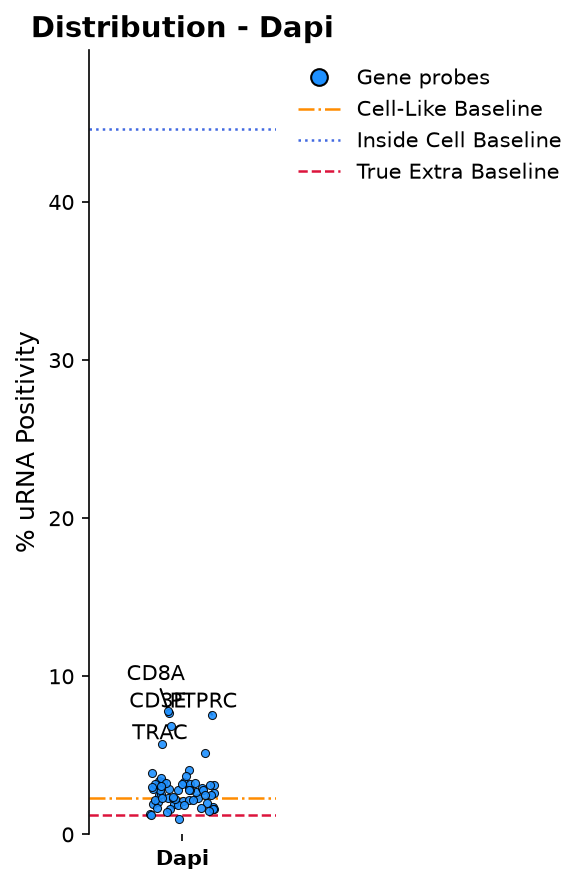

Processing stripplot for channel: ATP1A1/CD45/E-Cadherin


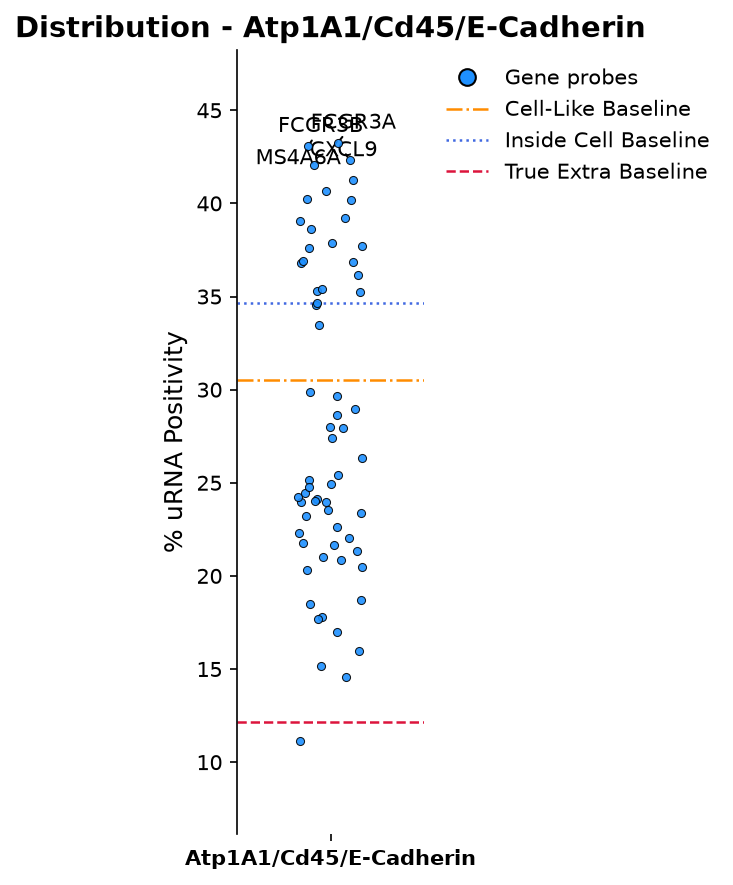

Processing stripplot for channel: 18S


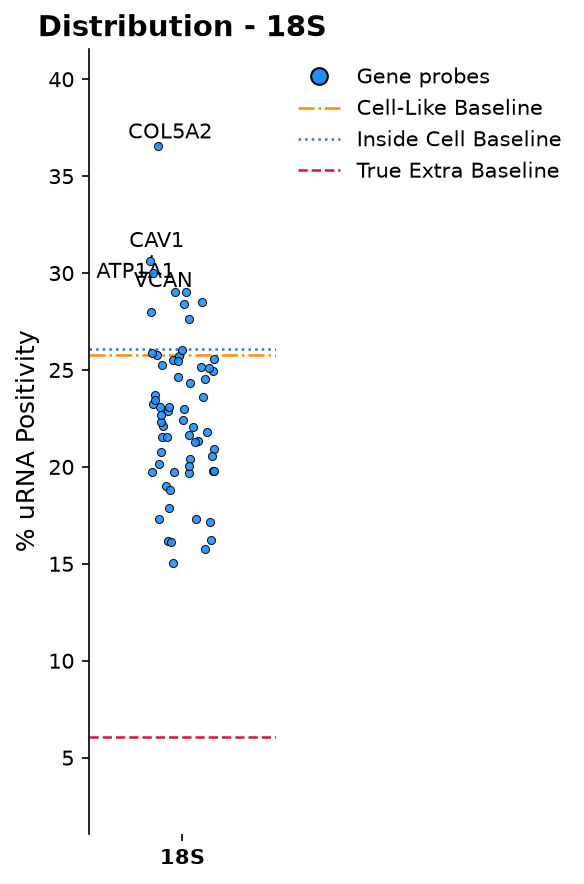

Processing stripplot for channel: alphaSMA/Vimentin


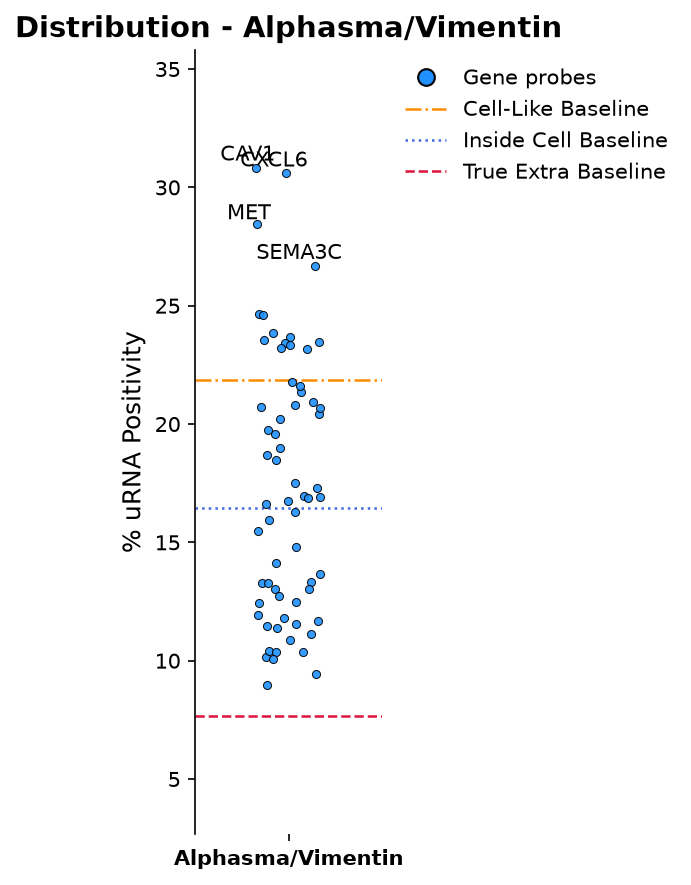

Processing stripplot for channel: Blue background


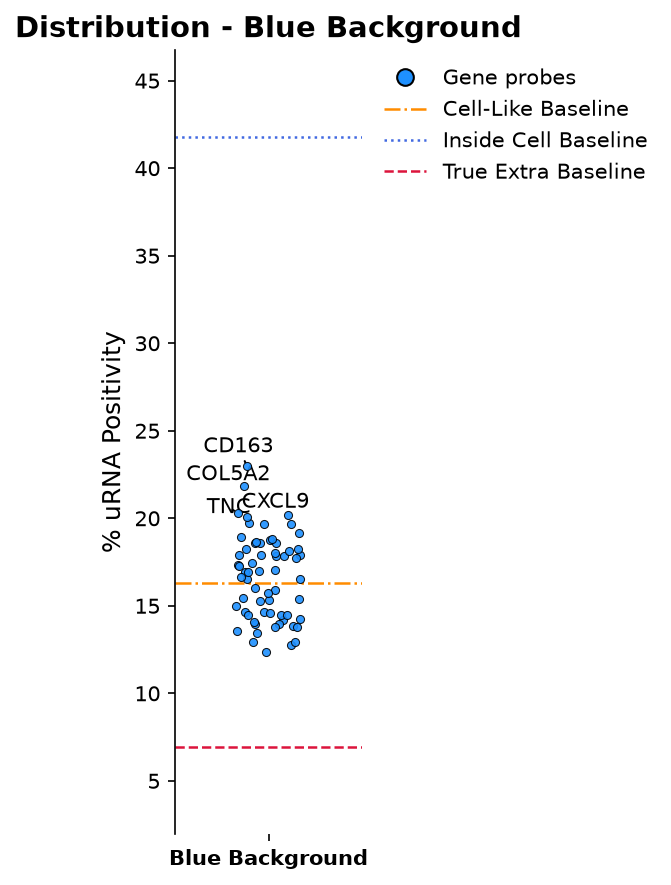

Processing stripplot for channel: Green background


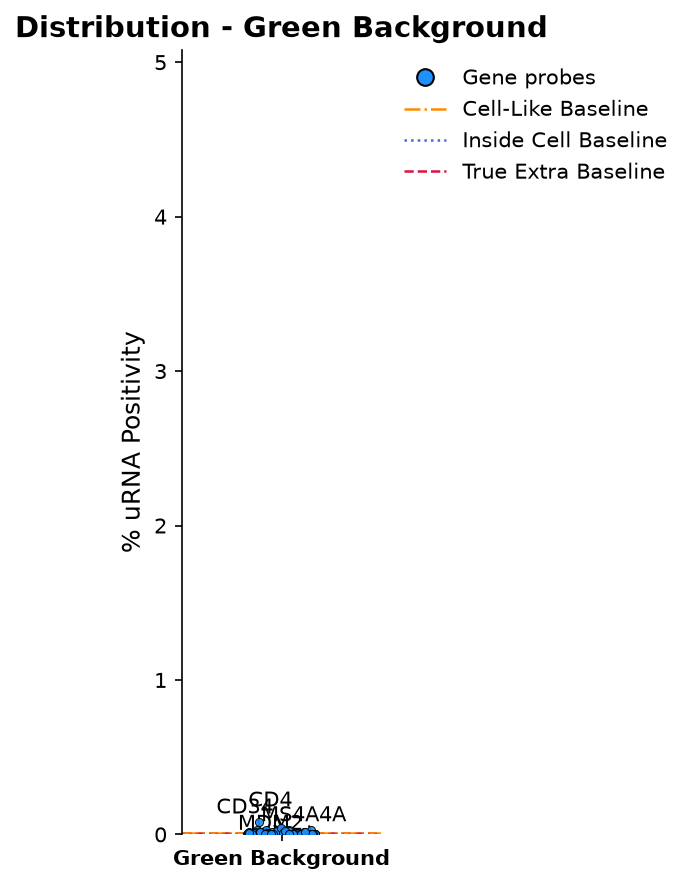

Processing stripplot for channel: Yellow background


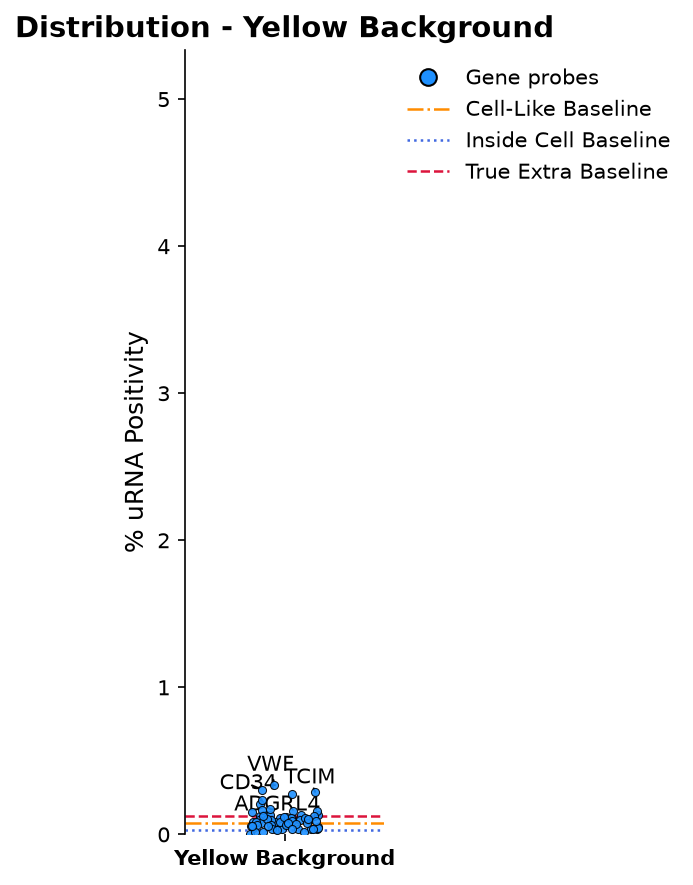

Processing stripplot for channel: Red background


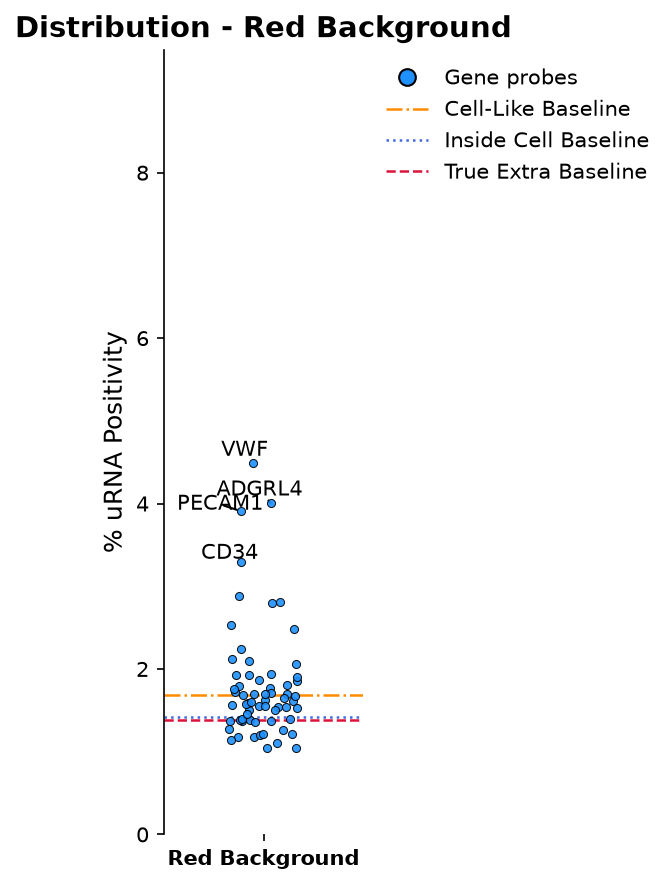

Processing stripplot for channel: CD4


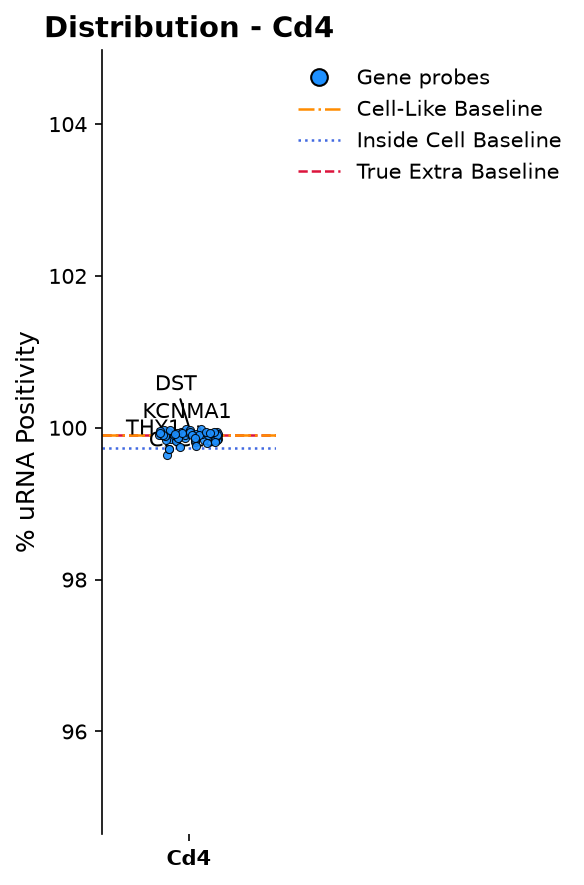

Processing stripplot for channel: CD20


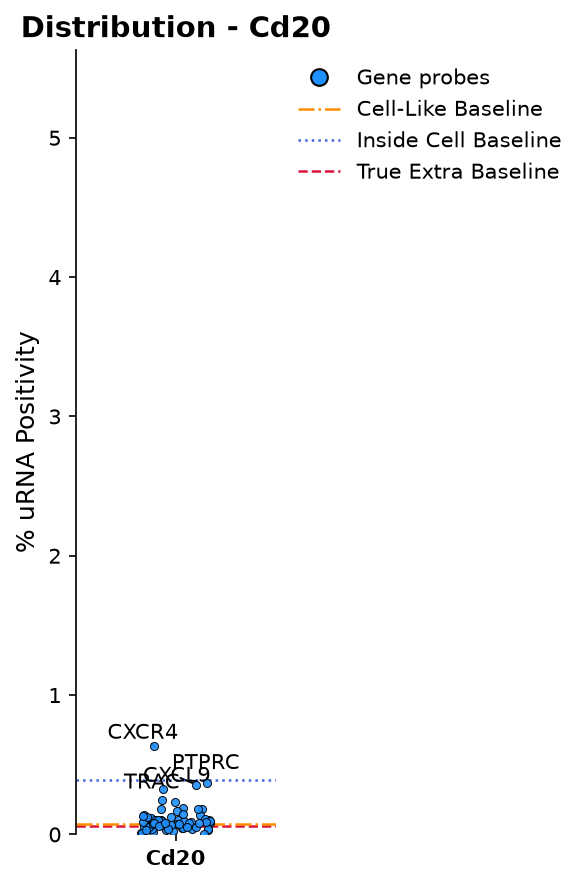

Processing stripplot for channel: CD8A


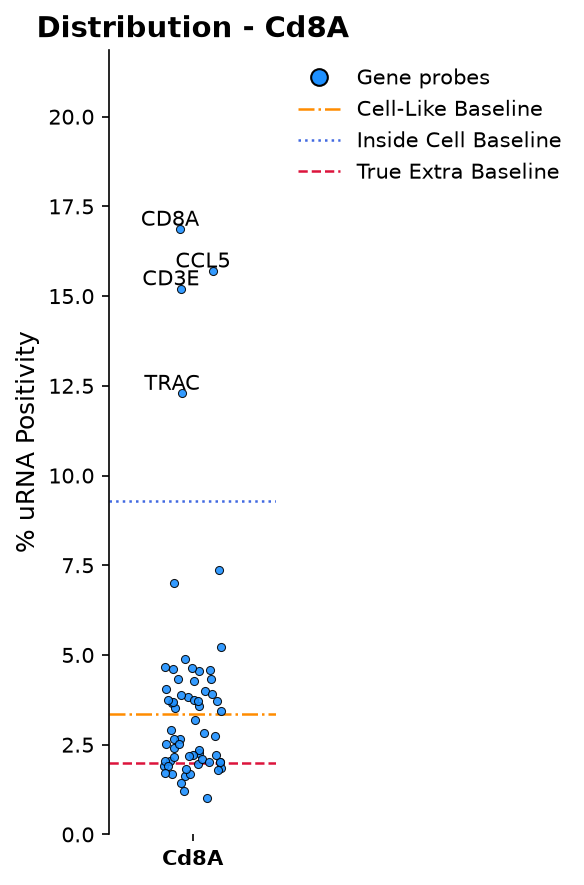

Processing stripplot for channel: CD3E


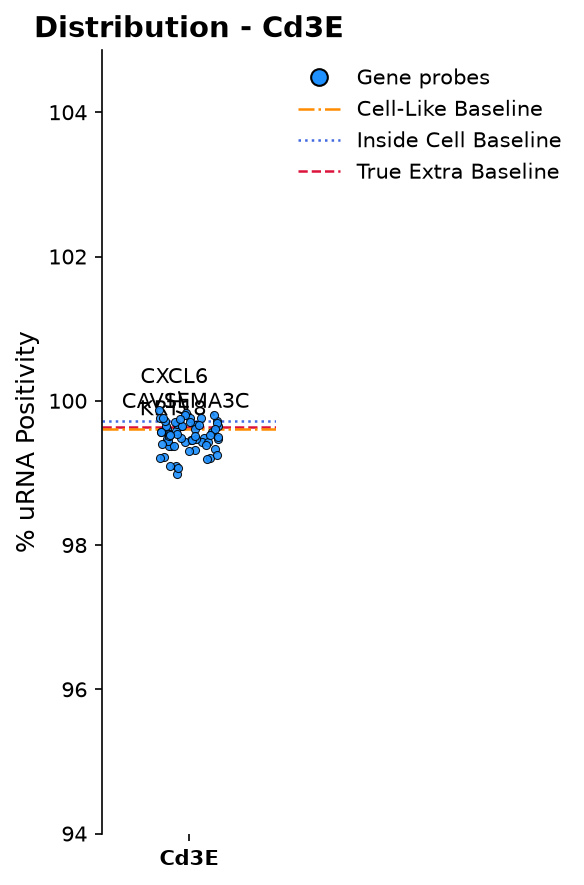

Processing stripplot for channel: CD138


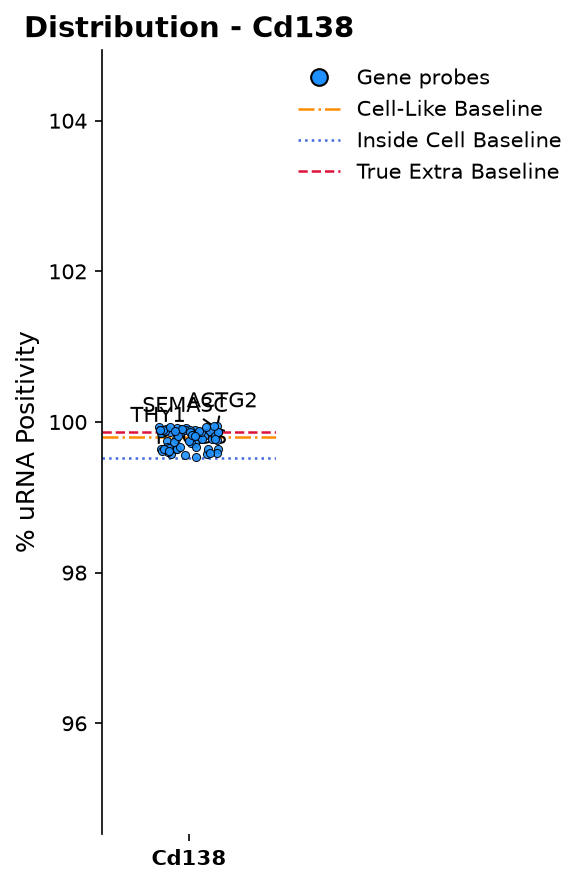

Processing stripplot for channel: HLA-DR


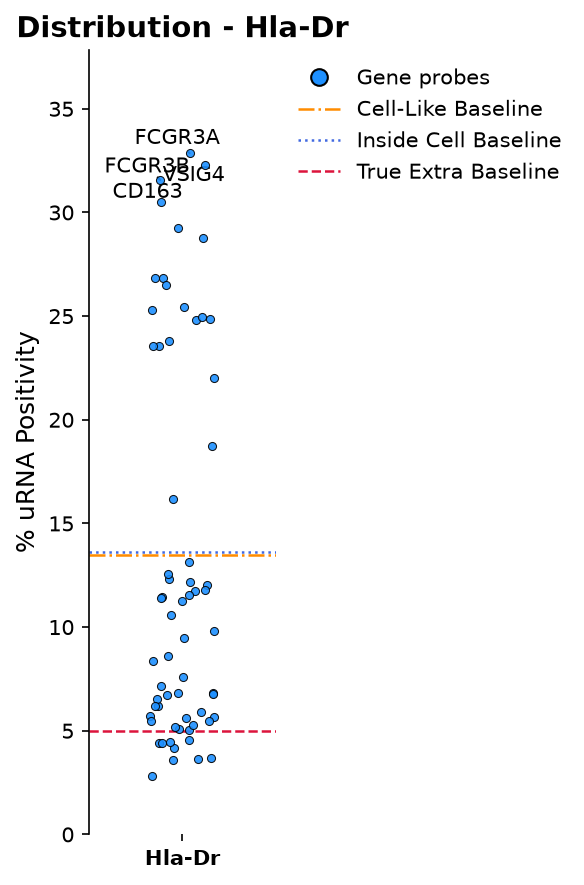

Processing stripplot for channel: CD11c


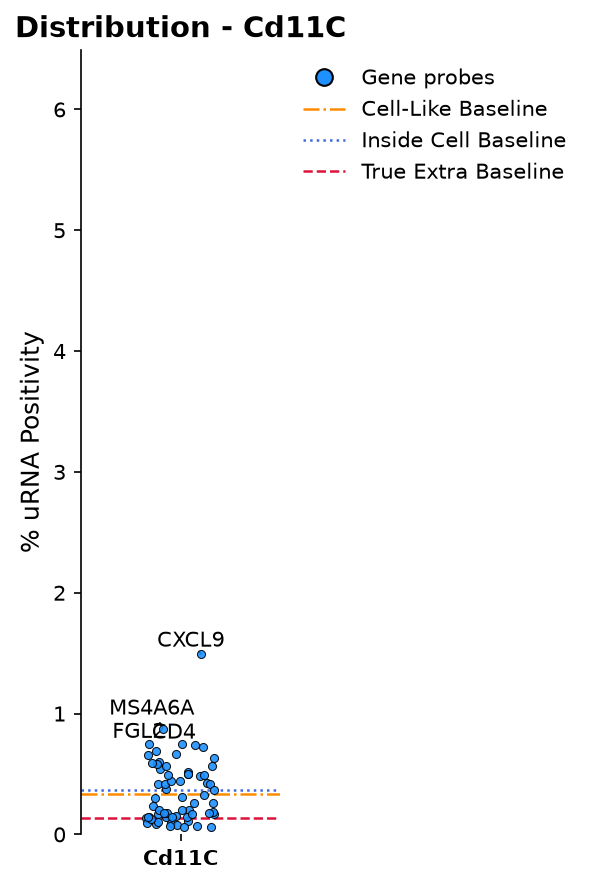

Processing stripplot for channel: CD68


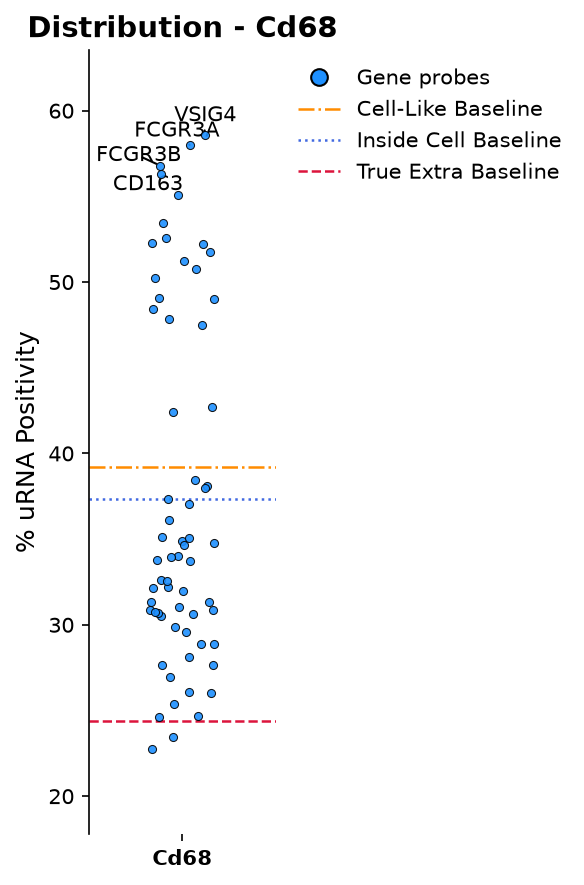

Processing stripplot for channel: CD16


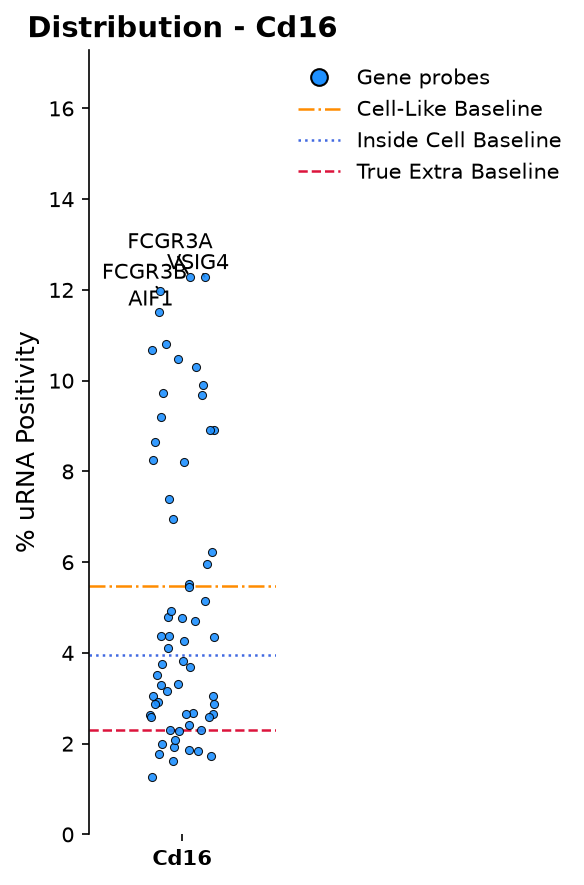

Processing stripplot for channel: GranzymeB


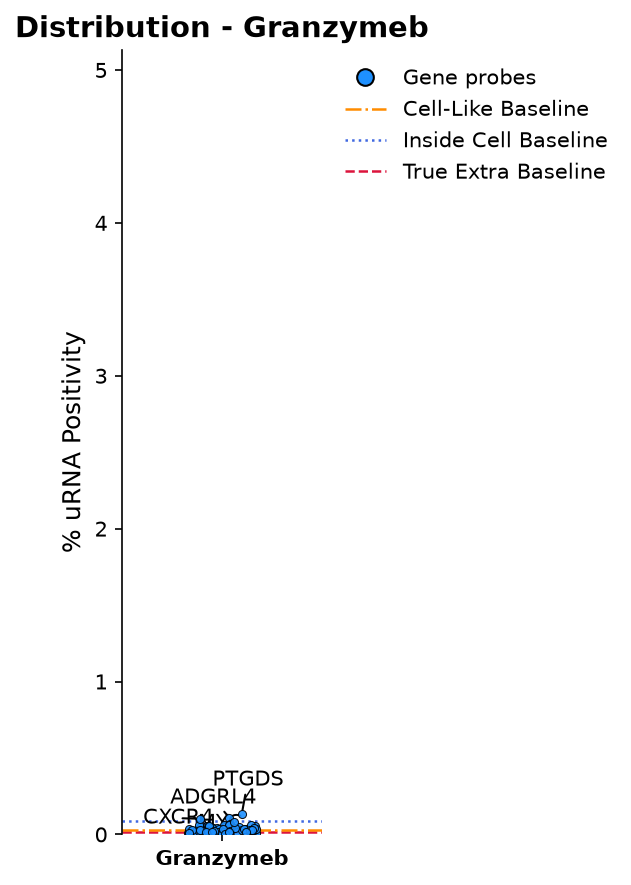

Processing stripplot for channel: CD163


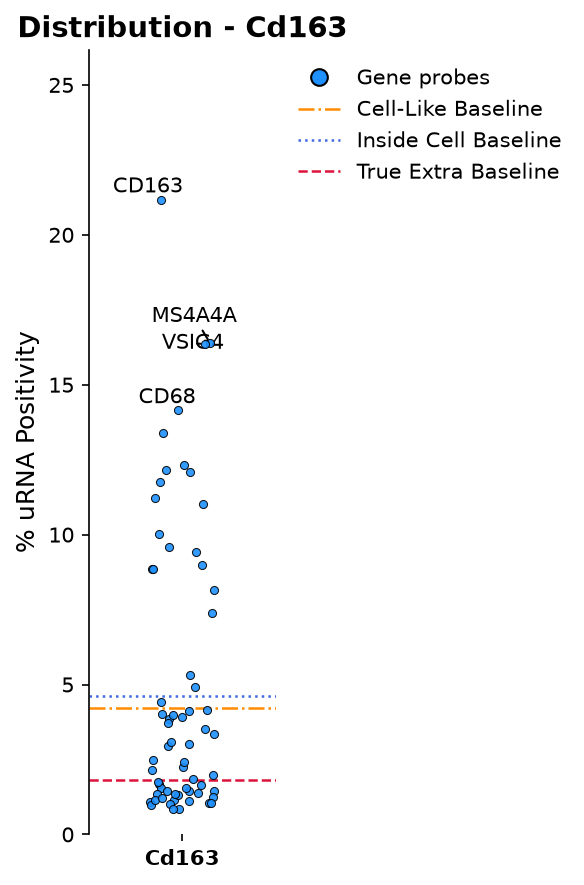

Processing stripplot for channel: PD-1


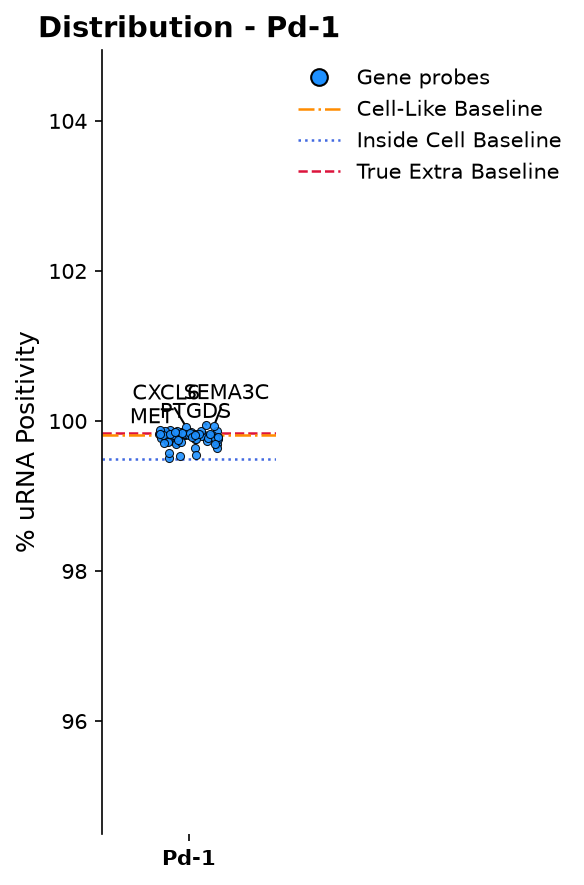

Processing stripplot for channel: VISTA


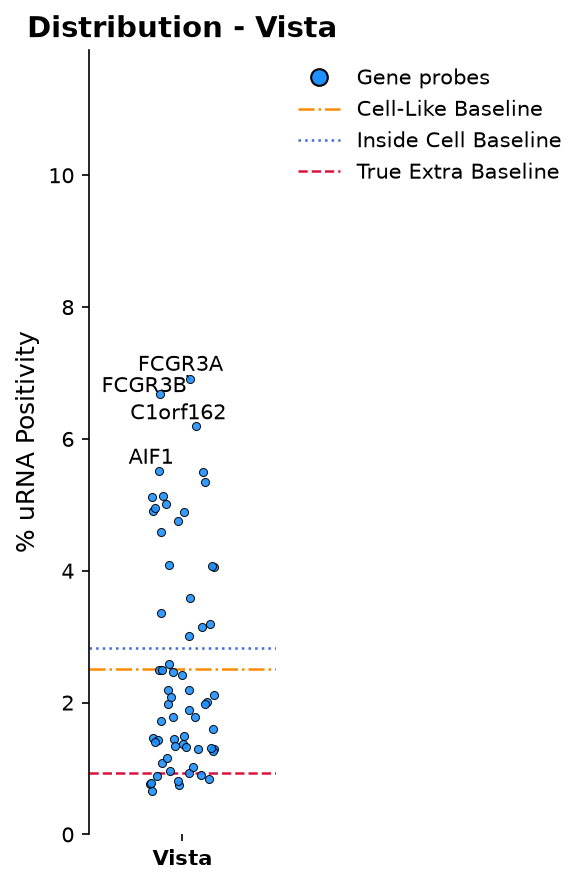

Processing stripplot for channel: PD-L1


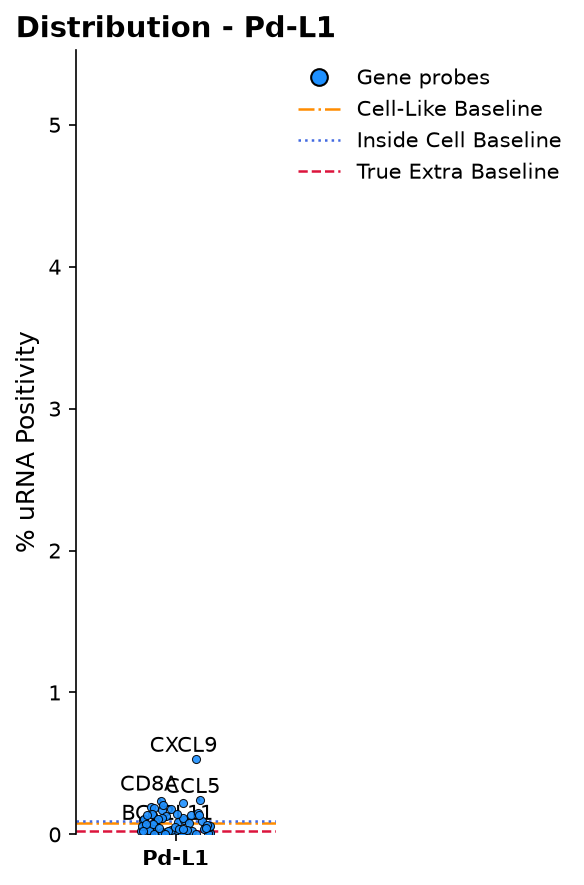

Processing stripplot for channel: LAG-3


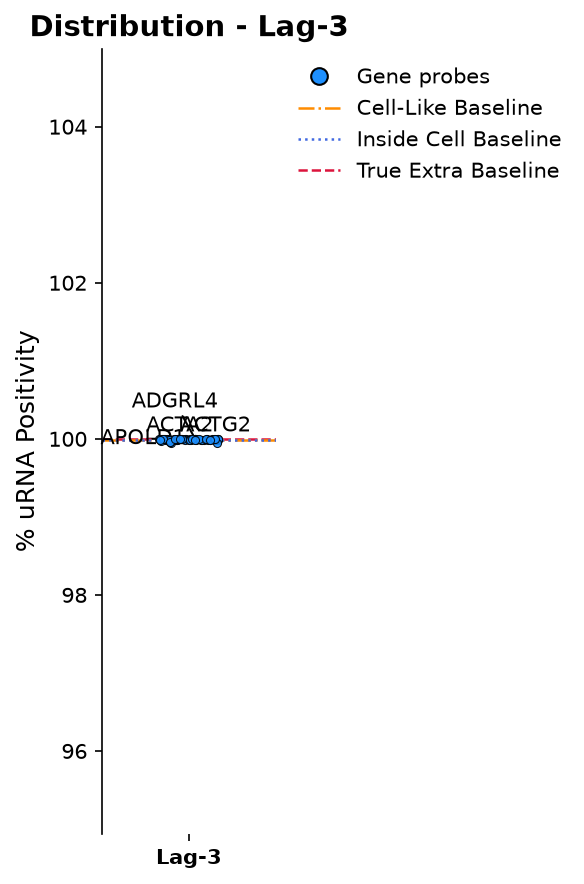

Processing stripplot for channel: CD45RA


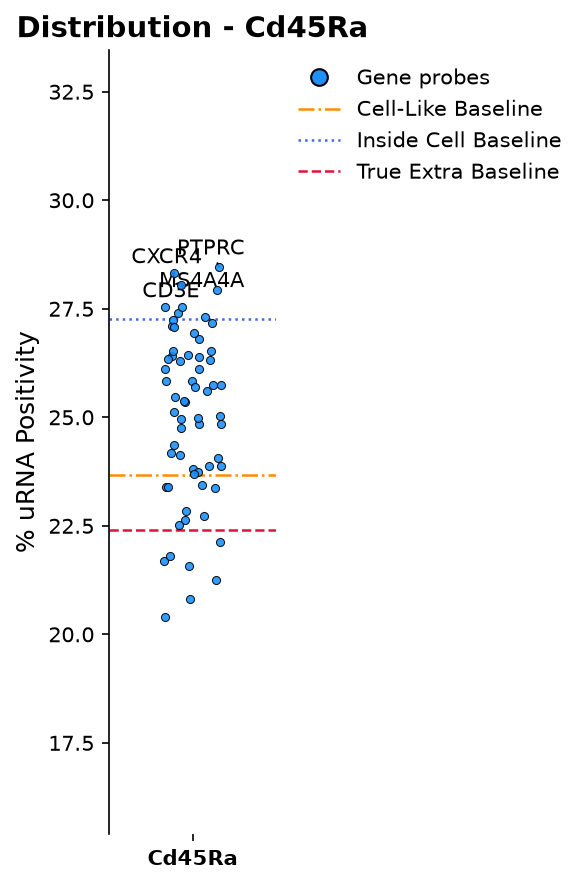

Processing stripplot for channel: PCNA


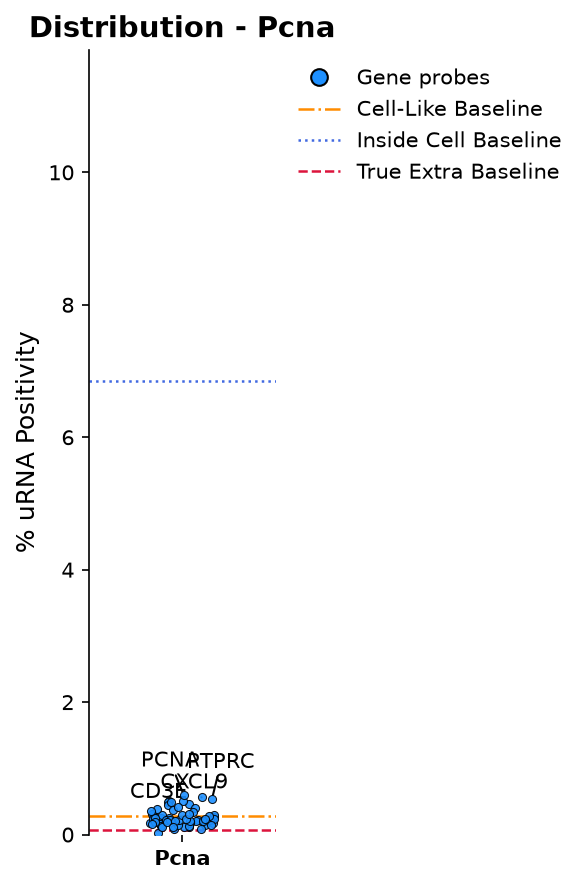

Processing stripplot for channel: CD45RO


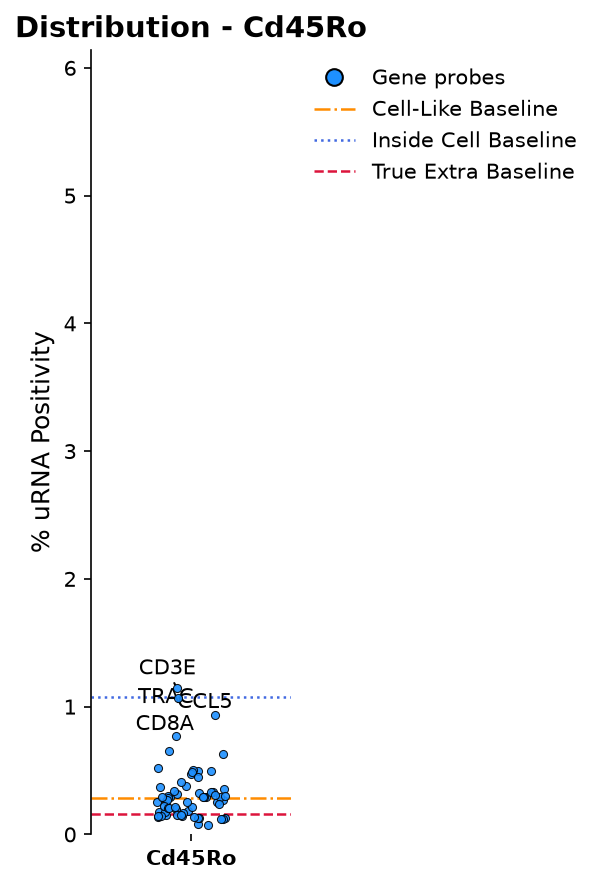

Processing stripplot for channel: Ki-67


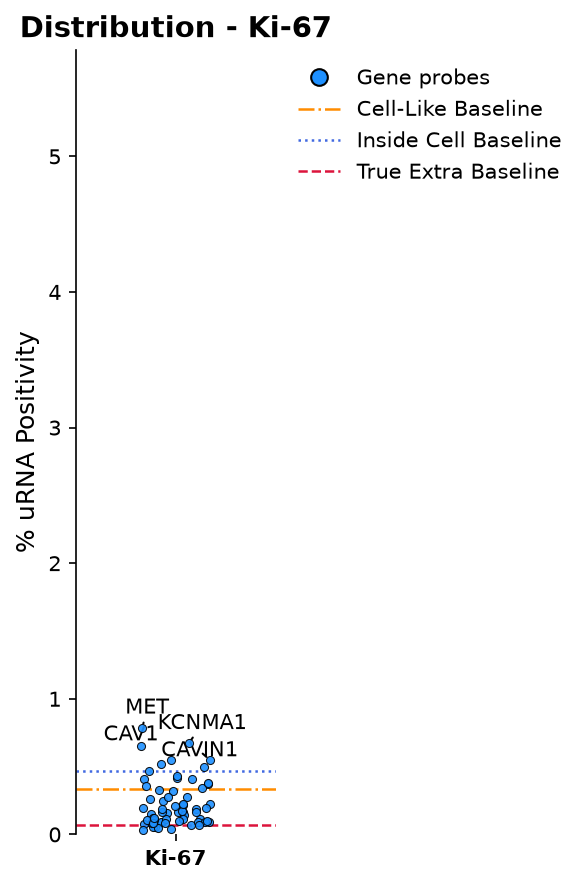

Processing stripplot for channel: Beta-catenin


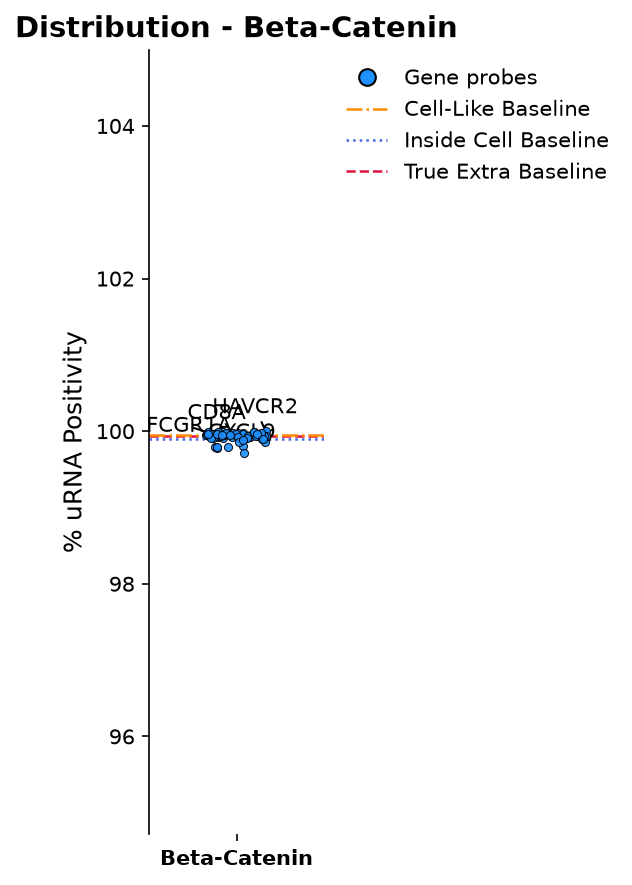

Processing stripplot for channel: CD31


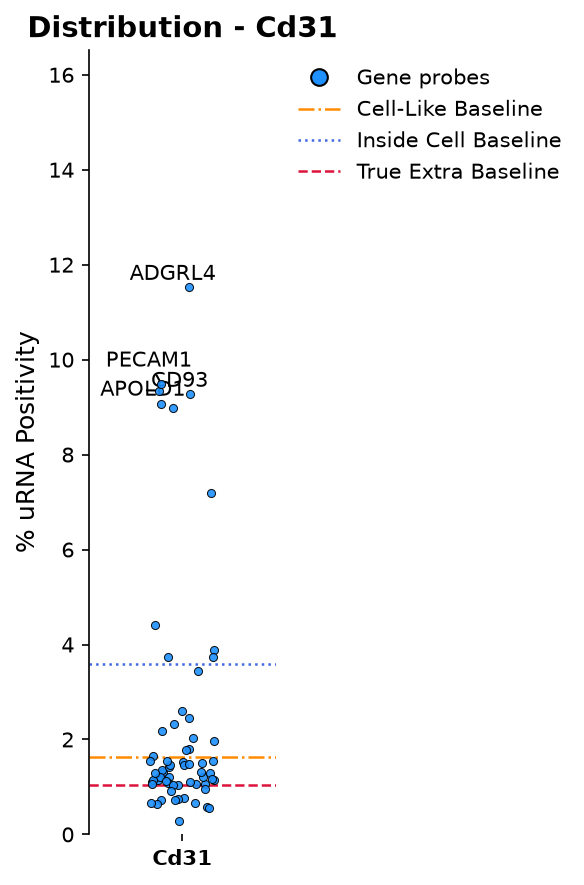

Processing stripplot for channel: PTEN


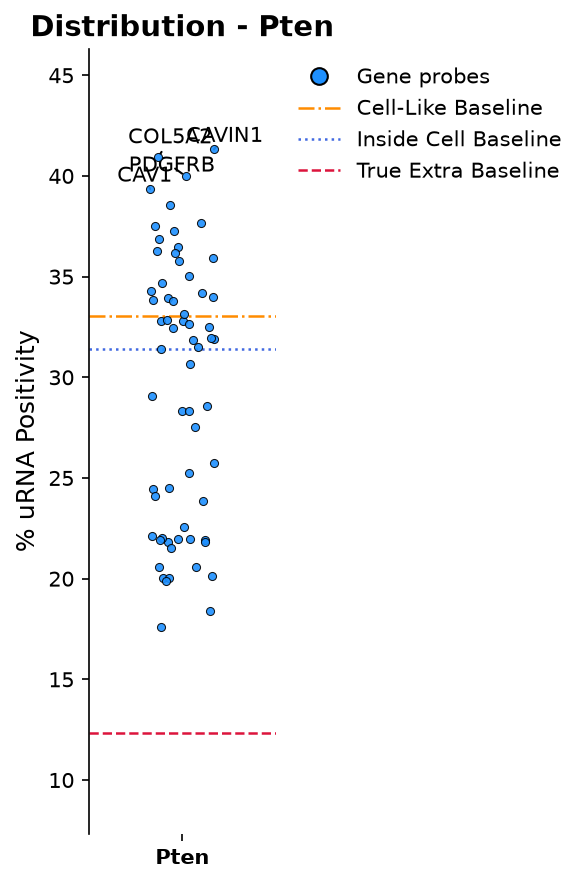

Processing stripplot for channel: PanCK


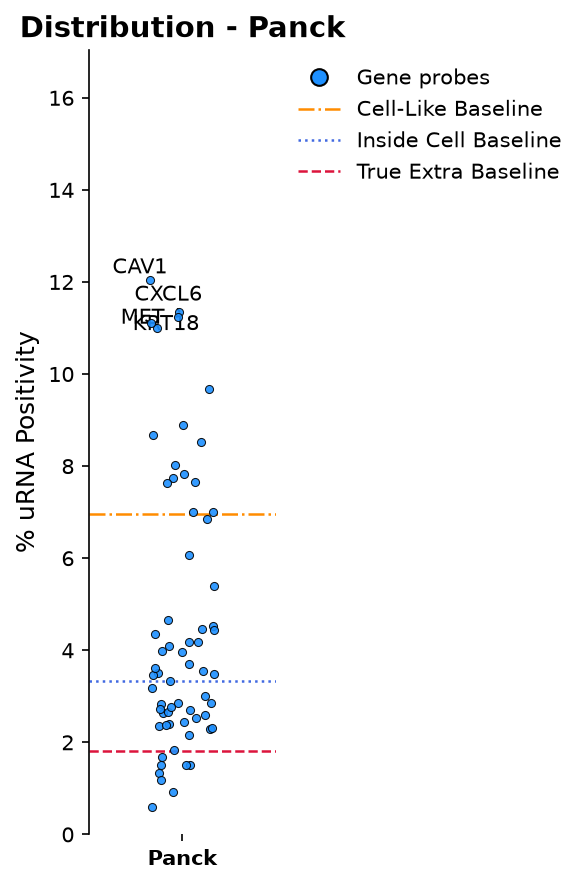

Processing stripplot for channel: Vimentin


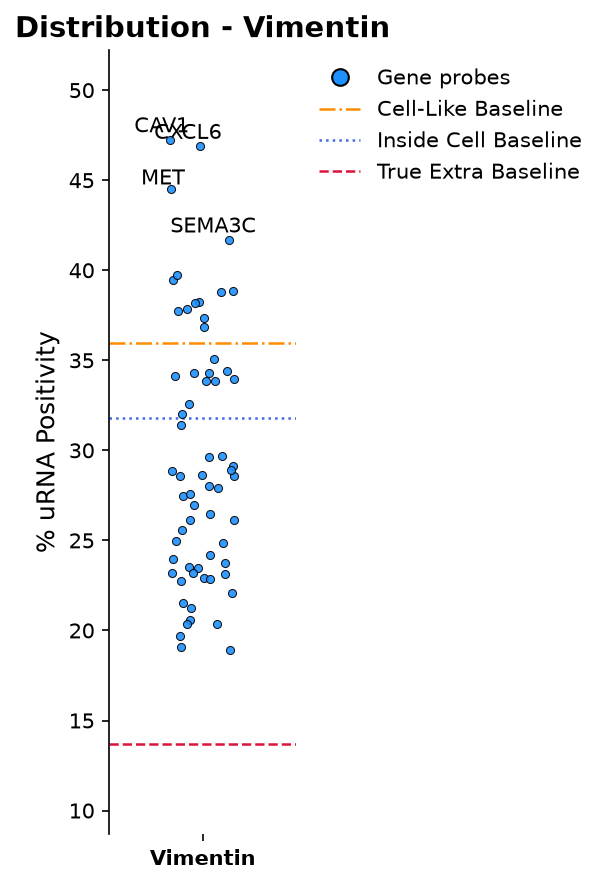

Processing stripplot for channel: alphaSMA


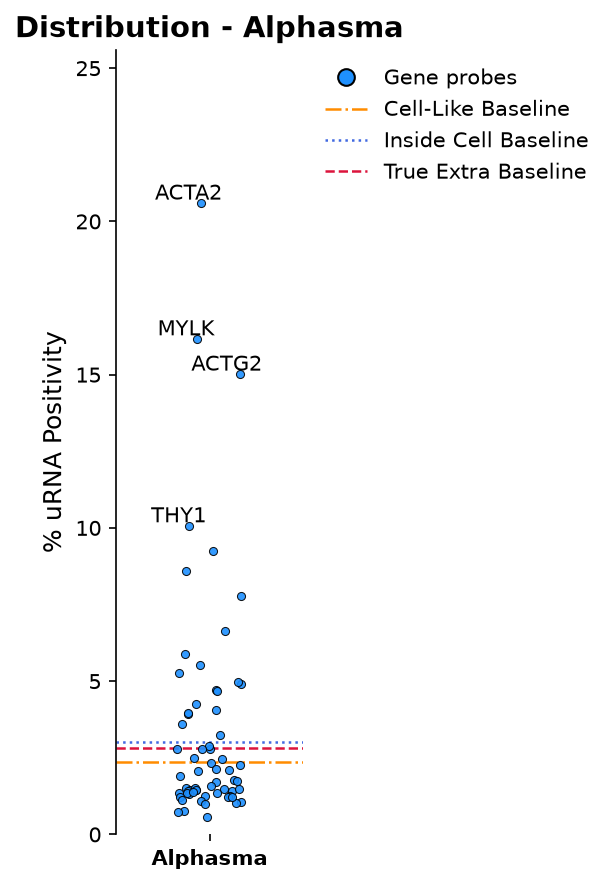

Processing stripplot for channel: CD45


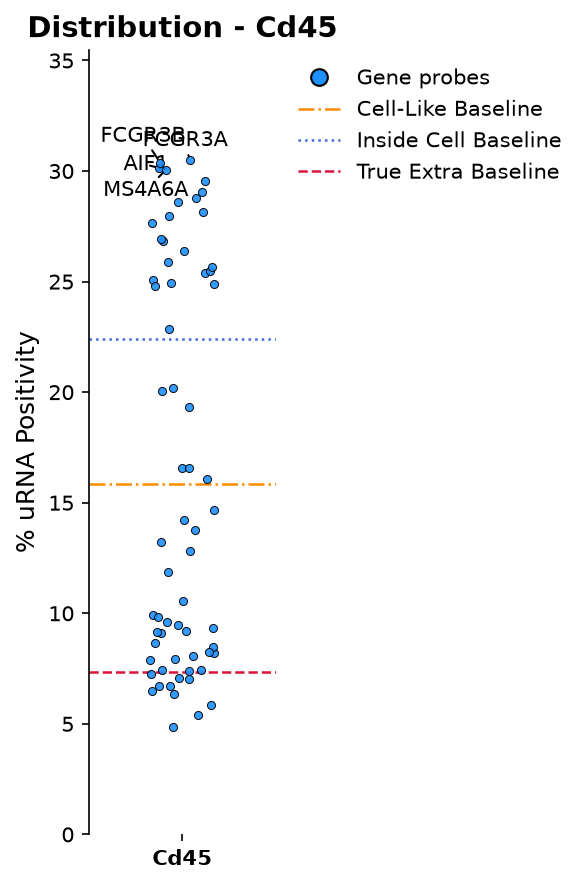

Processing stripplot for channel: E-Cadherin


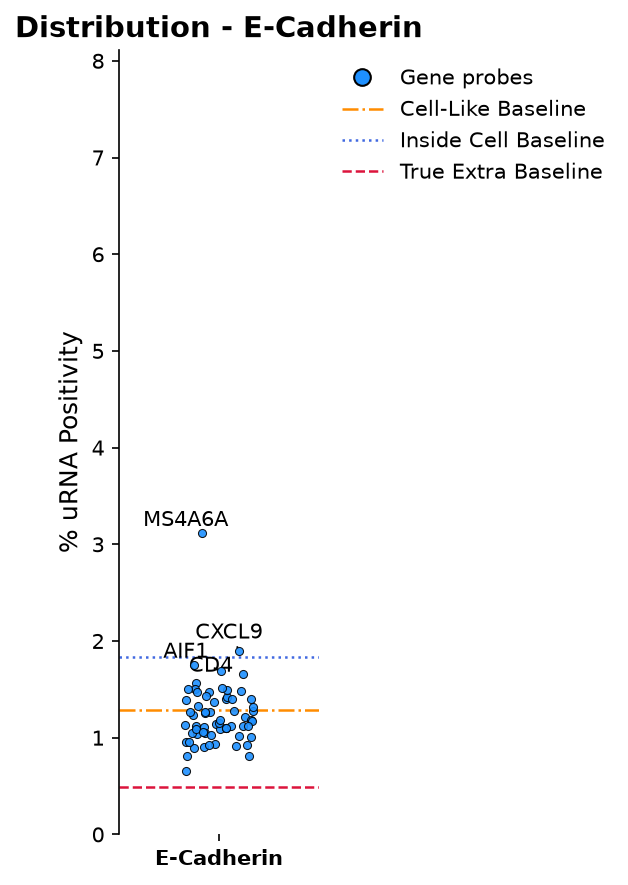

In [27]:
# --- LOOP THROUGH ALL CHANNELS IN df_v ---

# Ensure figures_path exists from your first cell, or fallback to current directory
figures_dir = locals().get('figures_path', './figures')

for channel in df_v.columns:
    # Safe check: Only plot columns that contain numerical positivity values
    if pd.api.types.is_numeric_dtype(df_v[channel]):
        print(f"Processing stripplot for channel: {channel}")
        
        # Call the single-channel stripplot function
        metric_stripplot_extracellular(
            df_values=df_v,
            df_spatial_summary=df_spatial_summary,  # Assumes this is your summary dataframe name
            channel=channel,label_top_n = 4,
            save=True,                             # Set to False if you only want to view inline
            figures_path=figures_dir,
            title=f"Distribution - {channel.replace('_', ' ').title()}"
        )

(64, 35)
Processing stripplot for channel: DAPI


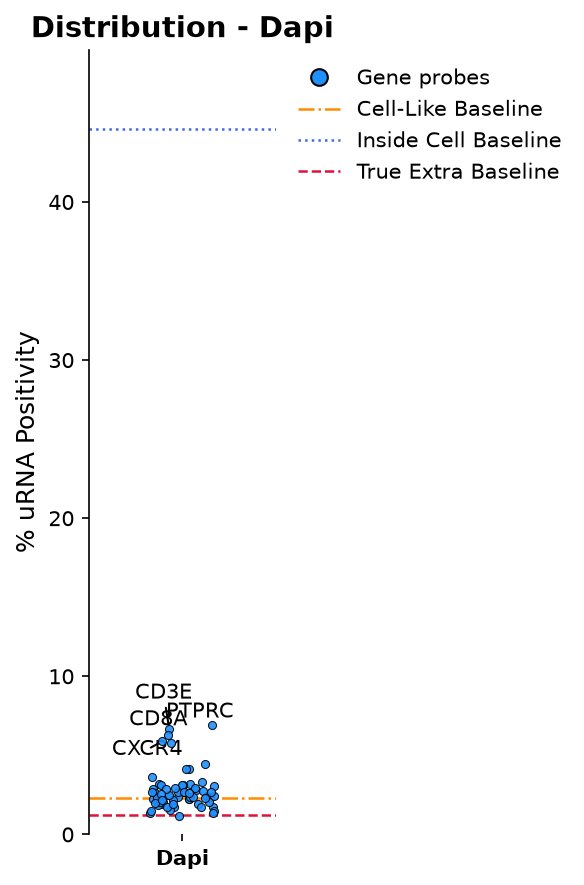

Processing stripplot for channel: ATP1A1/CD45/E-Cadherin


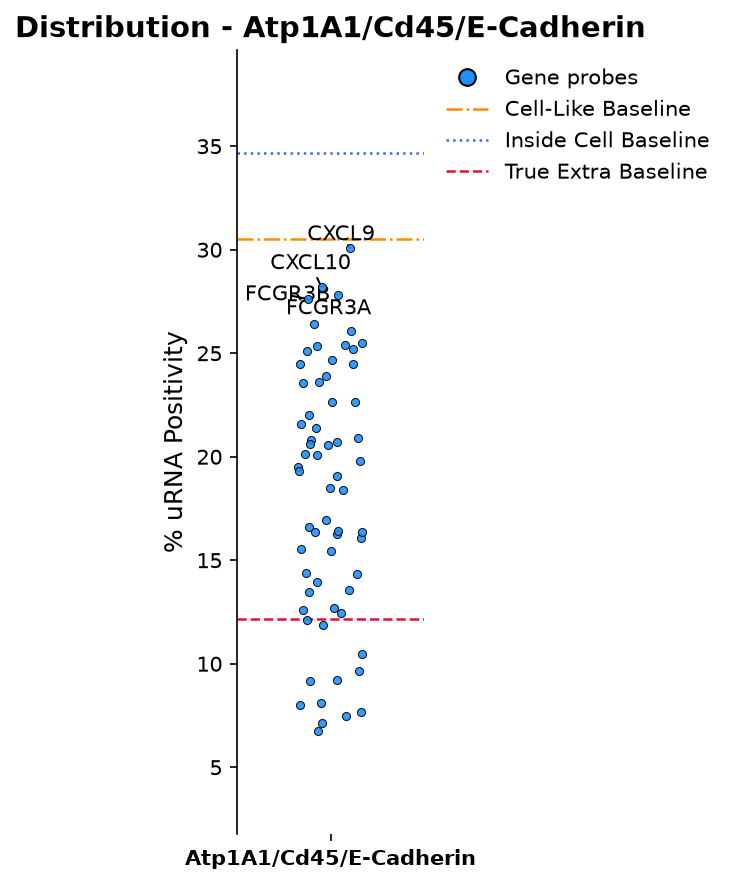

Processing stripplot for channel: 18S


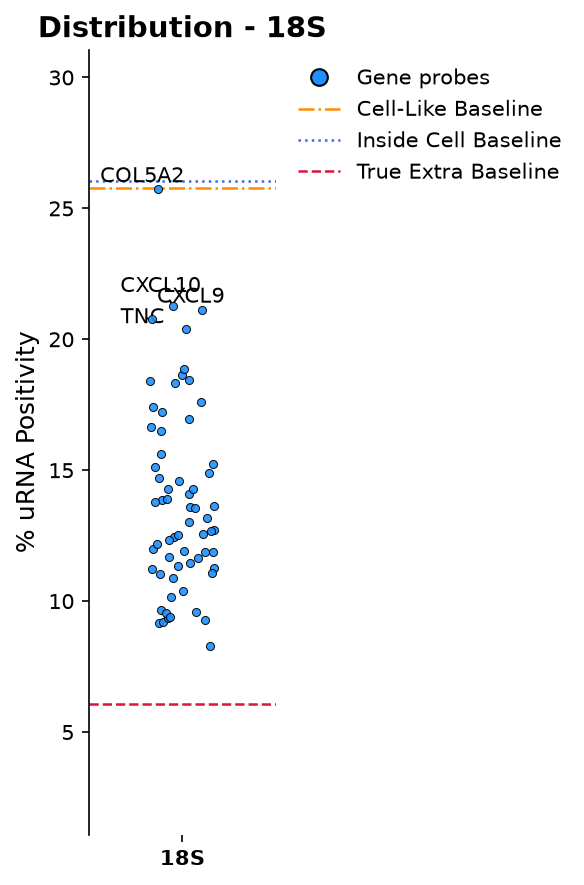

Processing stripplot for channel: alphaSMA/Vimentin


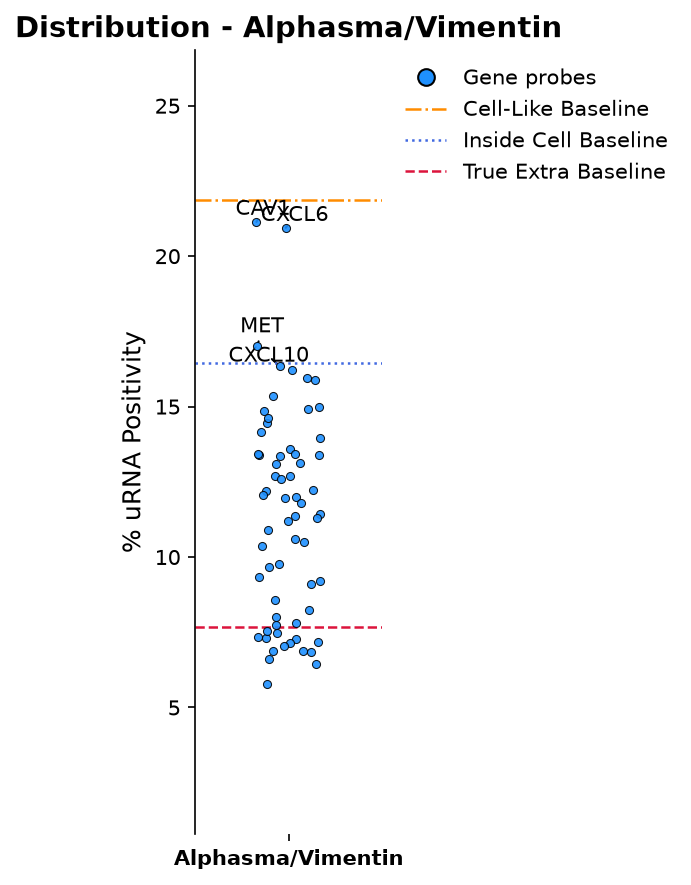

Processing stripplot for channel: Blue background


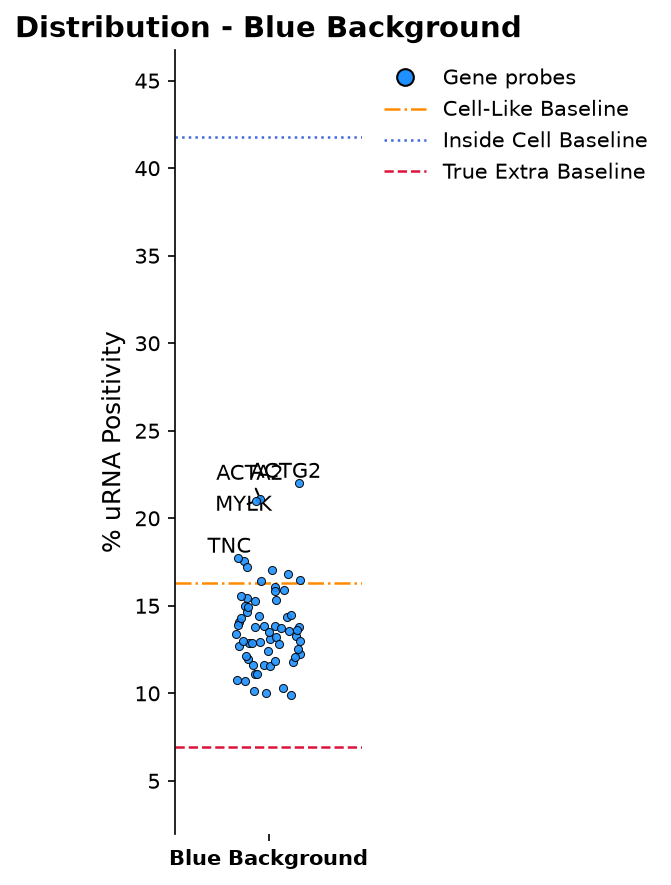

Processing stripplot for channel: Green background


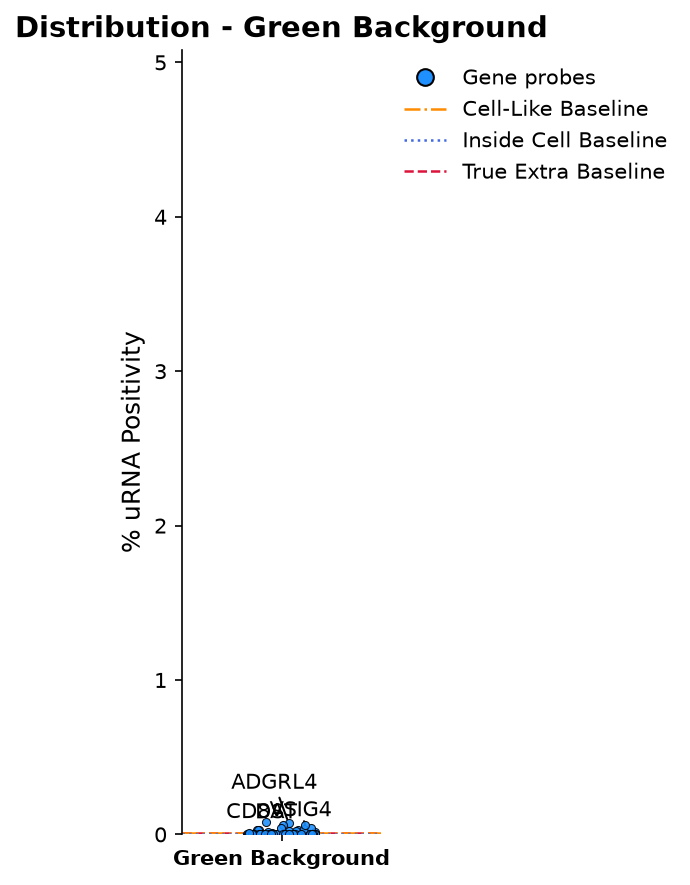

Processing stripplot for channel: Yellow background


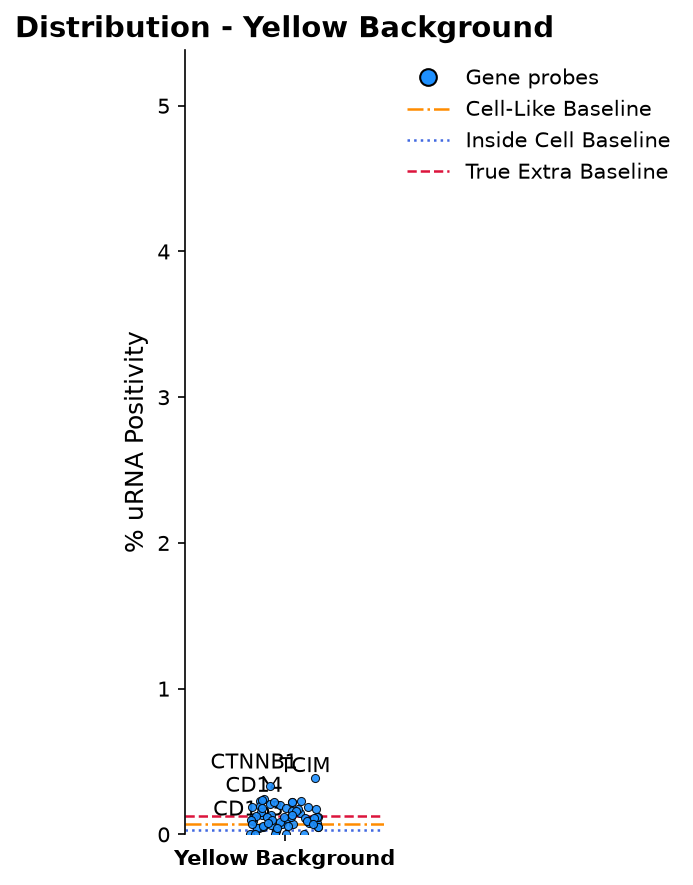

Processing stripplot for channel: Red background


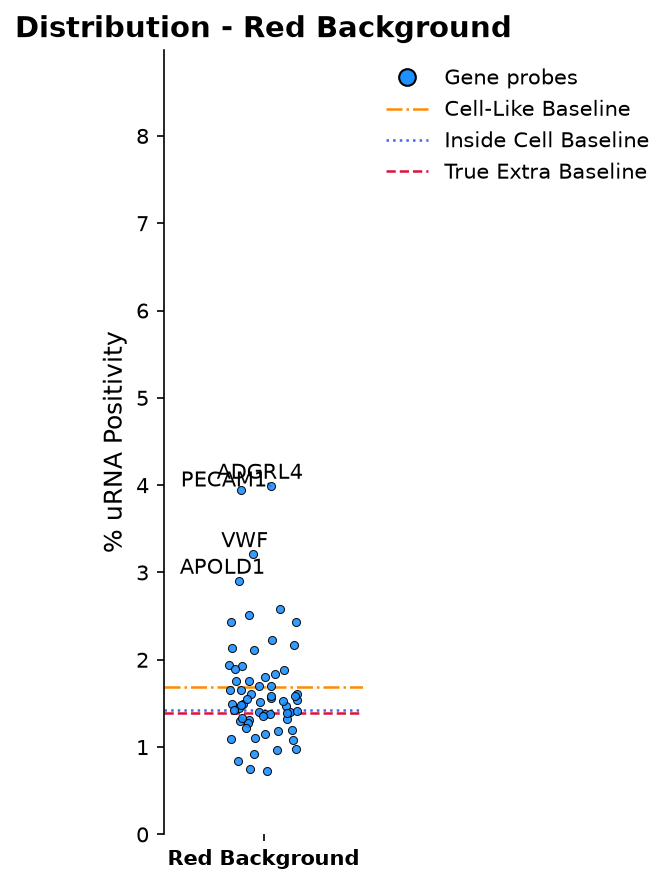

Processing stripplot for channel: CD4


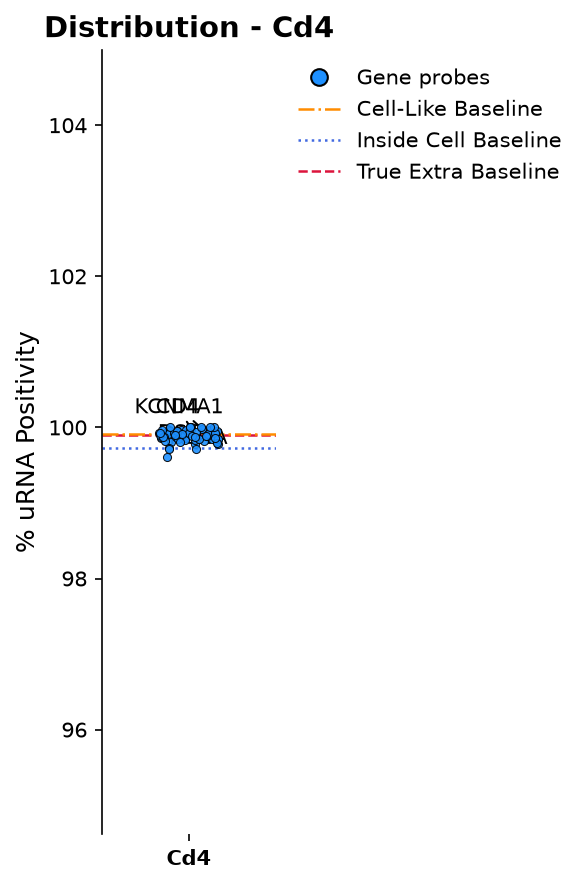

Processing stripplot for channel: CD20


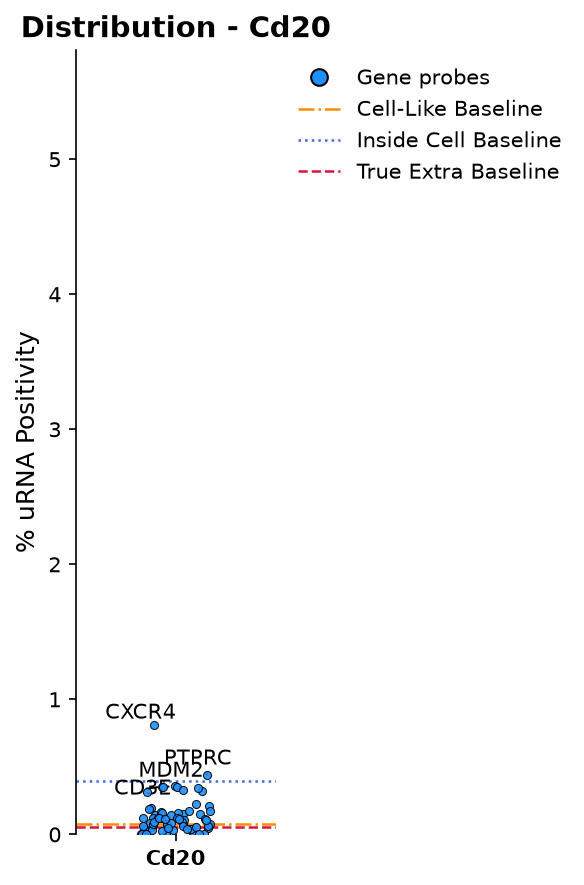

Processing stripplot for channel: CD8A


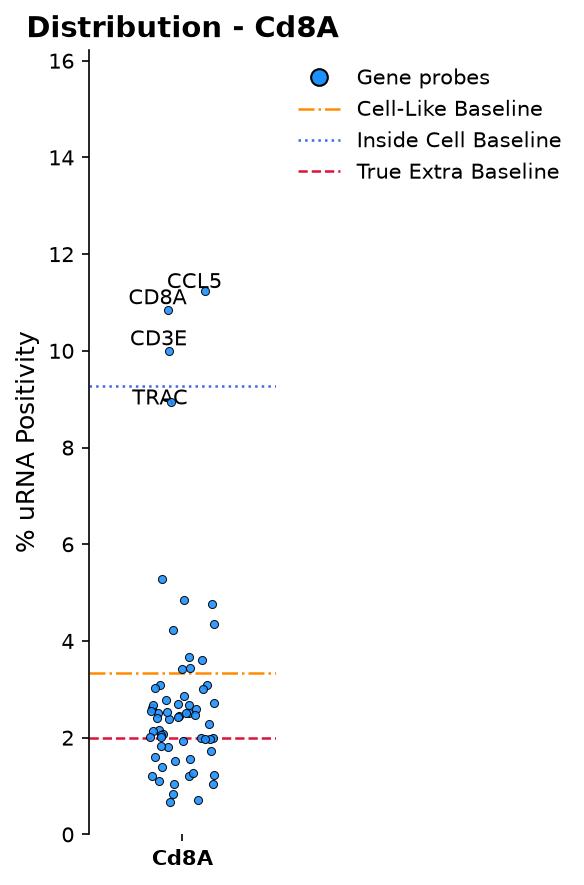

Processing stripplot for channel: CD3E


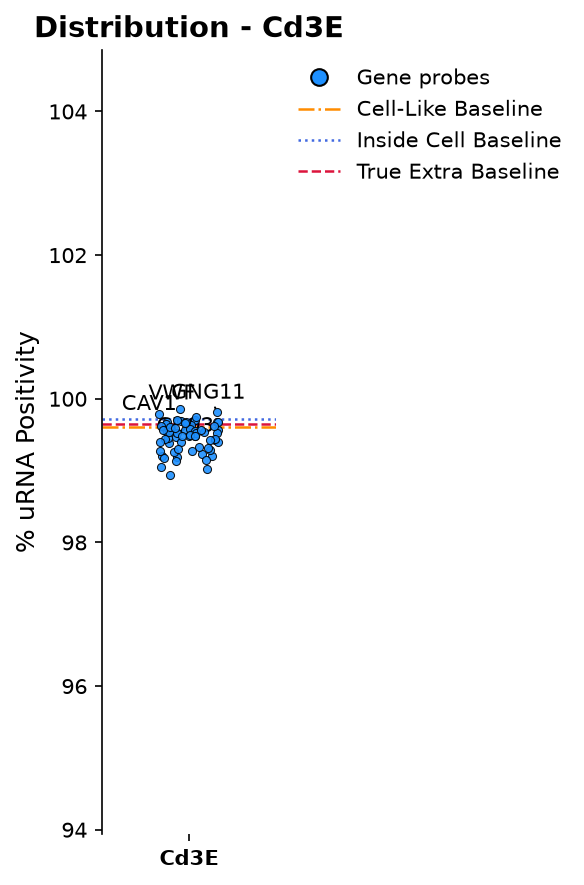

Processing stripplot for channel: CD138


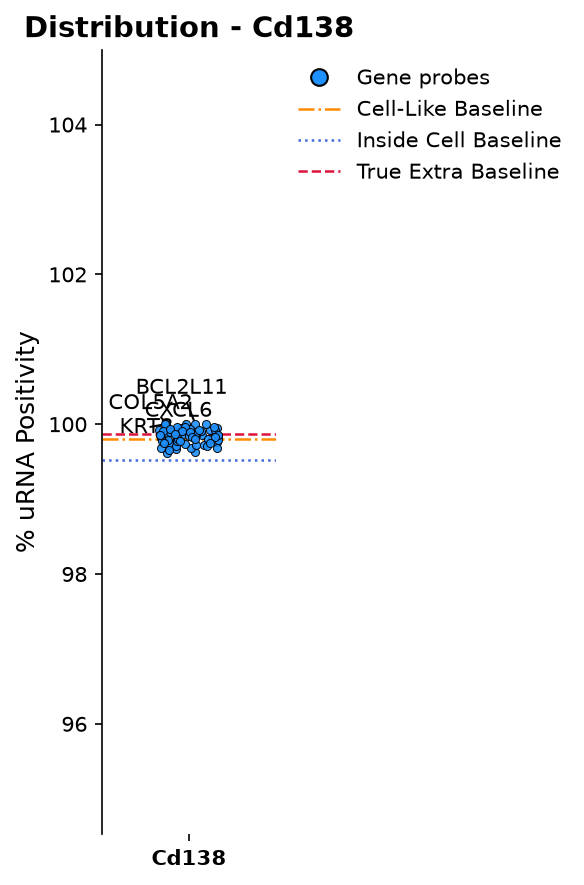

Processing stripplot for channel: HLA-DR


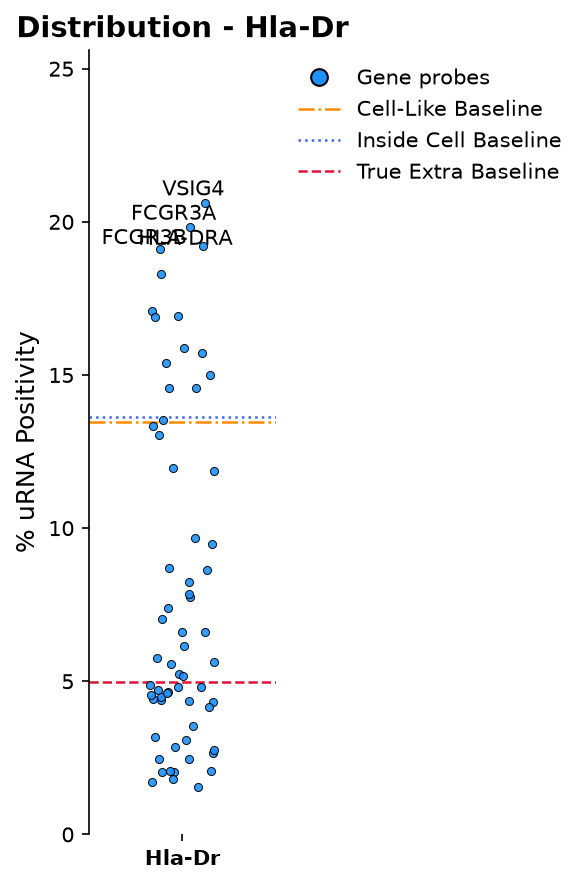

Processing stripplot for channel: CD11c


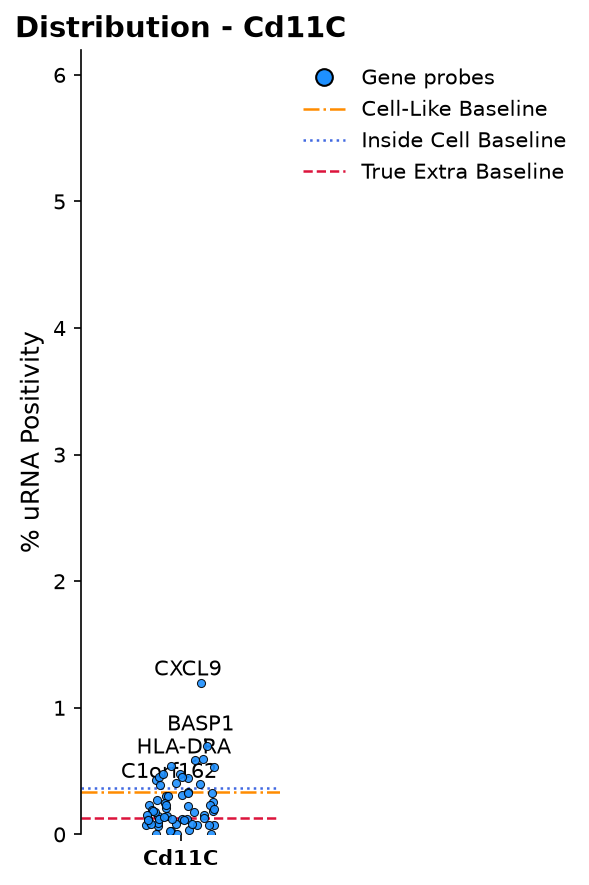

Processing stripplot for channel: CD68


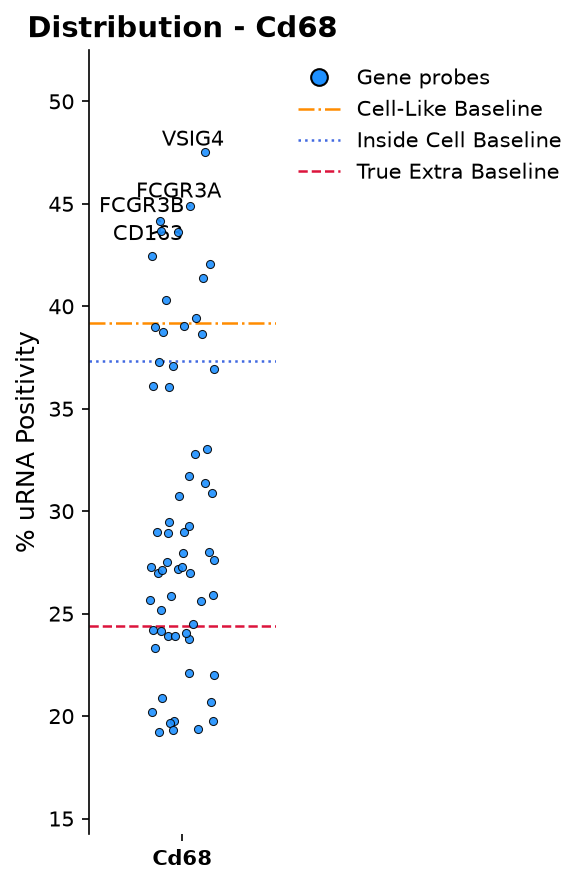

Processing stripplot for channel: CD16


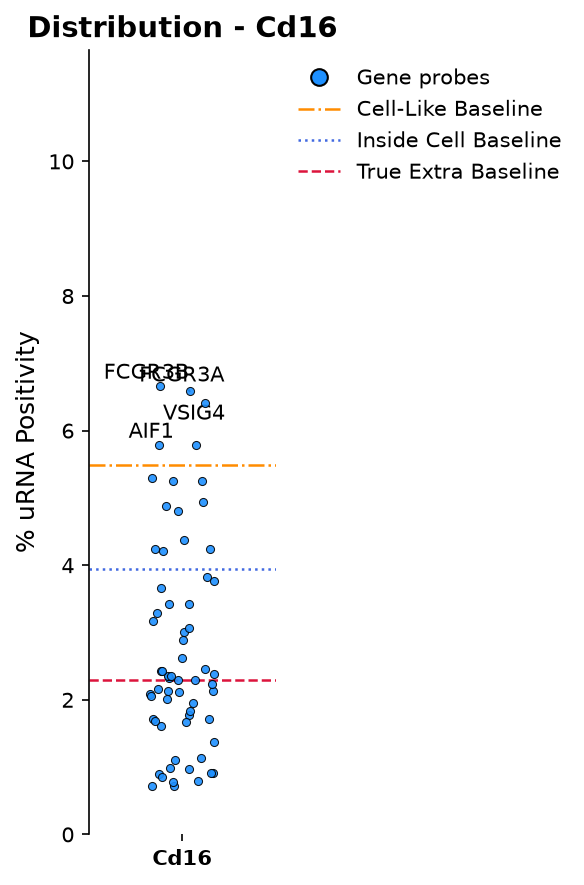

Processing stripplot for channel: GranzymeB


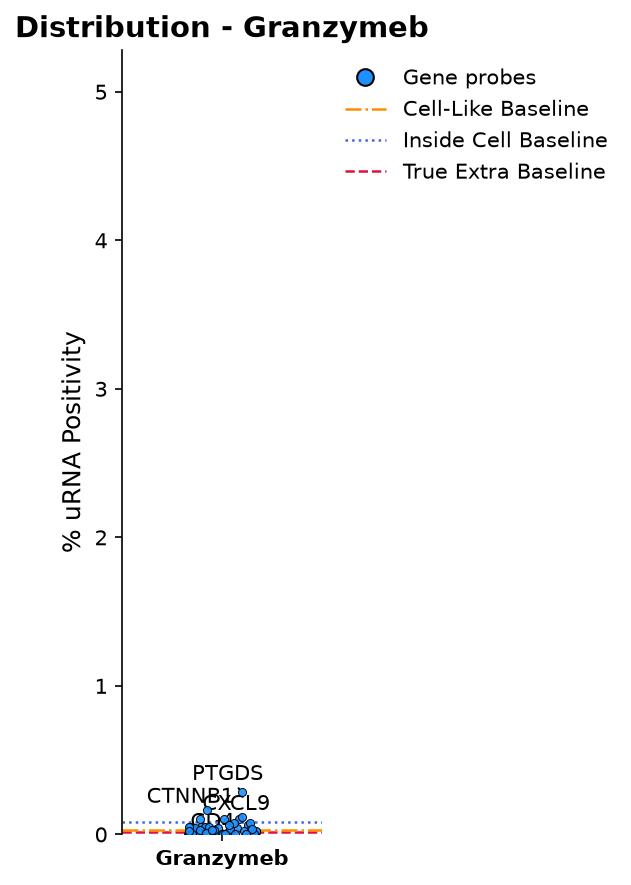

Processing stripplot for channel: CD163


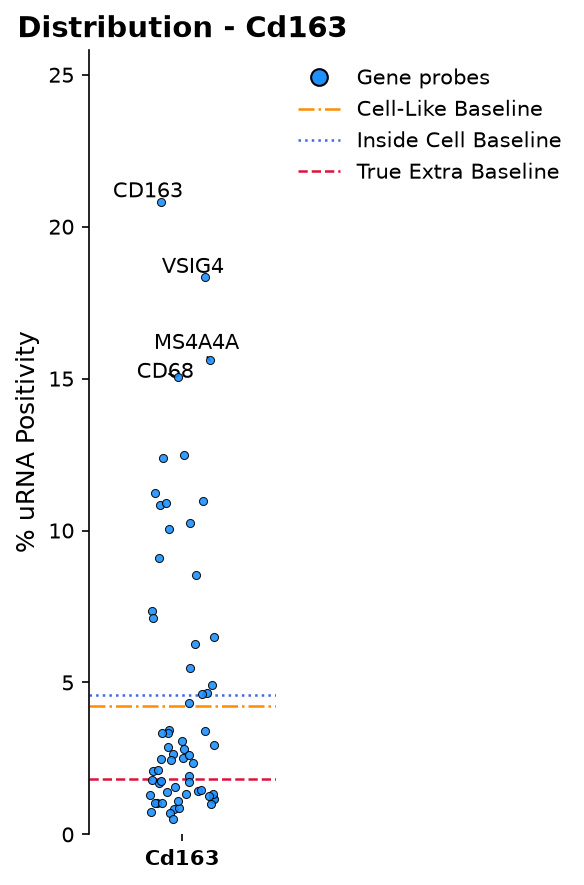

Processing stripplot for channel: PD-1


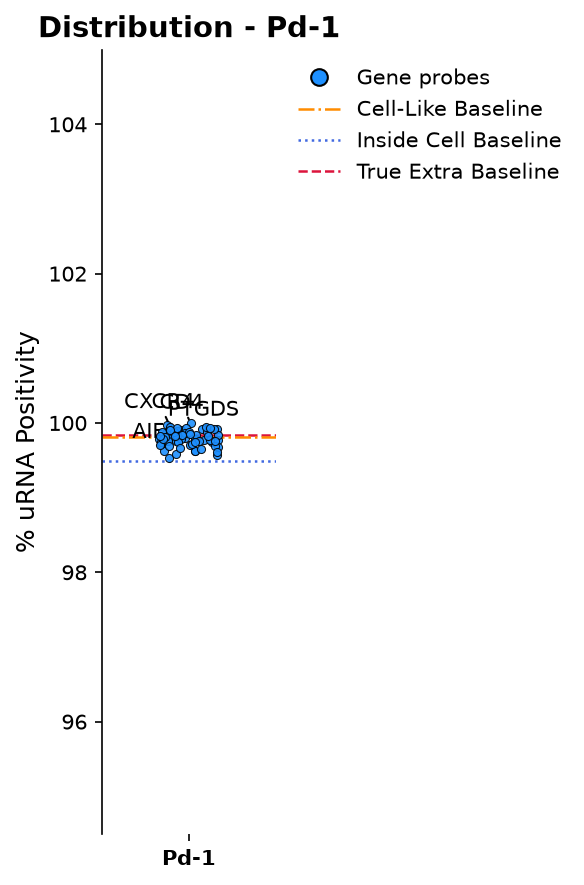

Processing stripplot for channel: VISTA


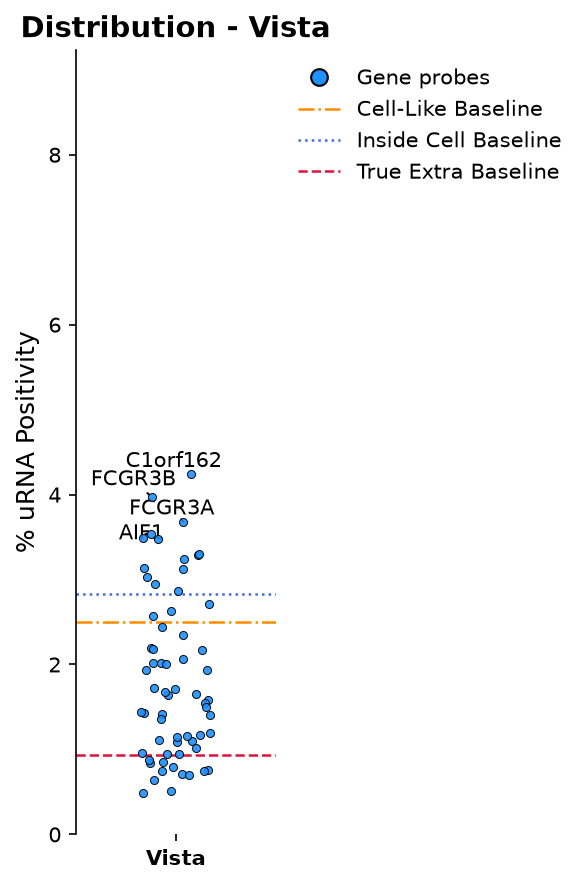

Processing stripplot for channel: PD-L1


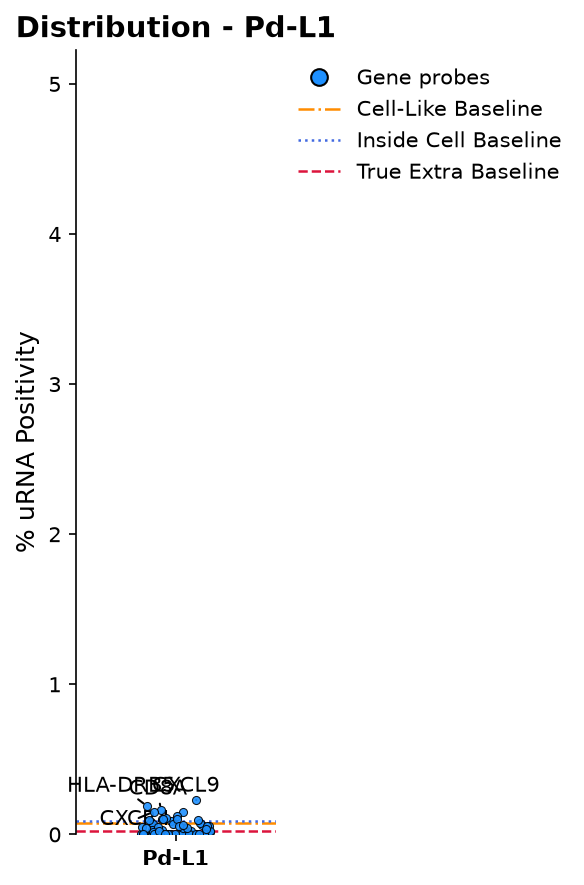

Processing stripplot for channel: LAG-3


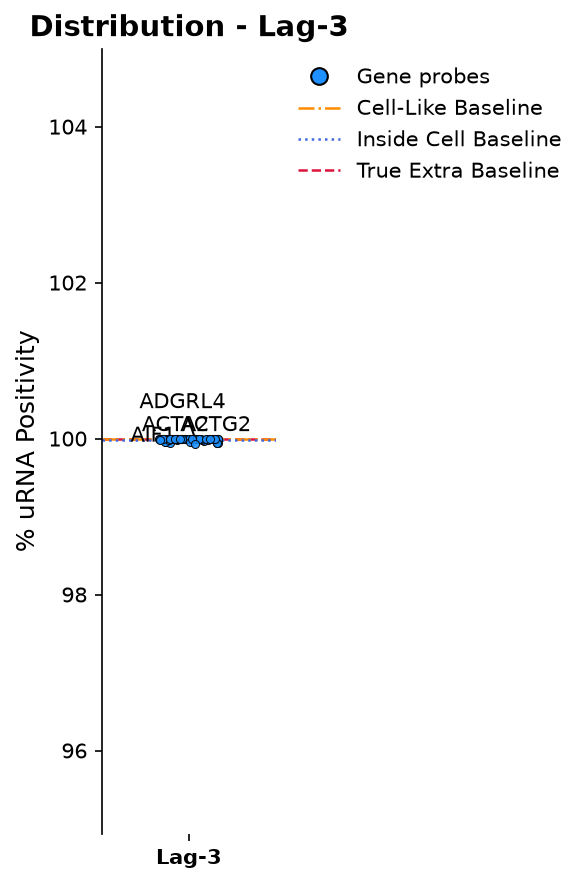

Processing stripplot for channel: CD45RA


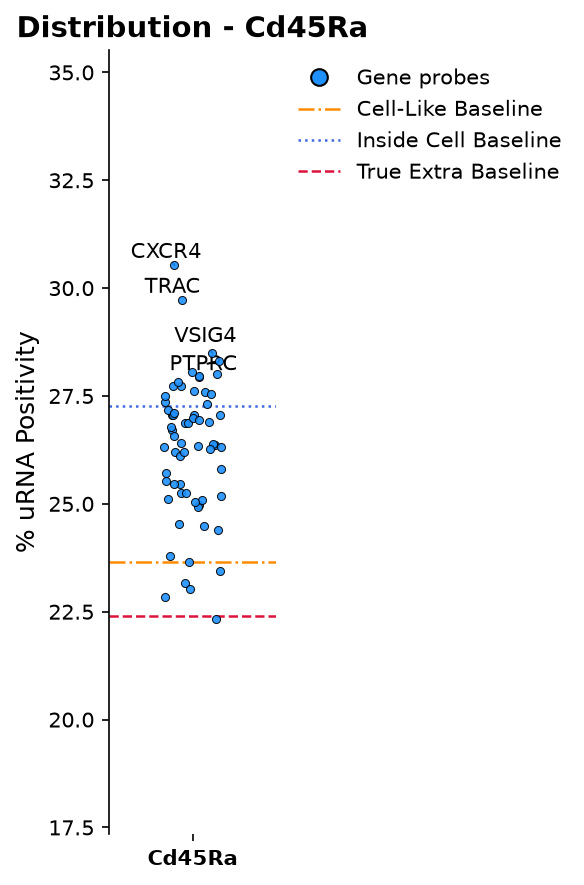

Processing stripplot for channel: PCNA


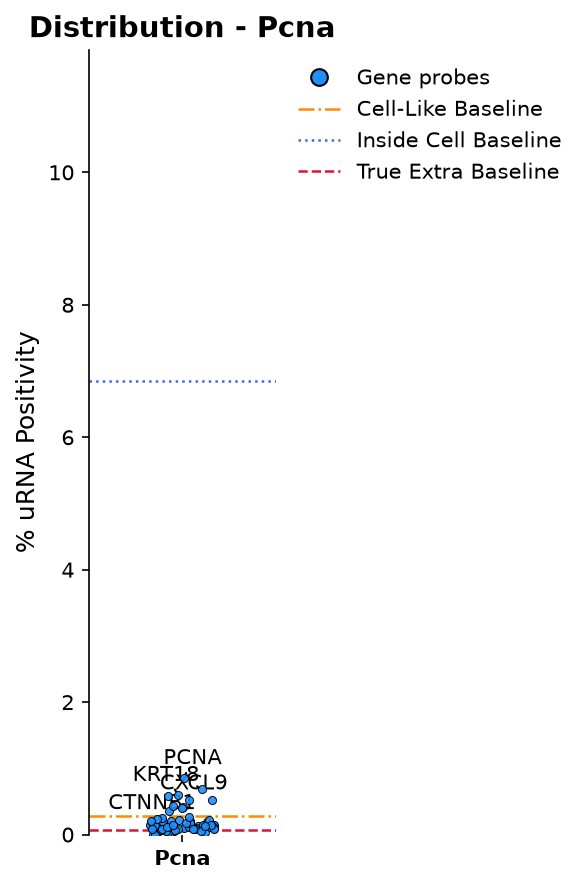

Processing stripplot for channel: CD45RO


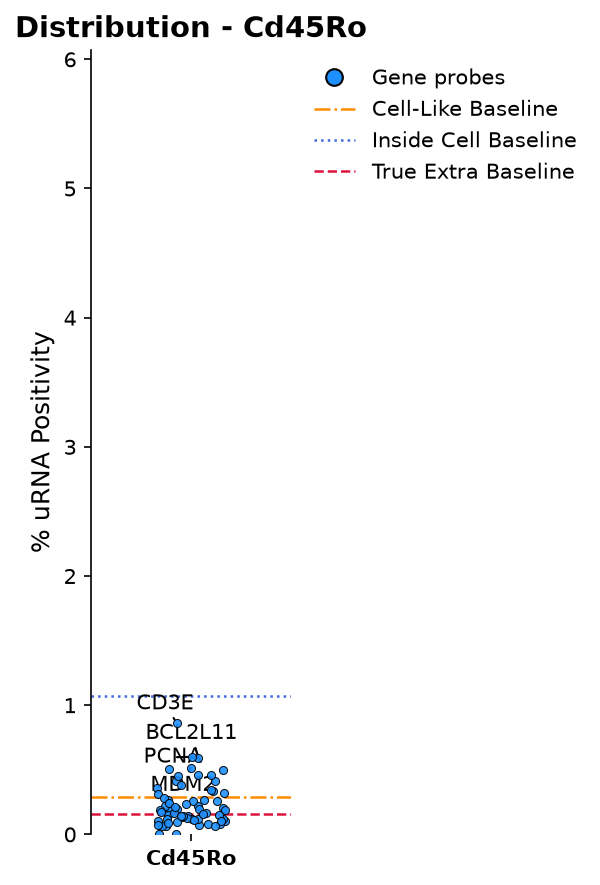

Processing stripplot for channel: Ki-67


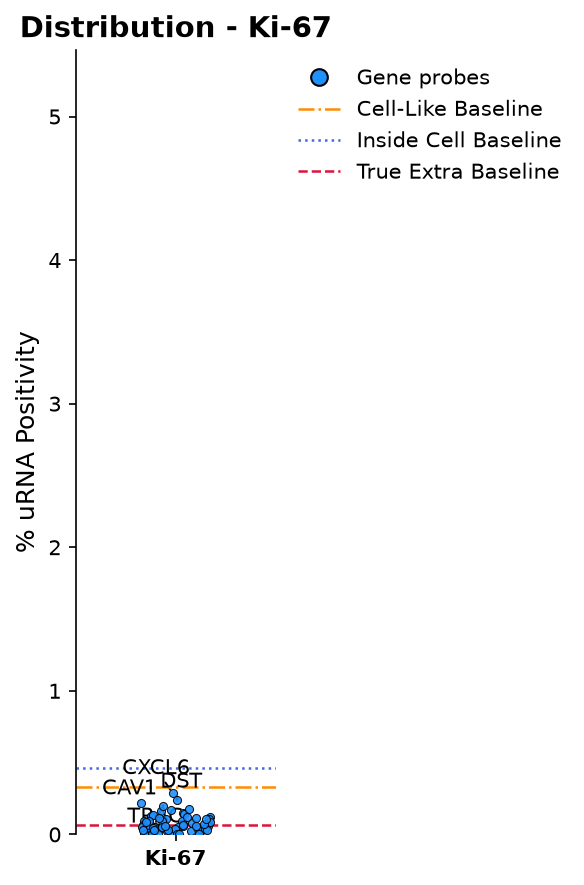

Processing stripplot for channel: Beta-catenin


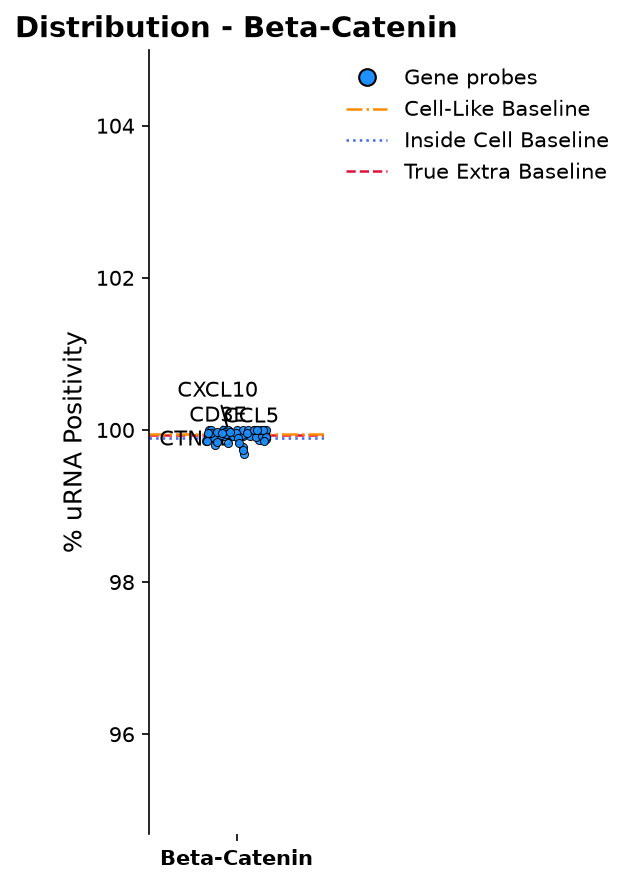

Processing stripplot for channel: CD31


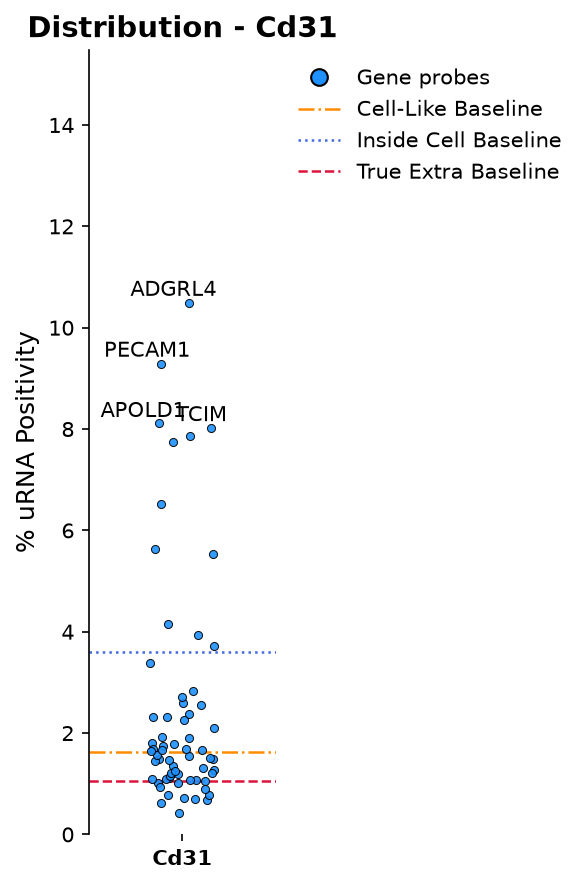

Processing stripplot for channel: PTEN


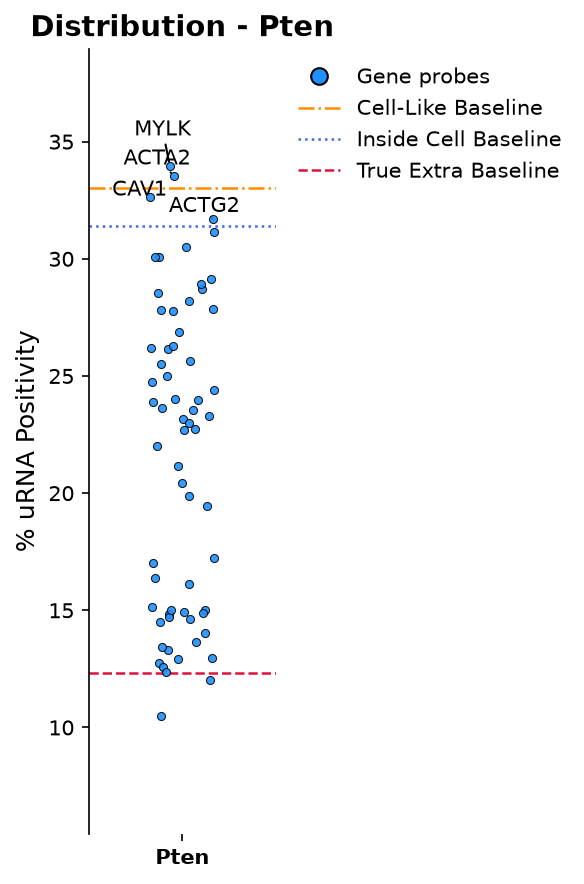

Processing stripplot for channel: PanCK


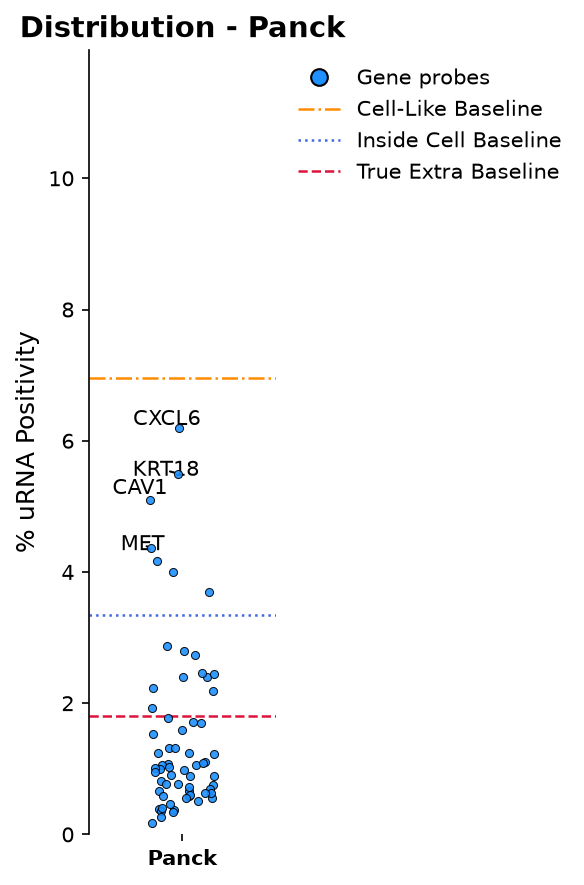

Processing stripplot for channel: Vimentin


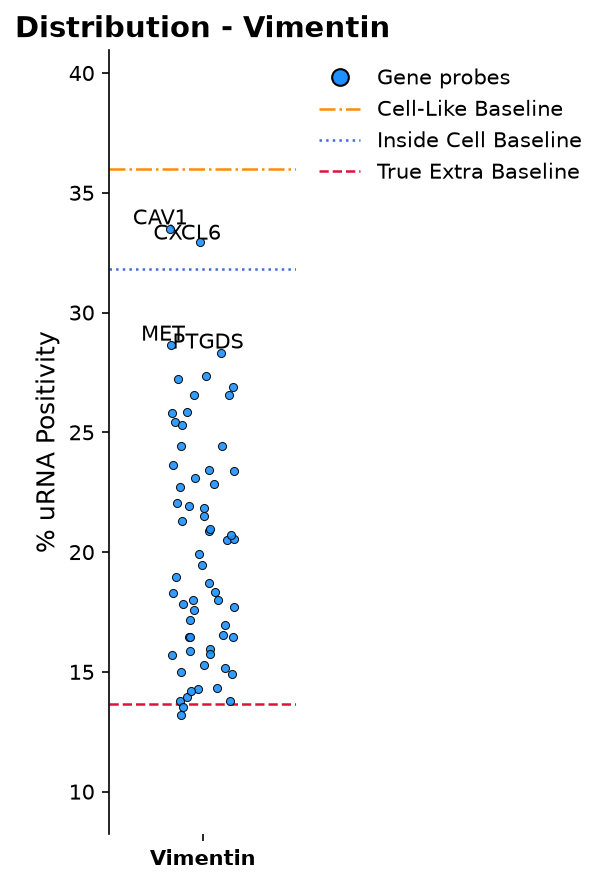

Processing stripplot for channel: alphaSMA


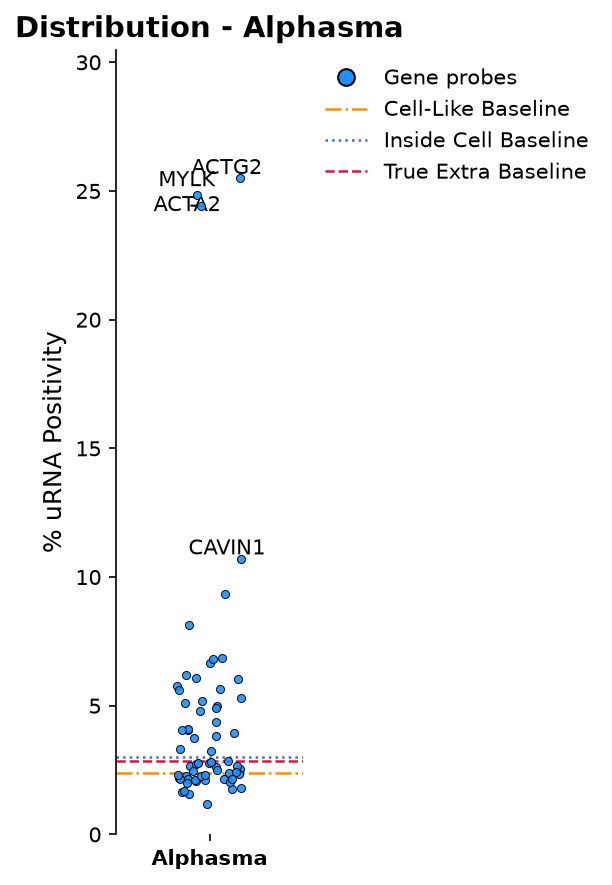

Processing stripplot for channel: CD45


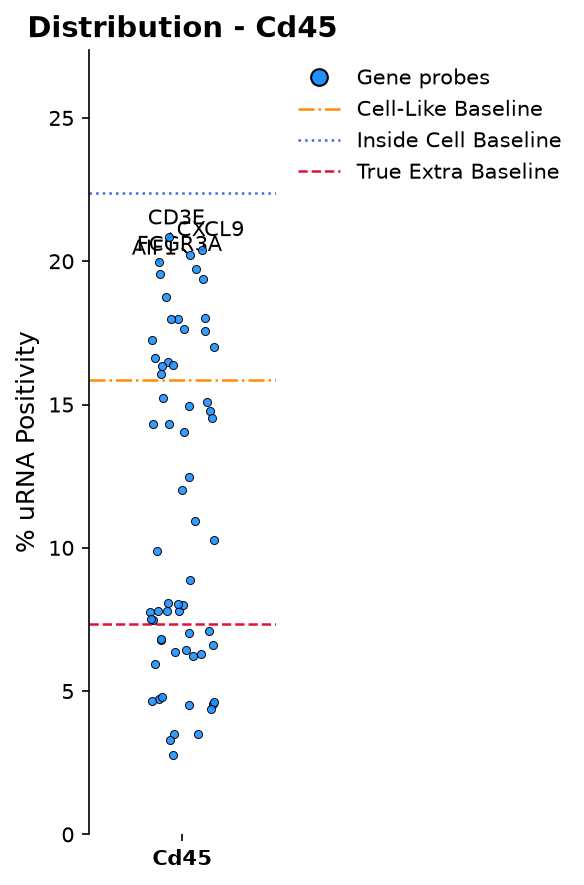

Processing stripplot for channel: E-Cadherin


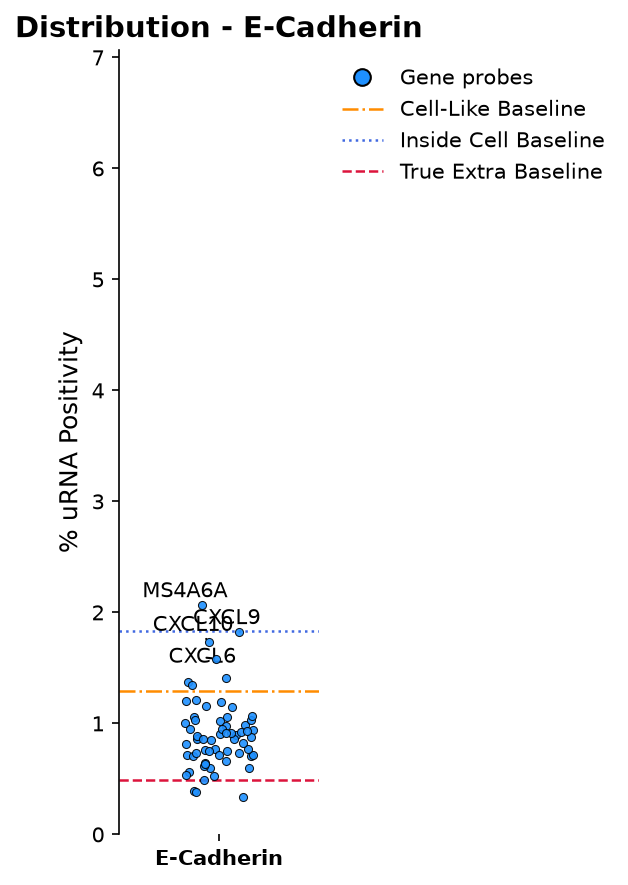

In [28]:
selgenes=sdata['xrna_metadata'].var[sdata['xrna_metadata'].var['logfoldchange_over_noise']>0.1].index
df_v_extra=df_values_extra[df_values_extra.index.isin(selgenes)]
print(df_v_extra.shape)

# Ensure figures_path exists from your first cell, or fallback to current directory
figures_dir = locals().get('figures_path', './figures')

for channel in df_v.columns:
    # Safe check: Only plot columns that contain numerical positivity values
    if pd.api.types.is_numeric_dtype(df_v[channel]):
        print(f"Processing stripplot for channel: {channel}")
        
        # Call the single-channel stripplot function
        metric_stripplot_extracellular(
            df_values=df_v_extra,
            df_spatial_summary=df_spatial_summary,  # Assumes this is your summary dataframe name
            channel=channel,label_top_n = 4,
            save=True,                             # Set to False if you only want to view inline
            figures_path=figures_dir,
            title=f"Distribution - {channel.replace('_', ' ').title()}"
        )

In [ ]:
sns.clustermap(df_v_extra)

# Work on the LogFC

In [18]:
trans_positivity, channel_names_for_enrichment = compute_transcript_pixel_positivity(sdata, df_summary)
trans_positivity = assign_transcript_categories(trans_positivity)
trans_positivity["transcript_category"].value_counts()


=== Flagging per-transcript pixel positivity per channel ===
-> DAPI: 37.16% of transcripts on positive pixels
-> ATP1A1/CD45/E-Cadherin: 34.51% of transcripts on positive pixels
-> 18S: 32.84% of transcripts on positive pixels
-> alphaSMA/Vimentin: 18.94% of transcripts on positive pixels
-> Blue background: 40.05% of transcripts on positive pixels
-> Green background: 0.00% of transcripts on positive pixels
-> Yellow background: 0.03% of transcripts on positive pixels
-> Red background: 1.47% of transcripts on positive pixels
-> CD4: 99.73% of transcripts on positive pixels
-> CD20: 0.32% of transcripts on positive pixels
-> CD8A: 7.26% of transcripts on positive pixels
-> CD3E: 99.72% of transcripts on positive pixels
-> CD138: 99.49% of transcripts on positive pixels
-> HLA-DR: 15.08% of transcripts on positive pixels
-> CD11c: 0.39% of transcripts on positive pixels
-> CD68: 38.41% of transcripts on positive pixels
-> CD16: 4.29% of transcripts on positive pixels
-> GranzymeB: 0.0

transcript_category
intracellular    5757156
cell_like        1078751
high_density      237157
other             199180
Name: count, dtype: int64

In [19]:
df_gene_category_enrichment = compute_gene_category_pixel_enrichment(
    trans_positivity,
    channel_names=channel_names_for_enrichment,
    n_perm=200,
    min_transcripts=100,
    seed=0,
)
df_gene_category_enrichment.sort_values("pvalue_adj").head(20)



=== Category 'intracellular' (5757156 transcripts, 418 genes passing min_transcripts) ===


100%|██████████| 35/35 [32:46<00:00, 56.18s/it]


=== Category 'cell_like' (1078751 transcripts, 268 genes passing min_transcripts) ===


100%|██████████| 35/35 [03:58<00:00,  6.81s/it]


=== Category 'high_density' (237157 transcripts, 215 genes passing min_transcripts) ===


100%|██████████| 35/35 [00:45<00:00,  1.31s/it]


=== Category 'other' (199180 transcripts, 210 genes passing min_transcripts) ===


100%|██████████| 35/35 [00:37<00:00,  1.07s/it]


,gene,category,channel,n_transcripts,pct_positive_observed,pct_positive_expected_random,pct_positive_expected_std,enrichment_ratio,pvalue,pvalue_adj
80,CD93,intracellular,DAPI,39335,50.458879,46.275569,0.261963,1.090400,0.004975,0.006752
81,CDH1,intracellular,DAPI,1153,58.716392,46.120989,1.446770,1.273095,0.004975,0.006752
86,CFAP53,intracellular,DAPI,1105,58.099548,46.219457,1.532379,1.257037,0.004975,0.006752
90,CFTR,intracellular,DAPI,497,70.221328,46.371227,2.122606,1.514330,0.004975,0.006752
108,CXCL2,intracellular,DAPI,11362,54.083788,46.277240,0.457399,1.168691,0.004975,0.006752
111,CXCR4,intracellular,DAPI,36848,57.018020,46.271724,0.241192,1.232243,0.004975,0.006752
112,CYP1A1,intracellular,DAPI,643,79.782271,46.162519,2.113509,1.728291,0.004975,0.006752
113,CYP2A7,intracellular,DAPI,792,72.979798,46.095960,1.733865,1.583215,0.004975,0.006752
39,C1orf194,intracellular,DAPI,549,80.692168,46.479053,2.273448,1.736098,0.004975,0.006752
40,C5orf46,intracellular,DAPI,5231,57.140126,46.257886,0.729463,1.235252,0.004975,0.006752


In [20]:
df_gene_category_enrichment.to_csv(os.path.join(saving_path,'gene_enrichment_vs_categories.csv'))
df_summary.to_csv(os.path.join(saving_path,'df_summary.csv'))

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_significant_gene_counts(
    df_gene_category_enrichment: pd.DataFrame,
    alpha: float = 0.05,
    title: str = "Genes enriched in positive pixels per channel",
    logfc_threshold:float=0.25
):
    """
    Stacked bar plot of FDR-significant enriched genes segmented by positive logFC tiers
    per channel and category.
    """
    df = df_gene_category_enrichment.copy()
    
    # 1. Compute logFC (Log2 of enrichment ratio)
    df["logFC"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    
    # 2. Filter for significant AND positive logFC >= 0.25
    sig = df[(df["pvalue_adj"] < alpha) & (df["logFC"] >= logfc_threshold)].copy()
    
    if sig.empty:
        print("No significant genes met the criteria (FDR < alpha and logFC >= 0.25).")
        return

    # 3. Bin logFC values into your exact specified intervals
    bins = [0.25, 0.5, 1.0, 2.0, 4.0, np.inf]
    labels = ["0.25-0.5", "0.5-1", "1-2", "2-4", "+4"]
    sig["logFC_tier"] = pd.cut(sig["logFC"], bins=bins, labels=labels, include_lowest=True)
    
    # 4. Count genes per condition and tier
    counts = sig.groupby(["channel", "category", "logFC_tier"], observed=False).size().reset_index(name="n_genes")
    
    # 5. Pivot data for stacked plotting (Rows = X-axis groups, Columns = Stack layers)
    pivot_df = counts.pivot(
        index=["channel", "category"], 
        columns="logFC_tier", 
        values="n_genes"
    ).fillna(0)
    
    # Ensure correct column order for stacking
    pivot_df = pivot_df.reindex(columns=labels, fill_value=0)
    
    # Flatten the MultiIndex into clean, readable X-axis labels
    pivot_df.index = [f"{channel}\n({category})" for channel, category in pivot_df.index]

    # 6. Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Sequential warm color palette (light red/orange to dark red) representing enrichment severity
    colors = ["#fdd49e", "#fdbb84", "#fc8d59", "#ef6548", "#b30000"]
    
    pivot_df.plot(
        kind="bar", 
        stacked=True, 
        ax=ax, 
        color=colors, 
        edgecolor="black", 
        linewidth=0.6,
        width=0.7
    )
    
    # Styling and clean borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
    
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Imaging Channel (Patient Category)", fontsize=11, labelpad=10)
    ax.set_ylabel(f"# Significantly Enriched Genes (FDR < {alpha})", fontsize=11)
    
    plt.xticks(rotation=45, ha="right")
    plt.legend(frameon=False, title="log2(FC) Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
    
    plt.tight_layout()
    plt.show()

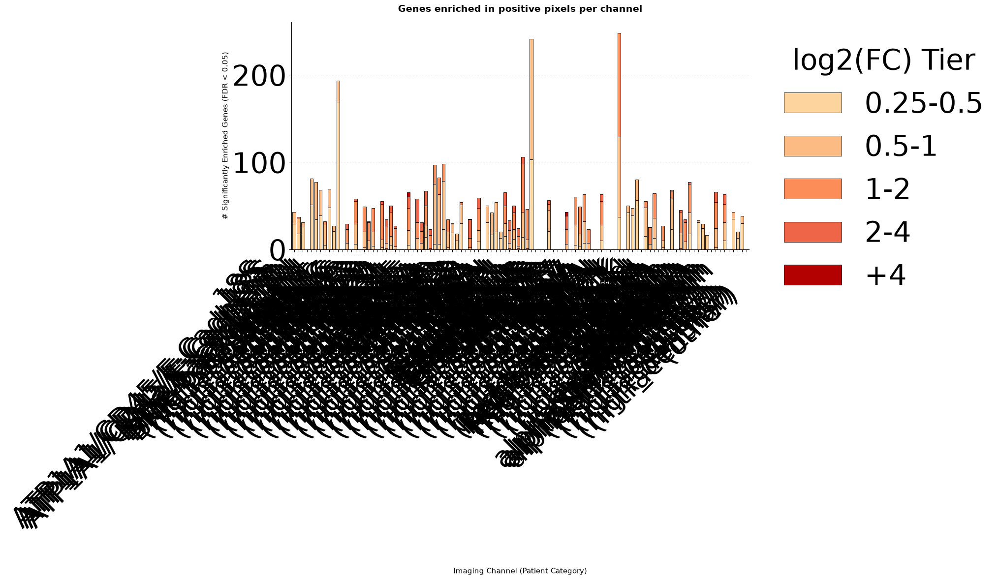

In [22]:
plot_significant_gene_counts(df_gene_category_enrichment)

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_gene_enrichment_dotplot(
    df: pd.DataFrame, 
    alpha: float = 0.05, 
    top_n_per_cond: int = 5
):
    """
    Plots a dot plot showing enrichment magnitude (color) and significance (size)
    for top enriched/depleted genes across categories and channels.
    """
    df = df.copy()
    
    # 1. Calculate transformation metrics
    # Small epsilon to avoid log2(0) or log10(0)
    df["log2_ER"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    df["neg_log10_padj"] = -np.log10(df["pvalue_adj"] + 1e-10)
    
    # Filter for significant rows to select our "interesting" genes
    sig_df = df[df["pvalue_adj"] < alpha]
    
    if sig_df.empty:
        print("No significant genes found at the specified alpha level.")
        return

    # 2. Smartly select top genes so the plot isn't overcrowded
    # Grab top N most enriched and top N most depleted per category/channel combination
    top_enriched = sig_df.groupby(["category", "channel"]) \
                         .apply(lambda x: x.nlargest(top_n_per_cond, "log2_ER"), include_groups=False)
    top_depleted = sig_df.groupby(["category", "channel"]) \
                         .apply(lambda x: x.nsmallest(top_n_per_cond, "log2_ER"), include_groups=False)
    
    genes_to_show = pd.concat([top_enriched, top_depleted])["gene"].unique()
    plot_data = df[df["gene"].isin(genes_to_show)].copy()
    
    # 3. Create the Faceted Plot
    sns.set_theme(style="whitegrid")
    g = sns.relplot(
        data=plot_data,
        x="channel",
        y="gene",
        hue="log2_ER",
        size="neg_log10_padj",
        col="category",
        palette="vlag",  # Diverging color map (blue = depleted, red = enriched)
        hue_norm=(-3, 3), # Clamp color scale for better visibility; adjust as needed
        sizes=(20, 200),  # Min and max size of dots
        kind="scatter",
        aspect=0.8,
        height=min(max(len(genes_to_show) * 0.25, 4), 12) # Dynamically scale height
    )
    
    # Titles and formatting
    g.set_titles(col_template="{col_name} Category")
    g.set_axis_labels("Imaging Channel", "Gene")
    g.tight_layout()
    
    # Adjust legends
    g._legend.set_title(None)
    for t in g._legend.texts:
        if "log2_ER" in t.get_text(): t.set_text("Log2 Enrichment")
        if "neg_log10_padj" in t.get_text(): t.set_text("-Log10 Adj P-val")
        
    plt.show()

def plot_gene_enrichment_heatmap(df: pd.DataFrame, alpha: float = 0.05, top_n_total: int = 40):
    """
    Plots a hierarchically clustered heatmap of Log2 Enrichment Ratios.
    Genes with similar behavior across channels/categories cluster together.
    """
    df = df.copy()
    df["log2_ER"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    
    # Select genes based on variance or highest absolute enrichment to keep plot clean
    # Here we select genes that show the highest absolute deviation from 0
    df["abs_log2_ER"] = df["log2_ER"].abs()
    sig_df = df[df["pvalue_adj"] < alpha]
    
    top_genes = sig_df.groupby("gene")["abs_log2_ER"].max() \
                      .nlargest(top_n_total).index
                      
    df_filtered = df[df["gene"].isin(top_genes)]
    
    if df_filtered.empty:
        print("No significant data to display in heatmap.")
        return
        
    # Pivot data: rows = genes, columns = combination of channel and category
    pivot_df = df_filtered.pivot(
        index="gene", 
        columns=["category", "channel"], 
        values="log2_ER"
    ).fillna(0) # 0 means no enrichment change / expected random background
    
    # Plot the clustered heatmap
    g = sns.clustermap(
        pivot_df,
        cmap="vlag",       # Blue-white-red diverging palette
        center=0,          # Center colorbar at 0 (no enrichment change)
        linewidths=0.0,
        figsize=(12, 10),
        cbar_kws={'label': 'Log2 Enrichment Ratio\n(Red=Enriched, Blue=Depleted)'}
    )
    
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
    g.fig.suptitle(f"Hierarchical Clustering of Top {top_n_total} Significant Genes", y=1.02, fontsize=14, fontweight='bold')
    plt.show()

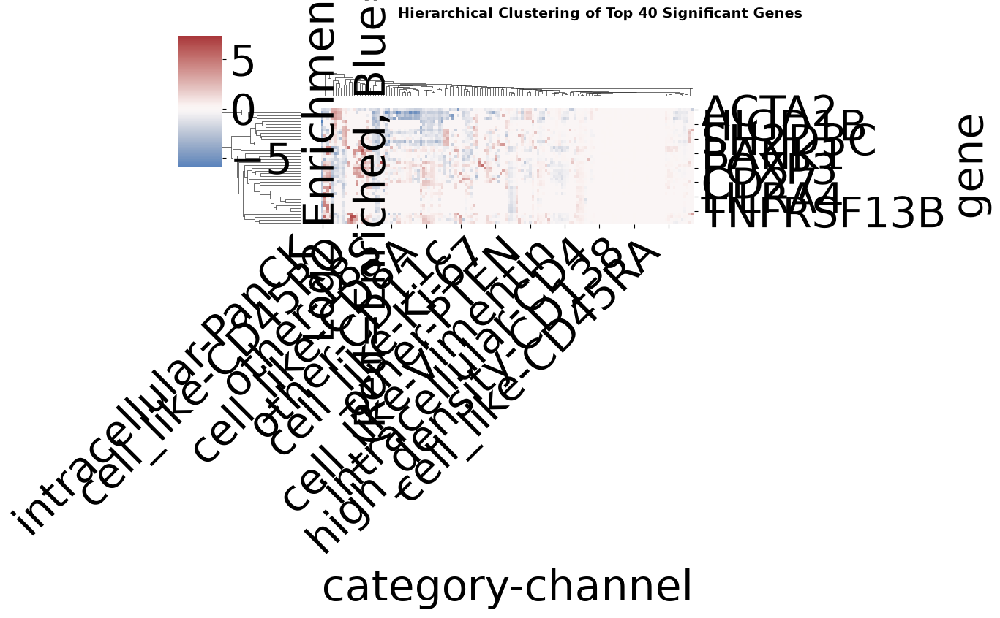

In [24]:
plot_gene_enrichment_heatmap(df_gene_category_enrichment)

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

def plot_channel_vs_channel_logfc(
    df_gene_category_enrichment: pd.DataFrame,
    target_category: str,
    channel_x: str,
    channel_y: str,
    df_summary: pd.DataFrame = None,  # Pass your df_summary table here!
    pct_x: float = None,              # Manual override for channel X percentage
    pct_y: float = None,              # Manual override for channel Y percentage
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 5,
    saving_path: str = None,
):
    """Plots logFC of channel_x vs channel_y for a given transcript category.

    Automatically extracts channel positive pixel percentages from df_summary
    and embeds them directly into the X and Y axis labels.
    """
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    df = df_gene_category_enrichment.copy()

    # 1. Filter for the specific transcript category
    cat_df = df[df["category"] == target_category].copy()
    if cat_df.empty:
        print(f"No data found for transcript category: '{target_category}'")
        return

    # Calculate logFC upfront
    cat_df["logFC"] = np.log2(cat_df["enrichment_ratio"].replace(0, np.nan))

    # 2. Extract channel pixel percentages dynamically from df_summary
    val_x, val_y = pct_x, pct_y

    if df_summary is not None and (val_x is None or val_y is None):
        # Look up based on the column structures produced by analyze_channels_and_get_thresholds
        ch_col = "Channel Name" if "Channel Name" in df_summary.columns else df_summary.columns[0]
        pct_col = [c for c in df_summary.columns if "Positive Pixels" in c or "pct" in c.lower()]
        
        if pct_col:
            pct_col_name = pct_col[0]
            try:
                if val_x is None:
                    val_x = df_summary[df_summary[ch_col] == channel_x][pct_col_name].iloc[0]
                if val_y is None:
                    val_y = df_summary[df_summary[ch_col] == channel_y][pct_col_name].iloc[0]
            except IndexError:
                pass

    # Build final label texts for the axes layout
    label_x_text = f"{channel_x} ({val_x:.1f}%)" if val_x is not None else f"{channel_x}"
    label_y_text = f"{channel_y} ({val_y:.1f}%)" if val_y is not None else f"{channel_y}"

    # 3. Separate datasets for Channel X and Channel Y, then merge on Gene
    df_x = cat_df[cat_df["channel"] == channel_x][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_x", "pvalue_adj": "padj_x"})
    df_y = cat_df[cat_df["channel"] == channel_y][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_y", "pvalue_adj": "padj_y"})

    merged = pd.merge(df_x, df_y, on="gene", how="inner")

    if merged.empty:
        print(f"No overlapping genes found between {channel_x} and {channel_y}.")
        return

    # 4. Apply Dual-Gating Filters for Significance (FDR AND logFC magnitude)
    sig_x = (merged["padj_x"] < alpha) & (merged["logFC_x"].abs() >= logfc_thr)
    sig_y = (merged["padj_y"] < alpha) & (merged["logFC_y"].abs() >= logfc_thr)

    conditions = [sig_x & sig_y, sig_x & ~sig_y, ~sig_x & sig_y]
    choices = ["Both", f"{channel_x} Only", f"{channel_y} Only"]
    merged["Significance_Type"] = np.select(
        conditions, choices, default="Not Significant"
    )
    merged["is_significant"] = sig_x | sig_y

    # 5. Plotting Setup
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(7, 7))

    min_val = min(merged["logFC_x"].min(), merged["logFC_y"].min()) - 0.5
    max_val = max(merged["logFC_x"].max(), merged["logFC_y"].max()) + 0.5
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        alpha=0.4,
        label="Equal Enrichment ($y=x$)",
    )

    # Threshold indicator lines
    ax.axhline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axhline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axhline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)

    color_dict = {
        "Both": "#6a3d9a",
        f"{channel_x} Only": "#1f77b4",
        f"{channel_y} Only": "#ff7f0e",
        "Not Significant": "#e0e0e0",
    }

    sns.scatterplot(
        data=merged,
        x="logFC_x",
        y="logFC_y",
        hue="Significance_Type",
        palette=color_dict,
        hue_order=["Both", f"{channel_x} Only", f"{channel_y} Only", "Not Significant"],
        alpha=0.9,
        edgecolor="w",
        linewidth=0.01,
        s=10,
        ax=ax,
    )

    # 6. Labeling outliers
    sig_pool = merged[merged["is_significant"]].copy()
    if not sig_pool.empty:
        top_x = sig_pool.loc[sig_pool["logFC_x"].abs().nlargest(top_n_labels).index]
        top_y = sig_pool.loc[sig_pool["logFC_y"].abs().nlargest(top_n_labels).index]
        labels_df = pd.concat([top_x, top_y]).drop_duplicates(subset=["gene"])

        texts = []
        for _, row in labels_df.iterrows():
            if pd.isna(row["logFC_x"]) or pd.isna(row["logFC_y"]):
                continue
            texts.append(
                ax.text(
                    row["logFC_x"],
                    row["logFC_y"],
                    row["gene"],
                    fontsize=9,
                    fontweight="semibold",
                )
            )

        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5),
            )
        except ImportError:
            pass

    # Styling and Polish
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Spatial Localization Preference ({target_category})\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=11,
        fontweight="bold",
        pad=12,
    )
    ax.set_xlabel(f"$\log_2$ Enrichment in {label_x_text}", fontsize=11)
    ax.set_ylabel(f"$\log_2$ Enrichment in {label_y_text}", fontsize=11)

    plt.legend(frameon=False, loc="upper left")
    plt.tight_layout()

    # 7. Dynamically Construct Sanitized Name and Save File
    if saving_path is not None:
        clean_cat = target_category.replace("/", "_").replace(" ", "_")
        clean_x = channel_x.replace("/", "_")
        clean_y = channel_y.replace("/", "_")

        filename = f"{clean_x}_vs_{clean_y}_{clean_cat}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

In [26]:
for cat in df_gene_category_enrichment['category'].unique():
    plot_channel_vs_channel_logfc(
        df_gene_category_enrichment=df_gene_category_enrichment,
        df_summary=df_summary,    
        target_category=cat,
        channel_x="18S",
        channel_y="AlphaSMA/Vimentin",
        top_n_labels=5,saving_path=saving_path
    )

No overlapping genes found between 18S and AlphaSMA/Vimentin.
No overlapping genes found between 18S and AlphaSMA/Vimentin.
No overlapping genes found between 18S and AlphaSMA/Vimentin.
No overlapping genes found between 18S and AlphaSMA/Vimentin.


In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns


def plot_category_vs_category_logfc(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    category_x: str,
    category_y: str,
    df_summary: pd.DataFrame = None,  # Total channel pixel coverage summary
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 5,
    saving_path: str = None,
):
    """Plots logFC of category_x vs category_y for a given single channel.

    Dynamically isolates the exact observed % of positive pixels unique to each 
    transcript category group and explicitly appends them to the X and Y axis labels.
    """
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    df = df_gene_category_enrichment.copy()

    # 1. Filter dataset for the chosen channel
    ch_df = df[df["channel"] == target_channel].copy()
    if ch_df.empty:
        print(f"No data found for channel: '{target_channel}'")
        return

    # Calculate logFC upfront
    ch_df["logFC"] = np.log2(ch_df["enrichment_ratio"].replace(0, np.nan))

    # 2. Extract Overall Channel positive pixel percentage from df_summary
    val_pct = None
    if df_summary is not None:
        ch_col = "Channel Name" if "Channel Name" in df_summary.columns else df_summary.columns[0]
        pct_col = [c for c in df_summary.columns if "Positive Pixels" in c or "pct" in c.lower()]
        if pct_col:
            pct_col_name = pct_col[0]
            try:
                val_pct = df_summary[df_summary[ch_col] == target_channel][pct_col_name].iloc[0]
            except IndexError:
                pass

    ch_label = f"{target_channel} ({val_pct:.1f}%)" if val_pct is not None else f"{target_channel}"

    # 3. FIXED: Extract the unique Category-Specific Positivity Percentages
    pct_cat_x = None
    pct_cat_y = None
    
    try:
        pct_cat_x = ch_df[ch_df["category"] == category_x]["pct_positive_observed"].median()
        pct_cat_y = ch_df[ch_df["category"] == category_y]["pct_positive_observed"].median()
    except (KeyError, IndexError):
        pass

    # Build axis labels with the category-specific % embedded directly
    label_x_text = f"'{category_x}' ({pct_cat_x:.1f}%)" if pct_cat_x is not None and not np.isnan(pct_cat_x) else f"'{category_x}'"
    label_y_text = f"'{category_y}' ({pct_cat_y:.1f}%)" if pct_cat_y is not None and not np.isnan(pct_cat_y) else f"'{category_y}'"

    # 4. Separate datasets for Category X and Category Y, then merge on Gene
    df_x = ch_df[ch_df["category"] == category_x][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_x", "pvalue_adj": "padj_x"})
    
    df_y = ch_df[ch_df["category"] == category_y][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_y", "pvalue_adj": "padj_y"})

    merged = pd.merge(df_x, df_y, on="gene", how="inner")

    if merged.empty:
        print(f"No overlapping genes found between category '{category_x}' and '{category_y}'.")
        return

    # 5. Apply Dual-Gating Filters for Significance (FDR AND logFC magnitude)
    sig_x = (merged["padj_x"] < alpha) & (merged["logFC_x"].abs() >= logfc_thr)
    sig_y = (merged["padj_y"] < alpha) & (merged["logFC_y"].abs() >= logfc_thr)

    conditions = [sig_x & sig_y, sig_x & ~sig_y, ~sig_x & sig_y]
    choices = ["Both", f"{category_x} Only", f"{category_y} Only"]
    merged["Significance_Type"] = np.select(
        conditions, choices, default="Not Significant"
    )
    merged["is_significant"] = sig_x | sig_y

    # 6. Plotting Setup
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(7, 7))

    min_val = min(merged["logFC_x"].min(), merged["logFC_y"].min()) - 0.5
    max_val = max(merged["logFC_x"].max(), merged["logFC_y"].max()) + 0.5
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        alpha=0.4,
        label="Equal Enrichment ($y=x$)",
    )

    # Threshold indicator lines
    ax.axhline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axhline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axhline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)

    color_dict = {
        "Both": "#41bda5",
        f"{category_x} Only": "#ed2474",
        f"{category_y} Only": "#123755",
        "Not Significant": "#e0e0e0",
    }

    sns.scatterplot(
        data=merged,
        x="logFC_x",
        y="logFC_y",
        hue="Significance_Type",
        palette=color_dict,
        hue_order=["Both", f"{category_x} Only", f"{category_y} Only", "Not Significant"],
        alpha=0.9,
        edgecolor="w",
        linewidth=0.01,
        s=10,
        ax=ax,
    )

    # 7. Labeling outliers
    sig_pool = merged[merged["is_significant"]].copy()
    if not sig_pool.empty:
        top_x = sig_pool.loc[sig_pool["logFC_x"].abs().nlargest(top_n_labels).index]
        top_y = sig_pool.loc[sig_pool["logFC_y"].abs().nlargest(top_n_labels).index]
        labels_df = pd.concat([top_x, top_y]).drop_duplicates(subset=["gene"])

        texts = []
        for _, row in labels_df.iterrows():
            if pd.isna(row["logFC_x"]) or pd.isna(row["logFC_y"]):
                continue
            texts.append(
                ax.text(
                    row["logFC_x"],
                    row["logFC_y"],
                    row["gene"],
                    fontsize=9,
                    fontweight="semibold",
                )
            )

        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5),
            )
        except ImportError:
            pass

    # Styling and Polish
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Transcript Category Comparison ({ch_label})\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=11,
        fontweight="bold",
        pad=12,
    )
    
    # Axis labels displaying the unique category positivity rates
    ax.set_xlabel(f"$\log_2$ Enrichment in {label_x_text}", fontsize=11)
    ax.set_ylabel(f"$\log_2$ Enrichment in {label_y_text}", fontsize=11)

    plt.legend(frameon=False, loc="upper left")
    plt.tight_layout()

    # 8. Dynamically Construct Sanitized Name and Save File
    if saving_path is not None:
        clean_ch = target_channel.replace("/", "_").replace(" ", "_")
        clean_cat_x = category_x.replace("/", "_").replace(" ", "_")
        clean_cat_y = category_y.replace("/", "_").replace(" ", "_")

        filename = f"{clean_ch}_{clean_cat_x}_vs_{clean_cat_y}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

In [28]:
plot_category_vs_category_logfc(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="AlphaSMA/Vimentin",
    category_x="intracellular",
    category_y="other",
    saving_path=saving_path
)

No data found for channel: 'AlphaSMA/Vimentin'


In [37]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_all_channels_logfc_by_category(
    df_gene_category_enrichment: pd.DataFrame,
    target_category: str,
    df_summary: pd.DataFrame = None,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 3,
    saving_path: str = None,
):
    """Generates a 1D strip/box plot with all font sizes set to 42pt,

    regular (non-bold) text, and non-overlapping gene labels.
    """
    # Vector font compatibility & global base font size = 42
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    mpl.rcParams.update({"font.size": 42})

    df = df_gene_category_enrichment.copy()

    # 1. Filter for specific transcript category & exclude channels containing 'background'
    cat_df = df[df["category"] == target_category].copy()
    cat_df = cat_df[
        ~cat_df["channel"].str.contains("background", case=False, na=False)
    ]

    if cat_df.empty:
        print(f"No data found for transcript category: '{target_category}'")
        return

    # 2. Calculate logFC
    cat_df["logFC"] = np.log2(cat_df["enrichment_ratio"].replace(0, np.nan))

    # 3. Apply Dual-Gating Filters for Significance
    cat_df["is_significant"] = (cat_df["pvalue_adj"] < alpha) & (
        cat_df["logFC"].abs() >= logfc_thr
    )
    cat_df["Significance"] = np.where(
        cat_df["is_significant"], "Significant", "Not Significant"
    )

    # 4. Extract Dynamic Channel Labels & Map to Numeric Y-Indices
    channel_labels = {}
    unique_channels = cat_df["channel"].unique()

    for ch in unique_channels:
        label_text = ch
        if df_summary is not None:
            ch_col = (
                "Channel Name"
                if "Channel Name" in df_summary.columns
                else df_summary.columns[0]
            )
            pct_col = [
                c
                for c in df_summary.columns
                if "Positive Pixels" in c or "pct" in c.lower()
            ]

            if pct_col:
                try:
                    val = df_summary[df_summary[ch_col] == ch][pct_col[0]].iloc[
                        0
                    ]
                    label_text = f"{ch} ({val:.1f}%)"
                except IndexError:
                    pass
        channel_labels[ch] = label_text

    ordered_labels = [channel_labels[ch] for ch in unique_channels]

    # Map channels to discrete numeric y-positions
    ch_to_y = {ch: i for i, ch in enumerate(unique_channels)}
    cat_df["y_pos"] = cat_df["channel"].map(ch_to_y)

    # 5. Figure Setup - Scaled width/height to fit 42pt text comfortably
    sns.set_theme(style="ticks")

    num_channels = len(unique_channels)
    # Height scales with 1.2 inches per channel to keep 42pt vertical labels spaced
    fig_height = max(8.0, num_channels * 1.2)
    fig, ax = plt.subplots(figsize=(24, fig_height))

    # Threshold indicator lines
    ax.axvline(0, color="grey", linestyle="-", alpha=0.4, linewidth=2.0)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.4, linewidth=2.0)
    ax.axvline(
        -logfc_thr, color="grey", linestyle=":", alpha=0.4, linewidth=2.0
    )

    # Boxplots mapped on numeric y
    sns.boxplot(
        data=cat_df,
        x="logFC",
        y="y_pos",
        orient="h",
        color="#e0e0e0",
        fliersize=0,
        width=0.4,
        boxprops=dict(alpha=0.3),
        ax=ax,
    )

    # Strip plot mapped on numeric y
    palette = {"Significant": "#c84641", "Not Significant": "#efc3af"}
    sns.stripplot(
        data=cat_df,
        x="logFC",
        y="y_pos",
        orient="h",
        hue="Significance",
        palette=palette,
        hue_order=["Significant", "Not Significant"],
        alpha=0.75,
        jitter=0.15,
        size=7,  # Smaller dot size
        ax=ax,
    )

    # 6. Label Top Significant Outliers per Channel (Regular font, 42pt)
    texts = []
    for ch_name in unique_channels:
        ch_sig = cat_df[
            (cat_df["channel"] == ch_name) & cat_df["is_significant"]
        ]
        if not ch_sig.empty:
            top_genes = ch_sig.loc[
                ch_sig["logFC"].abs().nlargest(top_n_labels).index
            ]
            y_val = ch_to_y[ch_name]

            for _, row in top_genes.iterrows():
                texts.append(
                    ax.text(
                        row["logFC"],
                        y_val,
                        row["gene"],
                        fontsize=42,
                        fontweight="normal",  # Regular (not bold)
                    )
                )

    # Enhanced adjust_text configuration tuned for large 42pt text collisions
    if texts:
        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                expand_text=(2.0, 2.5),
                expand_points=(2.0, 2.5),
                force_text=(1.2, 1.8),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
            )
        except ImportError:
            pass

    # 7. Axis bounds and tight vertical layout
    ax.set_yticks(range(num_channels))
    ax.set_yticklabels(ordered_labels, fontsize=42, fontweight="normal")
    ax.set_ylim(num_channels - 0.5, -0.5)  # Inverted so first channel is top

    # Styling and Polish
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Channel Enrichment Distribution for {target_category}\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=42,
        fontweight="normal",  # Regular (not bold)
        pad=20,
    )
    ax.set_xlabel("$\log_2$ Enrichment Ratio", fontsize=42, fontweight="normal")
    ax.set_ylabel("Channels", fontsize=42, fontweight="normal")
    ax.tick_params(labelsize=42)

    # Remove duplicates from legend (caused by Seaborn layering)
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(
        by_label.values(),
        by_label.keys(),
        frameon=False,
        loc="upper right",
        fontsize=42,
        markerscale=2.0,
        bbox_to_anchor=(1.0, 1.1),
    )

    plt.tight_layout()

    # 8. Exporting File
    if saving_path is not None:
        clean_cat = target_category.replace("/", "_").replace(" ", "_")
        filename = f"Channels_1D_Enrichment_{clean_cat}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

In [38]:
df_gene_category_enrichment

,gene,category,channel,n_transcripts,pct_positive_observed,pct_positive_expected_random,pct_positive_expected_std,enrichment_ratio,pvalue,pvalue_adj
0,ACE2,intracellular,DAPI,397,55.163728,46.091940,2.335581,1.196819,0.004975,0.006752
1,ACTA2,intracellular,DAPI,85750,42.770845,46.266309,0.155918,0.924449,1.000000,1.000000
2,ACTG2,intracellular,DAPI,22792,41.268866,46.256515,0.334136,0.892174,1.000000,1.000000
3,ADAM28,intracellular,DAPI,9179,59.363765,46.313705,0.562463,1.281775,0.004975,0.006752
4,ADAMTS1,intracellular,DAPI,37551,52.384757,46.258209,0.271631,1.132442,0.004975,0.006752
...,...,...,...,...,...,...,...,...,...,...
38880,RTKN2,other,E-Cadherin,176,0.000000,0.414773,0.494383,0.000000,1.000000,1.000000
38881,SH2D3C,other,E-Cadherin,146,1.369863,0.421233,0.529118,3.252033,0.134328,1.000000
38882,IL3RA,other,E-Cadherin,149,0.000000,0.446309,0.558611,0.000000,1.000000,1.000000
38883,CCR2,other,E-Cadherin,139,0.000000,0.460432,0.571207,0.000000,1.000000,1.000000


Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Channels_1D_Enrichment_intracellular.pdf


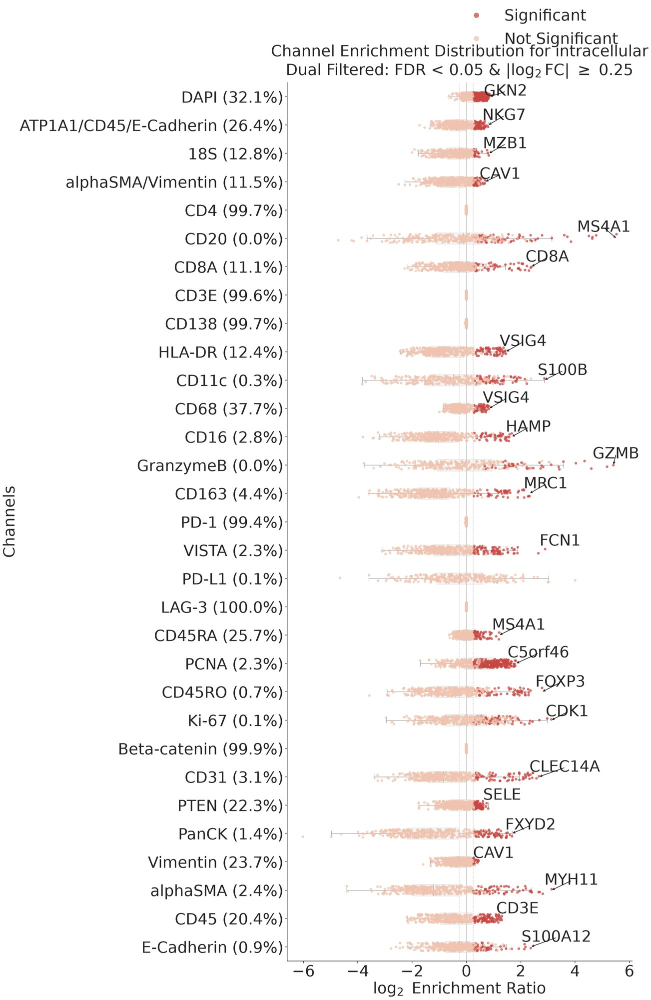

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Channels_1D_Enrichment_cell_like.pdf


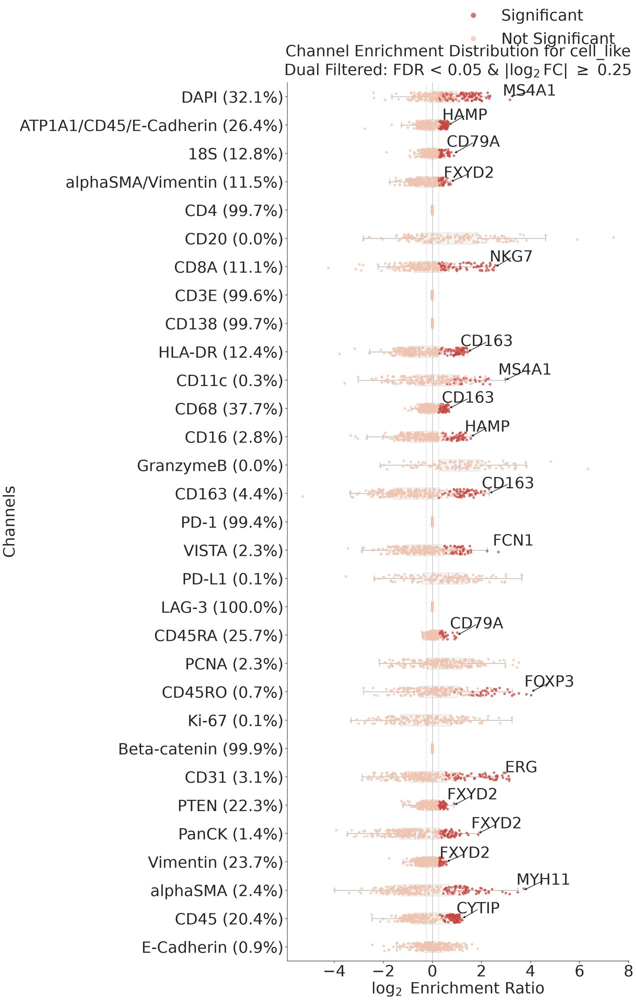

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Channels_1D_Enrichment_high_density.pdf


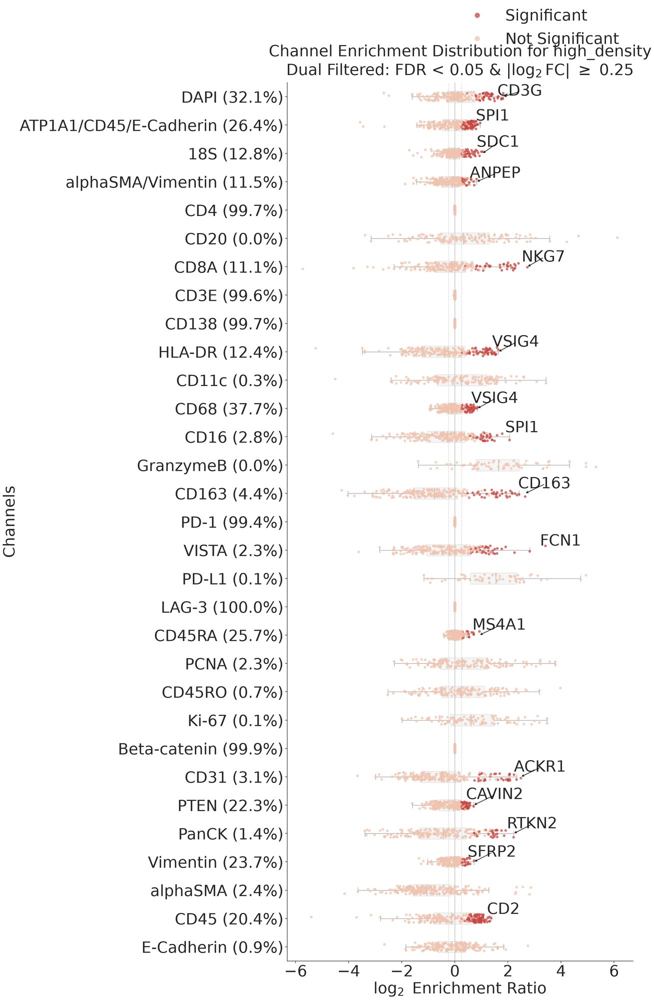

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Channels_1D_Enrichment_other.pdf


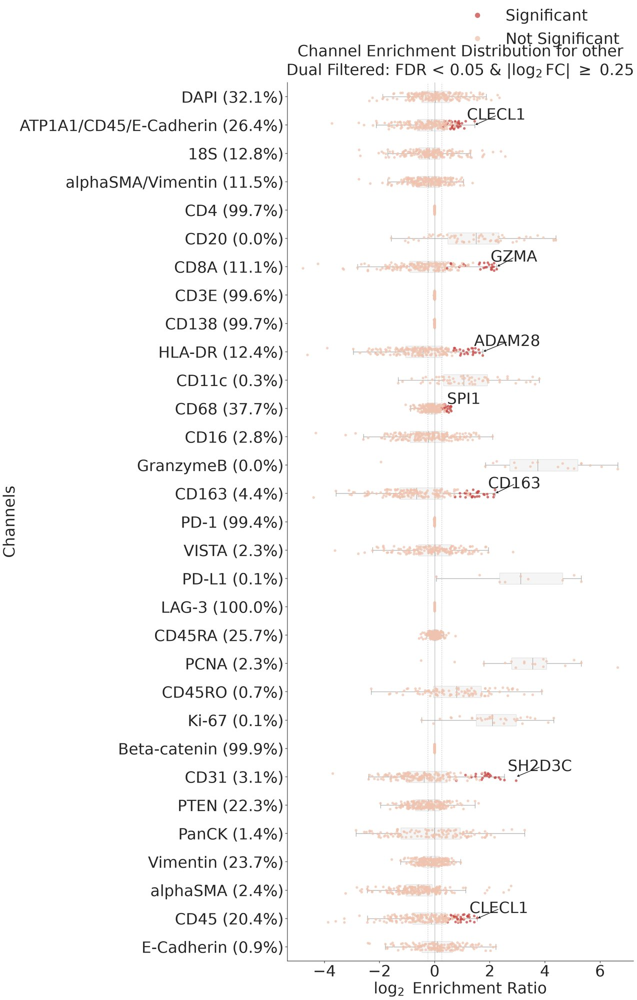

In [39]:
for cat in df_gene_category_enrichment["category"].unique():
    plot_all_channels_logfc_by_category(
        df_gene_category_enrichment=df_gene_category_enrichment,
        target_category=cat,
        df_summary=df_summary,
        alpha=0.05,
        logfc_thr=0.25,
        top_n_labels=1,
        saving_path=saving_path,
    )

In [60]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_single_channel_logfc_by_all_categories(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    df_summary: pd.DataFrame = None,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 3,
    saving_path: str = None,
):
    """Generates a 1D visualization (Strip/Box plot) for ONE staining channel across ALL transcript categories (arranged on the Y-axis).

    Font sizes are set to 42pt, non-bold, with clean layout spacing and non-
    overlapping gene labels.
    """
    # Vector font compatibility & global base font size = 42
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    mpl.rcParams.update({"font.size": 42})

    df = df_gene_category_enrichment.copy()

    # 1. Filter for the specific staining / channel
    ch_df = df[df["channel"] == target_channel].copy()
    if ch_df.empty:
        print(f"No data found for channel: '{target_channel}'")
        return

    # 2. Calculate logFC
    ch_df["logFC"] = np.log2(ch_df["enrichment_ratio"].replace(0, np.nan))

    # 3. Apply Dual-Gating Filters for Significance
    ch_df["is_significant"] = (ch_df["pvalue_adj"] < alpha) & (
        ch_df["logFC"].abs() >= logfc_thr
    )
    ch_df["Significance"] = np.where(
        ch_df["is_significant"], "Significant", "Not Significant"
    )

    # 4. Extract Dynamic Staining Label (with Pixel Percentages if df_summary is given)
    channel_display_label = target_channel
    if df_summary is not None:
        ch_col = (
            "Channel Name"
            if "Channel Name" in df_summary.columns
            else df_summary.columns[0]
        )
        pct_col = [
            c
            for c in df_summary.columns
            if "Positive Pixels" in c or "pct" in c.lower()
        ]

        if pct_col:
            try:
                val = df_summary[df_summary[ch_col] == target_channel][
                    pct_col[0]
                ].iloc[0]
                channel_display_label = f"{target_channel} ({val:.1f}%)"
            except IndexError:
                pass

    # Extract unique categories for this channel and map to discrete numeric y-positions
    unique_categories = ch_df["category"].unique()
    cat_to_y = {cat: i for i, cat in enumerate(unique_categories)}
    ch_df["y_pos"] = ch_df["category"].map(cat_to_y)

    # 5. Figure Setup - Proportionate to 42pt text and category count
    sns.set_theme(style="ticks")

    num_categories = len(unique_categories)
    fig_height = max(8.0, num_categories * 1.2)
    fig, ax = plt.subplots(figsize=(24, fig_height))

    # Threshold indicator lines
    ax.axvline(0, color="grey", linestyle="-", alpha=0.4, linewidth=2.0)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.4, linewidth=2.0)
    ax.axvline(
        -logfc_thr, color="grey", linestyle=":", alpha=0.4, linewidth=2.0
    )

    # Boxplots mapped on numeric y
    sns.boxplot(
        data=ch_df,
        x="logFC",
        y="y_pos",
        orient="h",
        color="#e0e0e0",
        fliersize=0,
        width=0.4,
        boxprops=dict(alpha=0.3),
        ax=ax,
    )

    # Strip plot mapped on numeric y
    palette = {"Significant": "#6a3d9a", "Not Significant": "#a6cee3"}
    sns.stripplot(
        data=ch_df,
        x="logFC",
        y="y_pos",
        orient="h",
        hue="Significance",
        palette=palette,
        hue_order=["Significant", "Not Significant"],
        alpha=0.75,
        jitter=0.15,
        size=10,  # Scaled point size
        ax=ax,
    )

    # 6. Label Top Significant Outliers per Category (42pt, non-bold)
    texts = []
    for cat_name in unique_categories:
        cat_sig = ch_df[
            (ch_df["category"] == cat_name) & ch_df["is_significant"]
        ]
        if not cat_sig.empty:
            top_genes = cat_sig.loc[
                cat_sig["logFC"].abs().nlargest(top_n_labels).index
            ]
            y_val = cat_to_y[cat_name]

            for _, row in top_genes.iterrows():
                texts.append(
                    ax.text(
                        row["logFC"],
                        y_val,
                        row["gene"],
                        fontsize=42,
                        fontweight="normal",  # Regular (not bold)
                    )
                )

    # Enhanced adjust_text to prevent collisions among large labels
    if texts:
        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                expand_text=(2.0, 2.5),
                expand_points=(2.0, 2.5),
                force_text=(1.2, 1.8),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
            )
        except ImportError:
            pass

    # 7. Axis bounds and Y-labels
    ax.set_yticks(range(num_categories))
    ax.set_yticklabels(unique_categories, fontsize=42, fontweight="normal")
    ax.set_ylim(
        num_categories - 0.5, -0.5
    )  # Inverted so first category is at the top

    # Styling and Polish
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Category Enrichment Distribution for Channel: {channel_display_label}\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=42,
        fontweight="normal",  # Regular (not bold)
        pad=20,
    )
    ax.set_xlabel("$\log_2$ Enrichment Ratio", fontsize=42, fontweight="normal")
    ax.set_ylabel("Transcript Categories", fontsize=42, fontweight="normal")
    ax.tick_params(labelsize=42)

    # Remove duplicates from legend (caused by Seaborn layering)
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(
        by_label.values(),
        by_label.keys(),
        frameon=False,
        loc="upper right",
        fontsize=42,
        markerscale=2.0,
        bbox_to_anchor=(1.0, 1.1),
    )

    plt.tight_layout()

    # 8. Exporting File
    if saving_path is not None:
        clean_ch = target_channel.replace("/", "_").replace(" ", "_")
        filename = f"Categories_1D_Enrichment_Channel_{clean_ch}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

Generating plot for: DAPI
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_DAPI.pdf


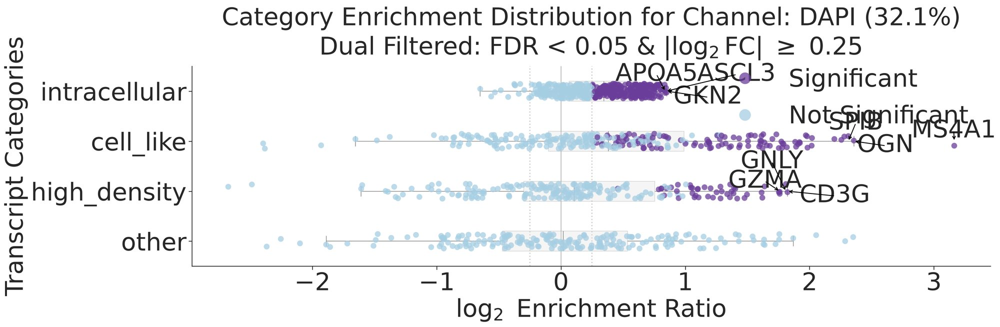

Generating plot for: ATP1A1/CD45/E-Cadherin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_ATP1A1_CD45_E-Cadherin.pdf


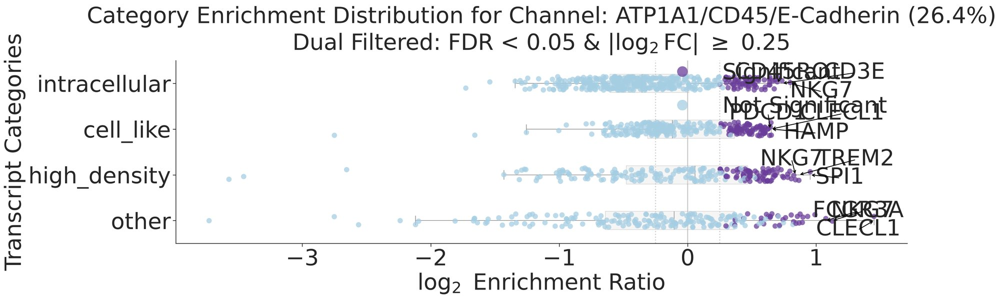

Generating plot for: 18S
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_18S.pdf


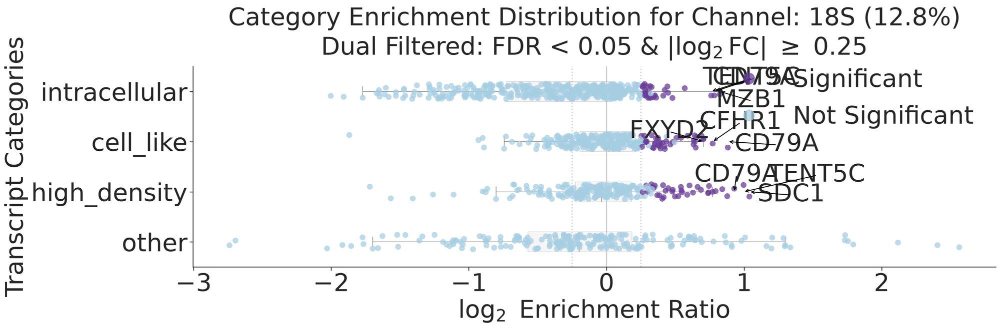

Generating plot for: alphaSMA/Vimentin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_alphaSMA_Vimentin.pdf


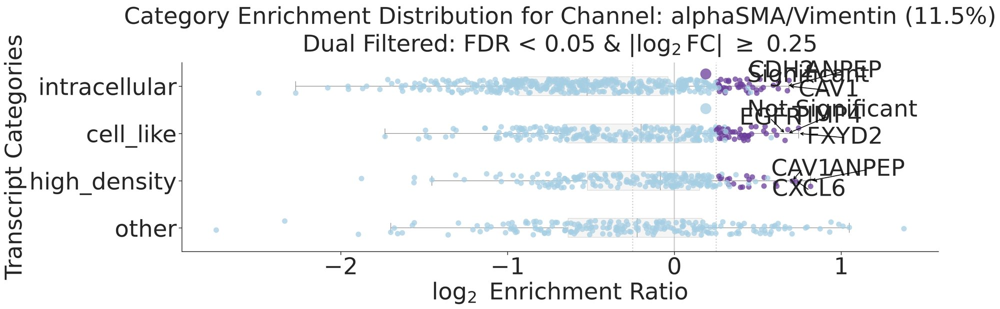

Generating plot for: Blue background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Blue_background.pdf


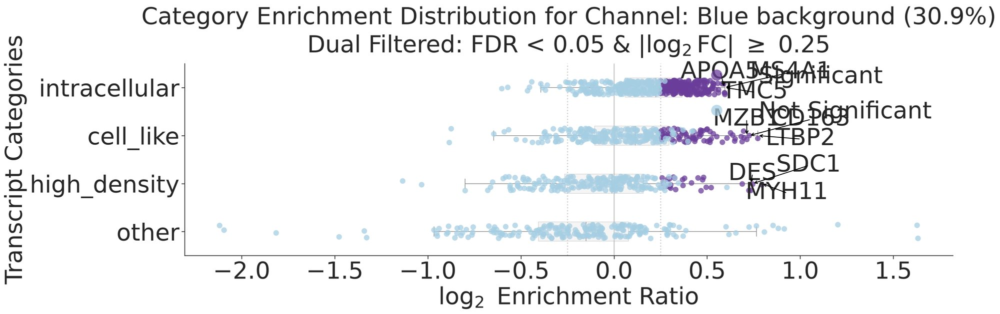

Generating plot for: Green background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Green_background.pdf


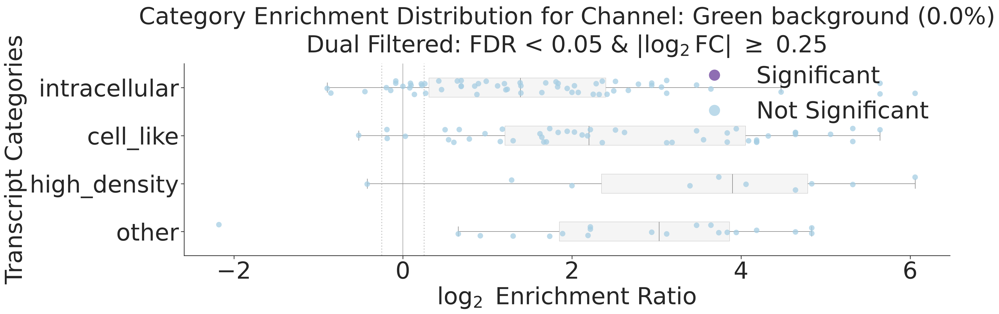

Generating plot for: Yellow background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Yellow_background.pdf


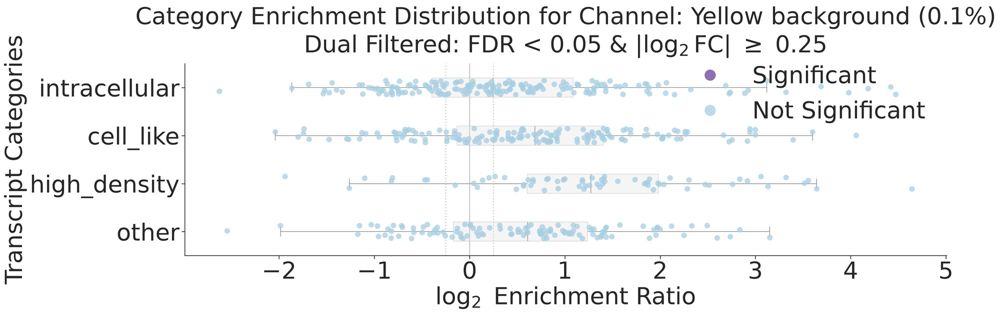

Generating plot for: Red background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Red_background.pdf


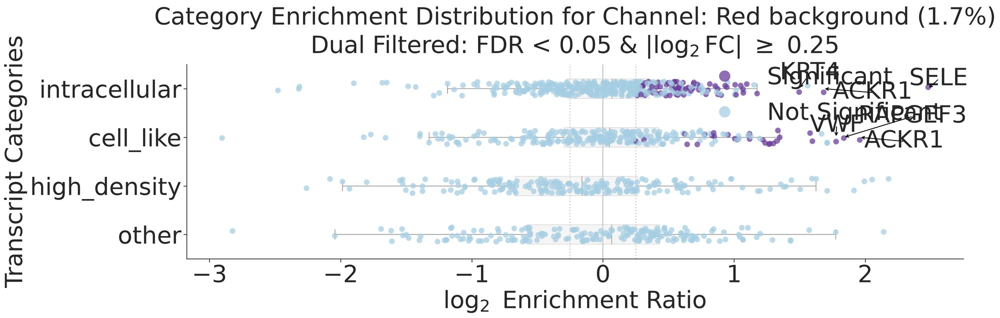

Generating plot for: CD4
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD4.pdf


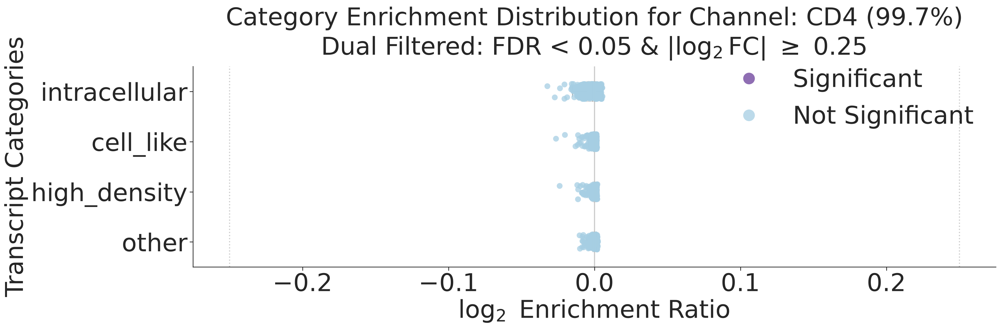

Generating plot for: CD20
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD20.pdf


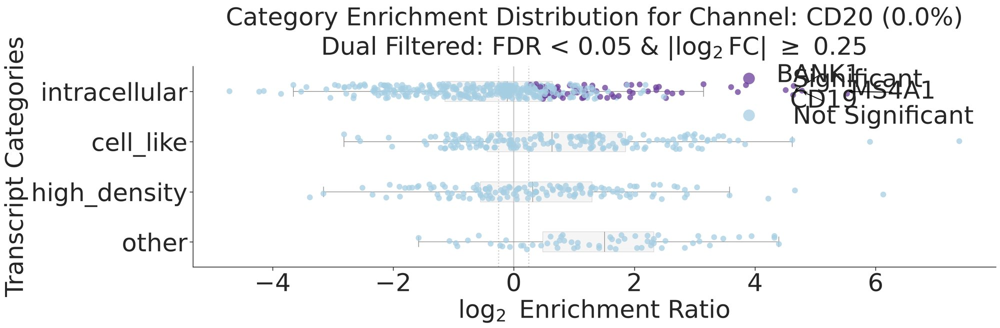

Generating plot for: CD8A
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD8A.pdf


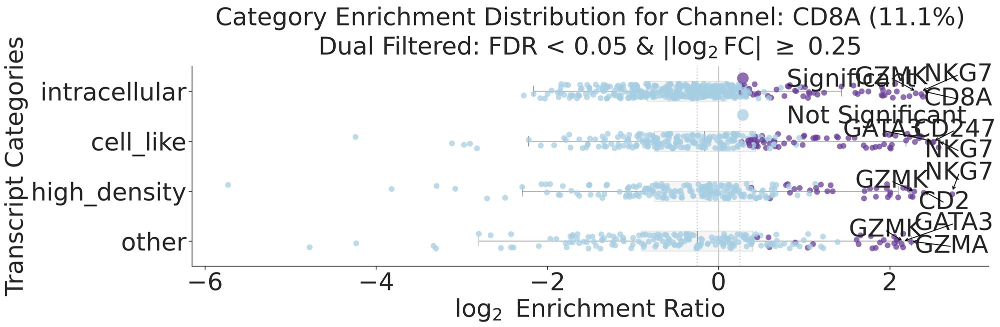

Generating plot for: CD3E
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD3E.pdf


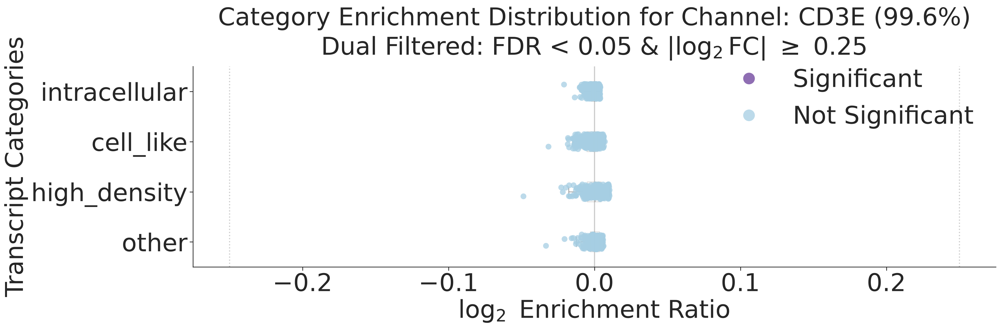

Generating plot for: CD138
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD138.pdf


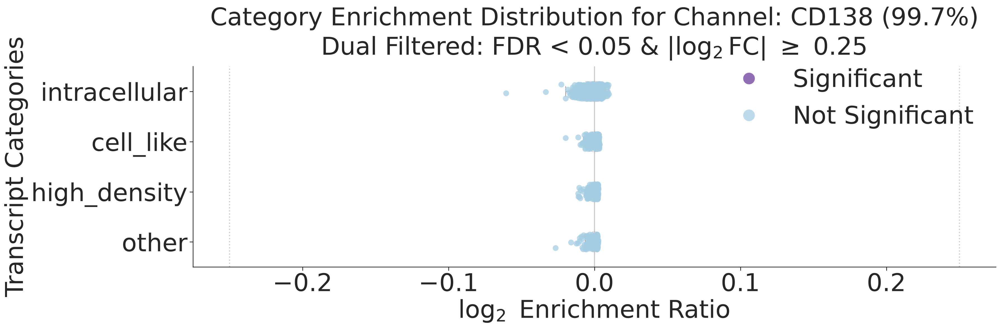

Generating plot for: HLA-DR
1 [0.08882908 0.45098147]
2 [-0.15792357 -0.57875305]
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_HLA-DR.pdf


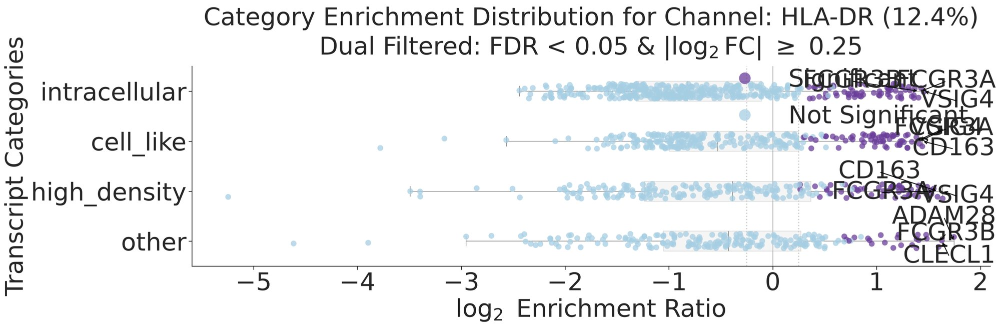

Generating plot for: CD11c
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD11c.pdf


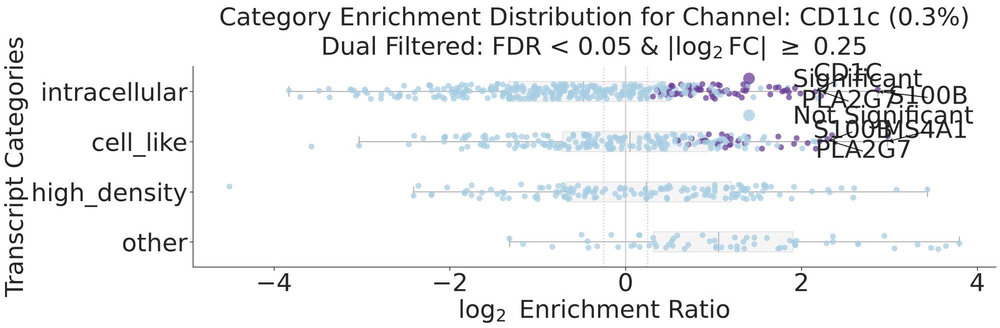

Generating plot for: CD68
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD68.pdf


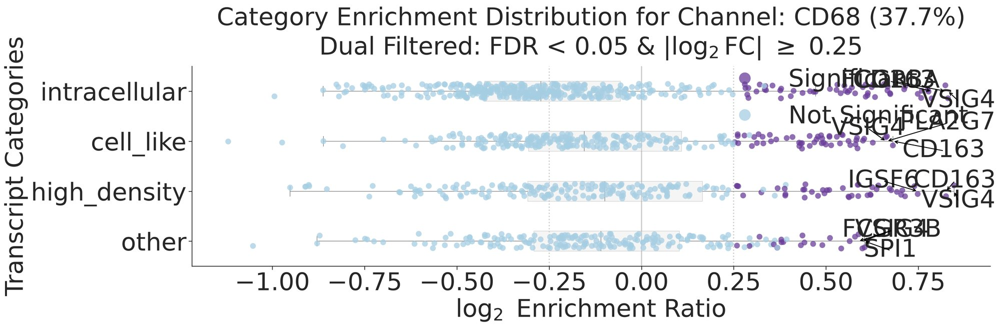

Generating plot for: CD16
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD16.pdf


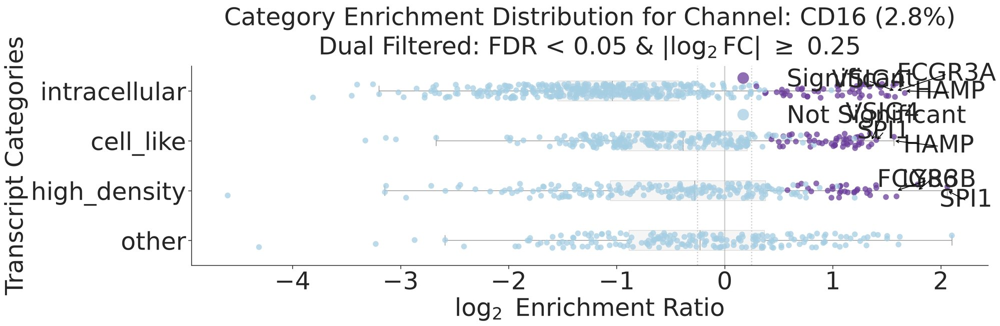

Generating plot for: GranzymeB
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_GranzymeB.pdf


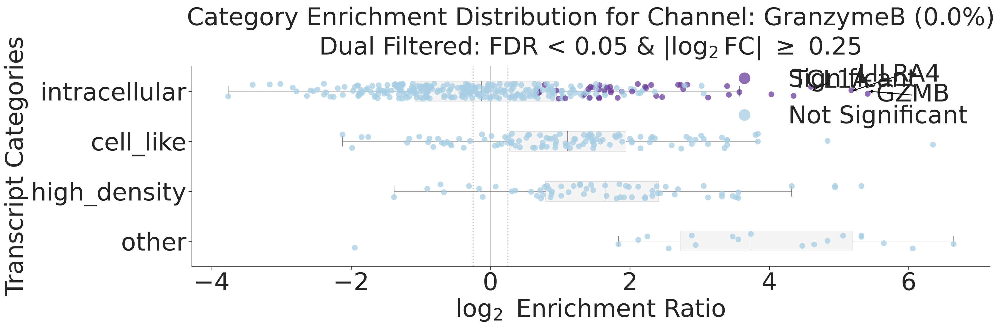

Generating plot for: CD163
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD163.pdf


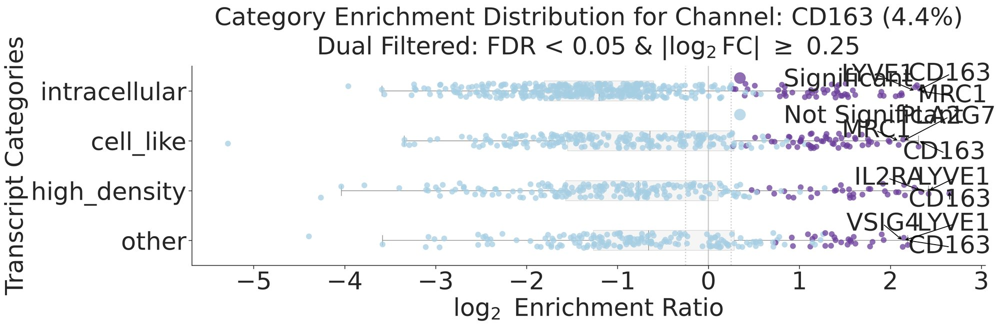

Generating plot for: PD-1
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_PD-1.pdf


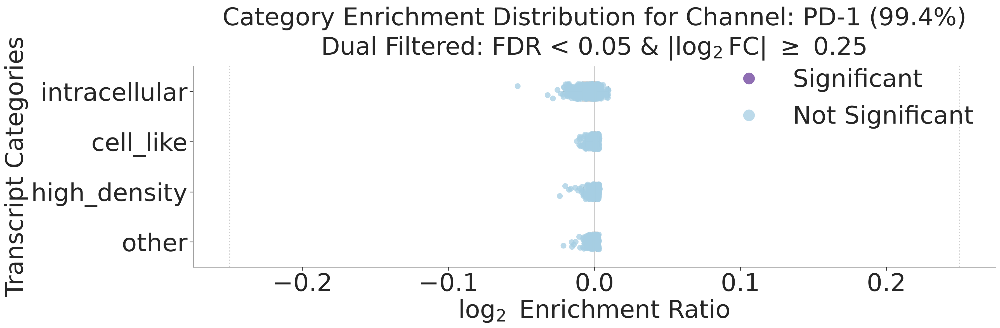

Generating plot for: VISTA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_VISTA.pdf


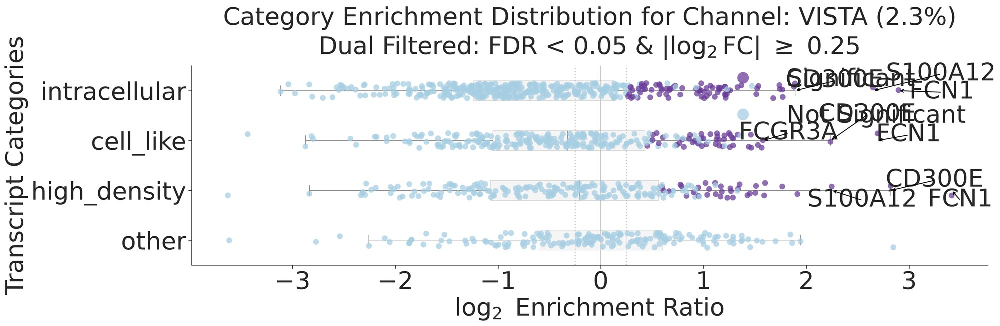

Generating plot for: PD-L1
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_PD-L1.pdf


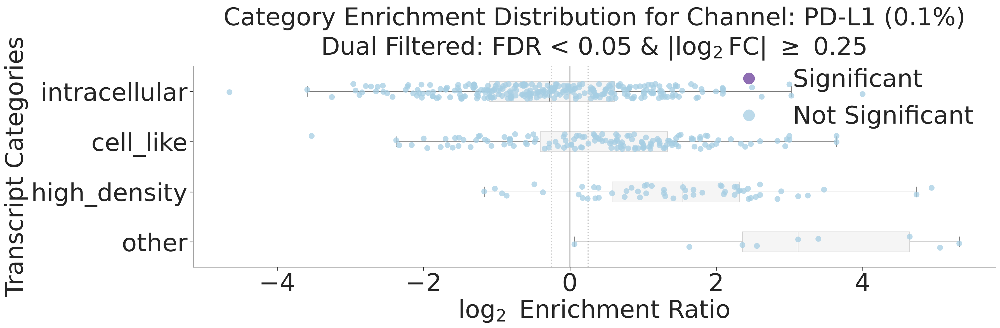

Generating plot for: LAG-3
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_LAG-3.pdf


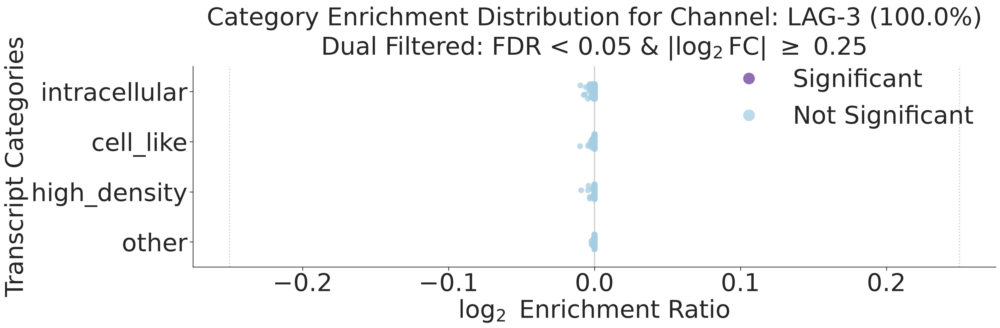

Generating plot for: CD45RA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD45RA.pdf


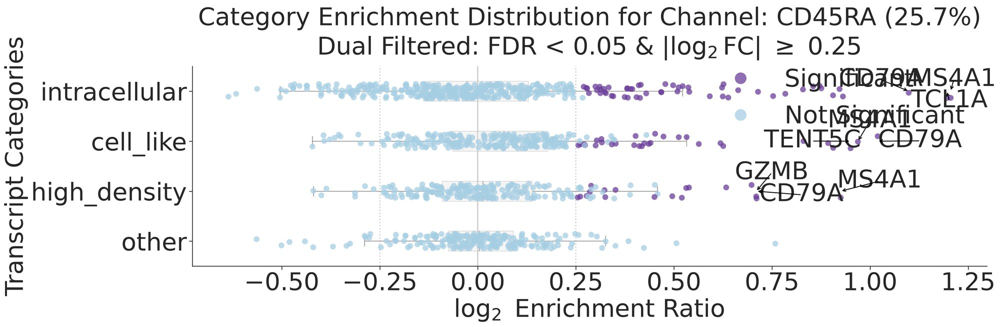

Generating plot for: PCNA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_PCNA.pdf


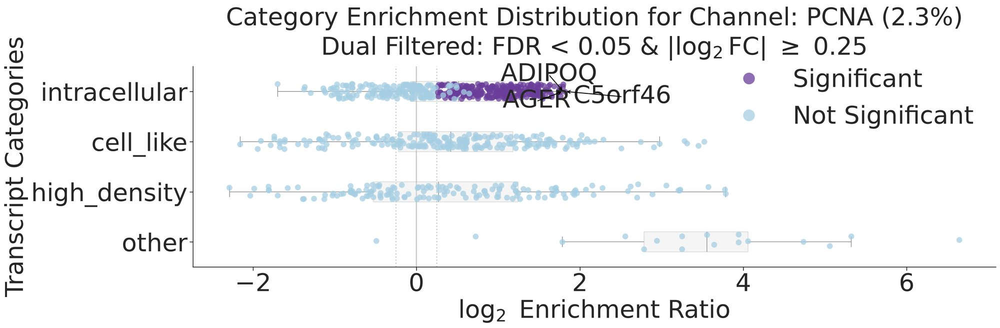

Generating plot for: CD45RO
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD45RO.pdf


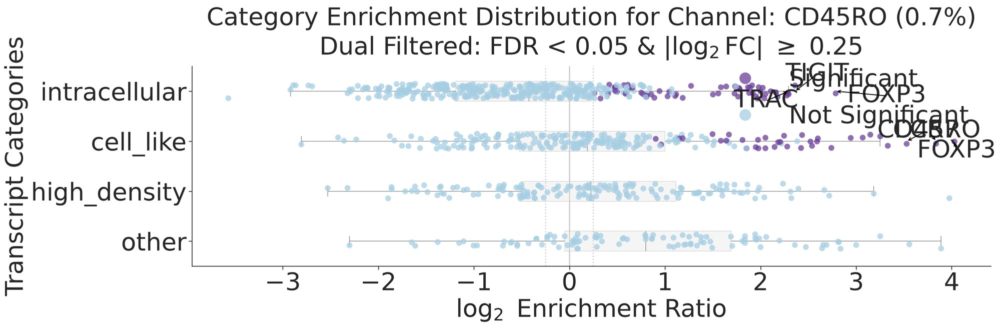

Generating plot for: Ki-67
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Ki-67.pdf


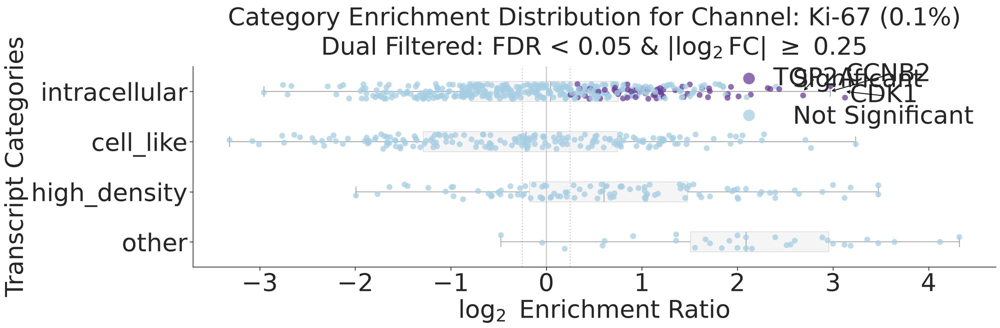

Generating plot for: Beta-catenin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Beta-catenin.pdf


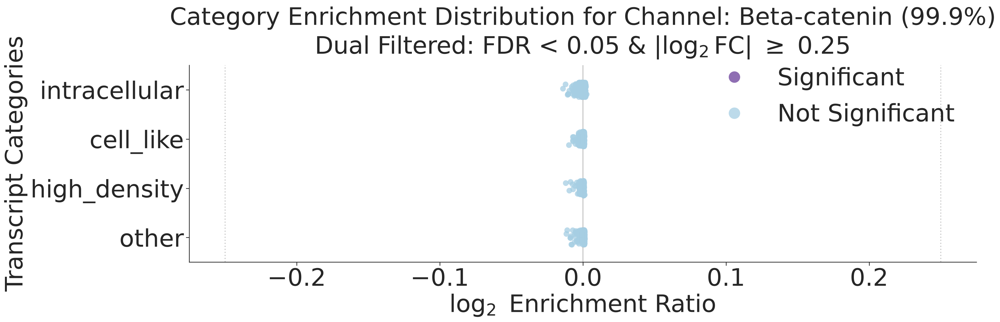

Generating plot for: CD31
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD31.pdf


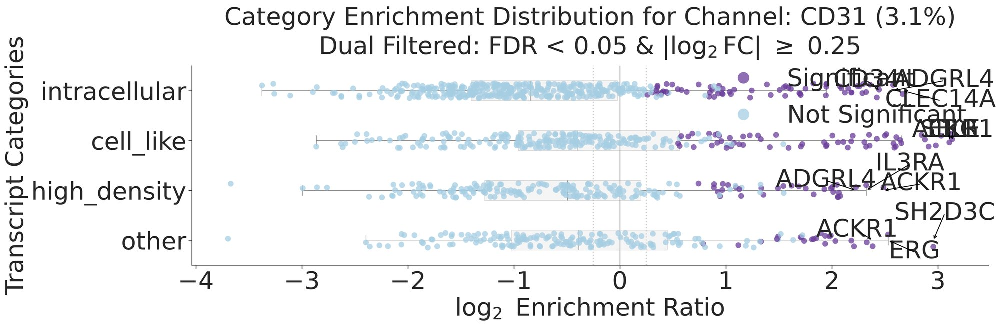

Generating plot for: PTEN
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_PTEN.pdf


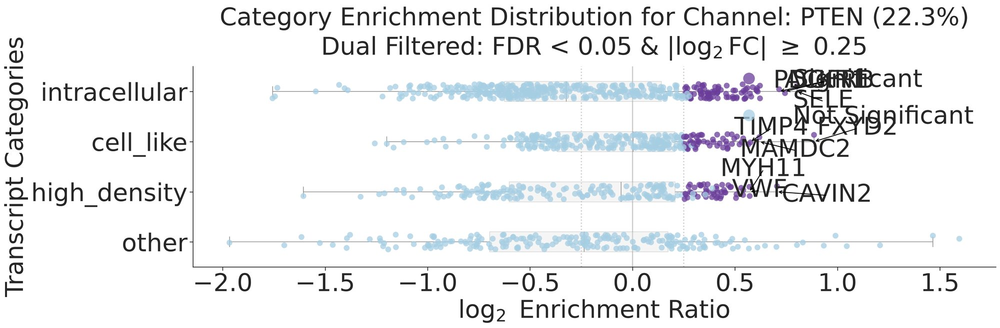

Generating plot for: PanCK
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_PanCK.pdf


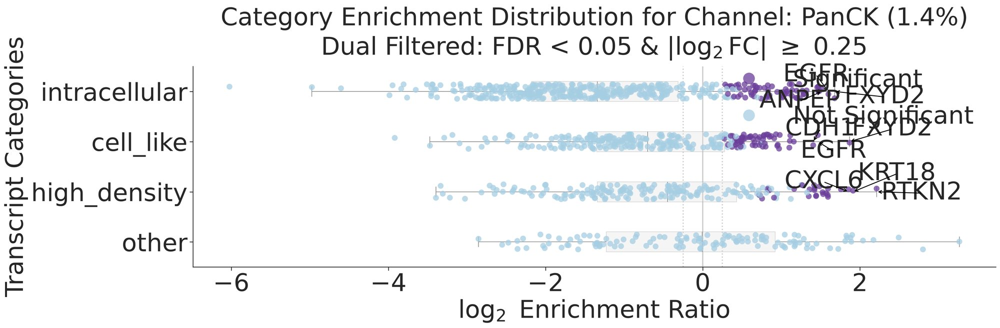

Generating plot for: Vimentin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_Vimentin.pdf


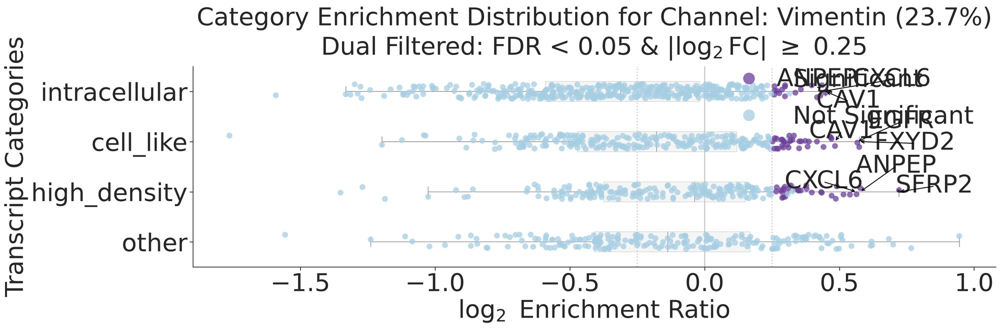

Generating plot for: alphaSMA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_alphaSMA.pdf


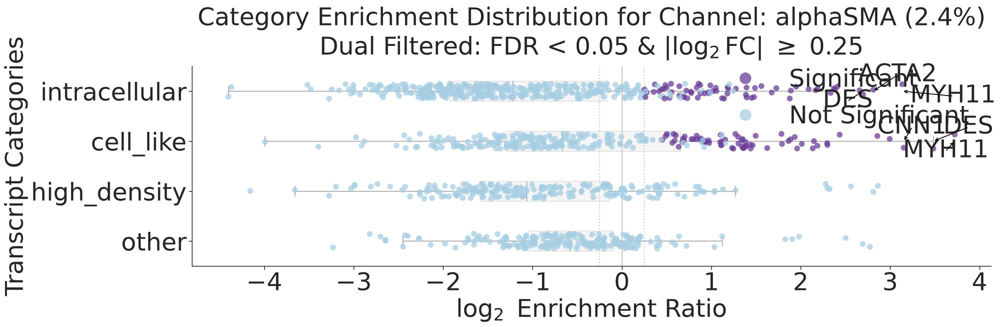

Generating plot for: CD45
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_CD45.pdf


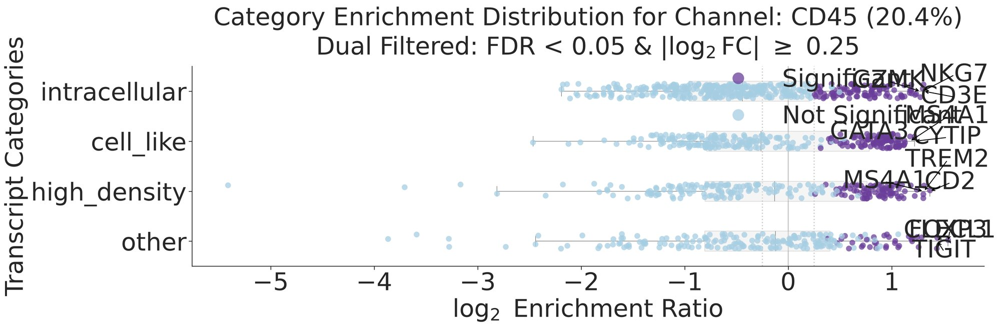

Generating plot for: E-Cadherin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Categories_1D_Enrichment_Channel_E-Cadherin.pdf


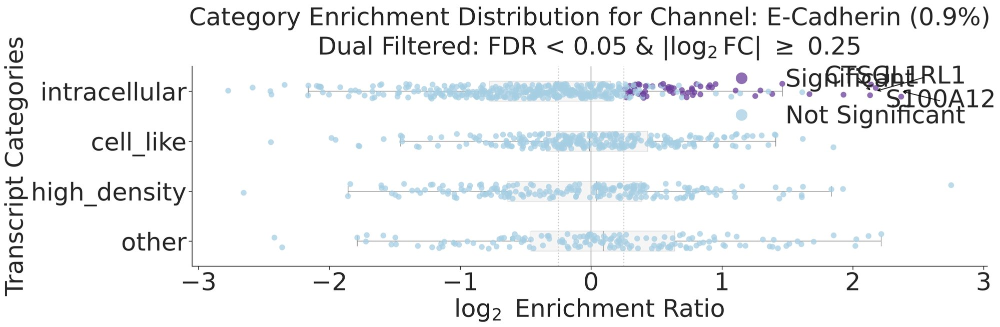

In [63]:
# Batch generate plots for every unique channel
unique_channels = df_gene_category_enrichment["channel"].unique()

for channel in unique_channels:
    print(f"Generating plot for: {channel}")
    plot_single_channel_logfc_by_all_categories(
        df_gene_category_enrichment=df_gene_category_enrichment,
        target_channel=channel,
        df_summary=df_summary,
        saving_path=saving_path,
    )

In [85]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_top_genes_heatmap_grouped_order(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str = None,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_genes: int = 5,
    saving_path: str = None,
):
    """Generates a compact heatmap of top N enriched genes per category without

    dendrogram ribbons.

    Includes the target staining/channel name in the title. Genes are strictly
    ordered on the Y-axis to match the left-to-right X-axis category order.
    """
    # Base font configuration
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    mpl.rcParams.update({"font.size": 10})

    df = df_gene_category_enrichment.copy()

    # 1. Filter for target channel if specified
    if target_channel is not None and "channel" in df.columns:
        df = df[df["channel"] == target_channel].copy()
        if df.empty:
            print(f"No data found for channel: '{target_channel}'")
            return

    # 2. Calculate logFC
    df["logFC"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))

    # 3. Dual-Gating Significance Filter
    df["is_significant"] = (df["pvalue_adj"] < alpha) & (
        df["logFC"].abs() >= logfc_thr
    )

    # 4. Preserve Category Order & Collect Ordered Top Genes
    categories_order = list(df["category"].unique())

    ordered_rows = []
    top_records = []

    for cat in categories_order:
        group = df[df["category"] == cat]
        if group.empty:
            continue

        # Get top N genes for this category sorted descending by logFC
        top_in_cat = group.nlargest(top_n_genes, "logFC")

        for _, row in top_in_cat.iterrows():
            gene_name = row["gene"]

            # Create a unique row identifier to allow repeating genes across categories
            row_id = f"{gene_name} ({cat})"
            ordered_rows.append(row_id)

            # Store records mapping back to gene and target category
            top_records.append(
                {
                    "row_id": row_id,
                    "gene": gene_name,
                    "source_category": cat,
                }
            )

    if not top_records:
        print("No genes found matching criteria.")
        return

    df_top_keys = pd.DataFrame(top_records)

    # Merge full logFC values for all top selected genes across all categories
    merged_data = []
    for _, key_row in df_top_keys.iterrows():
        r_id = key_row["row_id"]
        g_name = key_row["gene"]

        # Fetch values across all categories for this gene
        gene_all_cats = df[df["gene"] == g_name]
        for _, match in gene_all_cats.iterrows():
            merged_data.append(
                {
                    "row_id": r_id,
                    "display_gene": g_name,
                    "category": match["category"],
                    "logFC": match["logFC"],
                    "is_significant": match["is_significant"],
                }
            )

    df_heatmap = pd.DataFrame(merged_data)

    # 5. Pivot Data for Heatmap and Significance Annotations
    heatmap_matrix = df_heatmap.pivot_table(
        index="row_id", columns="category", values="logFC", aggfunc="mean"
    )

    sig_matrix = df_heatmap.pivot_table(
        index="row_id",
        columns="category",
        values="is_significant",
        aggfunc="any",
    ).fillna(False)

    # Reindex columns to match explicit category order and rows to match top selection order
    heatmap_matrix = heatmap_matrix.reindex(
        index=ordered_rows, columns=categories_order
    )
    sig_matrix = sig_matrix.reindex(
        index=ordered_rows, columns=categories_order
    ).fillna(False)

    # Generate gene labels for the y-axis (displaying original gene names)
    gene_display_labels = [
        df_heatmap[df_heatmap["row_id"] == r_id]["display_gene"].iloc[0]
        for r_id in ordered_rows
    ]

    # Create significance annotation matrix (* for significant cells)
    annot_matrix = np.where(sig_matrix, "*", "")

    # 6. Compact Figure Setup
    sns.set_theme(style="ticks")

    n_rows = len(ordered_rows)
    n_cols = len(categories_order)

    # Scaled down figure size for compact display
    fig_width = max(4, n_cols * 0.1 + 0.5)
    fig_height = max(2, n_rows * 0.2 + 1.0)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Colorbar range centered at 0
    vmax = max(
        abs(heatmap_matrix.min().min()), abs(heatmap_matrix.max().max())
    )
    vmin = -vmax

    sns.heatmap(
        heatmap_matrix,
        annot=annot_matrix,
        fmt="",
        cmap="RdBu_r",
        center=0,
        vmin=vmin,
        vmax=vmax,
        linewidths=0,
        linecolor="#e0e0e0",
        cbar_kws={"label": "$\log_2$ Enrichment Ratio", "shrink": 0.8},
        annot_kws={"size": 10, "fontweight": "normal", "color": "black"},
        ax=ax,
    )

    # 7. Formatting & Polish
    ax.set_yticklabels(
        gene_display_labels, rotation=0, fontsize=9, fontweight="normal"
    )
    ax.set_xticklabels(
        categories_order, rotation=45, ha="right", fontsize=9, fontweight="normal"
    )

    title_channel_str = (
        f"Staining: {target_channel}\n" if target_channel else ""
    )
    ax.set_title(
        f"{title_channel_str}Top {top_n_genes} Enriched Genes per Category (Group Ordered)\n(* FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr})",
        fontsize=11,
        fontweight="normal",
        pad=12,
    )
    ax.set_xlabel("Transcript Categories", fontsize=10, fontweight="normal")
    ax.set_ylabel("Top Enriched Genes", fontsize=10, fontweight="normal")

    plt.tight_layout()

    # 8. Exporting File
    if saving_path is not None:
        clean_ch = (
            f"_{target_channel.replace('/', '_').replace(' ', '_')}"
            if target_channel
            else ""
        )
        filename = f"Heatmap_Top{top_n_genes}_Genes{clean_ch}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

Generating heatmap for staining: DAPI
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_DAPI.pdf


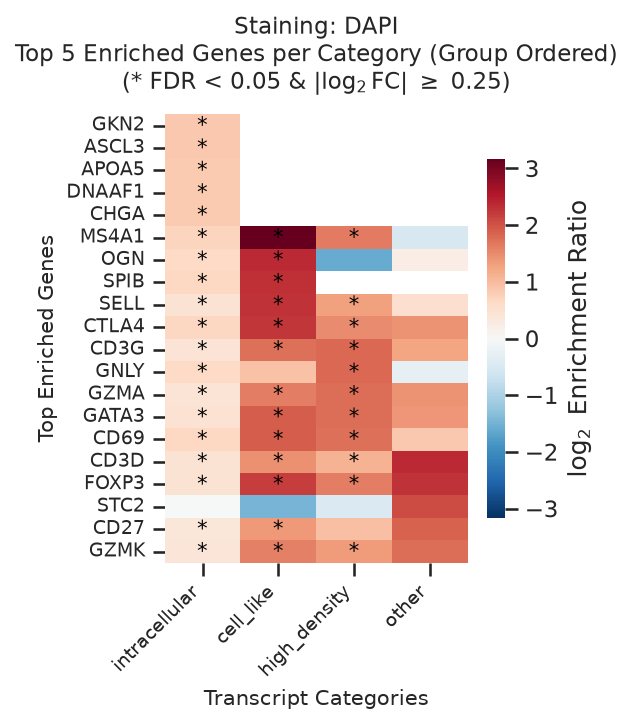

Generating heatmap for staining: ATP1A1/CD45/E-Cadherin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_ATP1A1_CD45_E-Cadherin.pdf


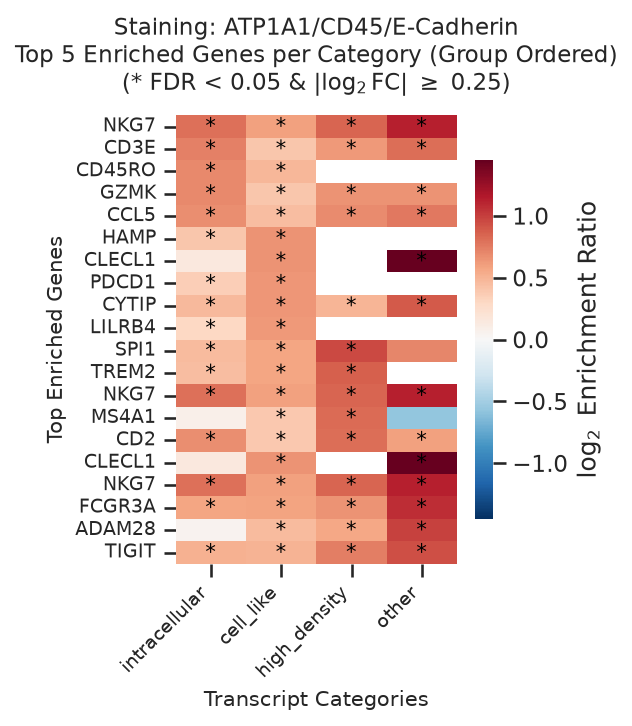

Generating heatmap for staining: 18S
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_18S.pdf


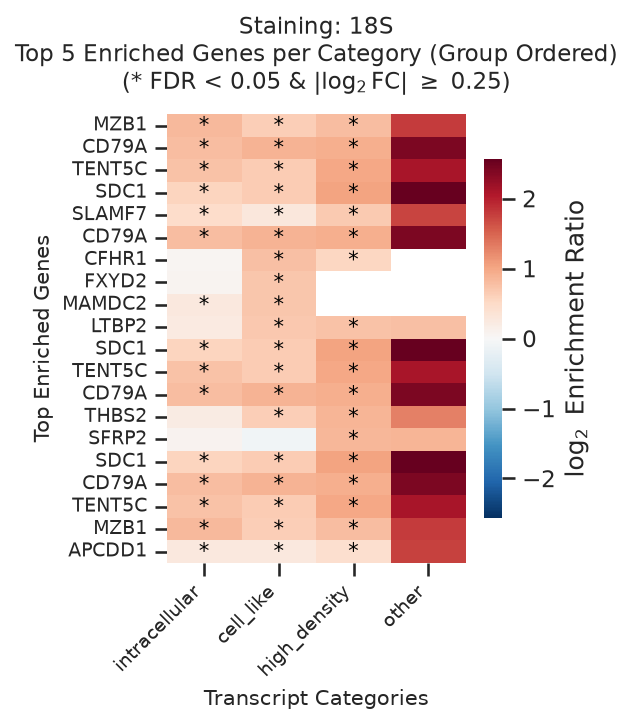

Generating heatmap for staining: alphaSMA/Vimentin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_alphaSMA_Vimentin.pdf


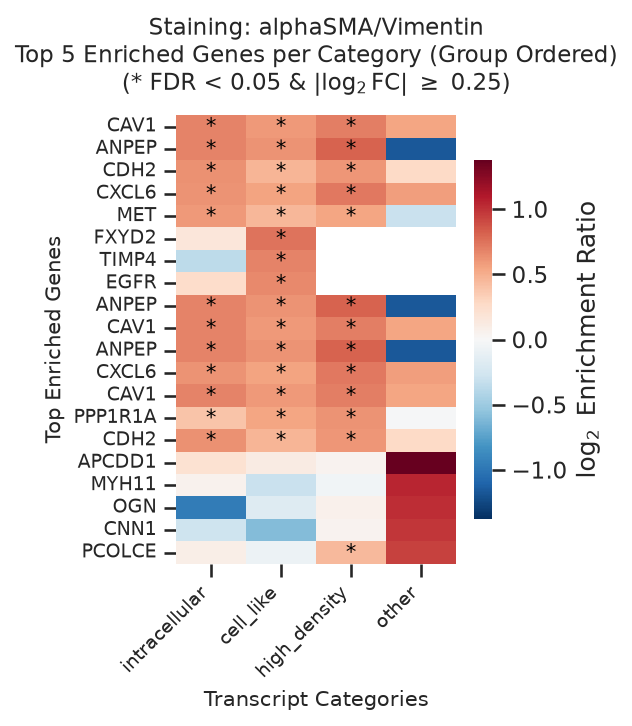

Generating heatmap for staining: Blue background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Blue_background.pdf


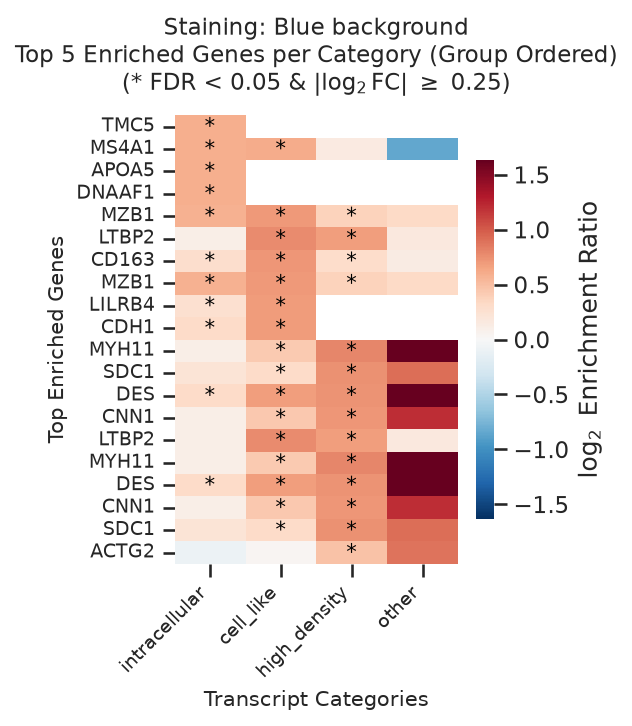

Generating heatmap for staining: Green background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Green_background.pdf


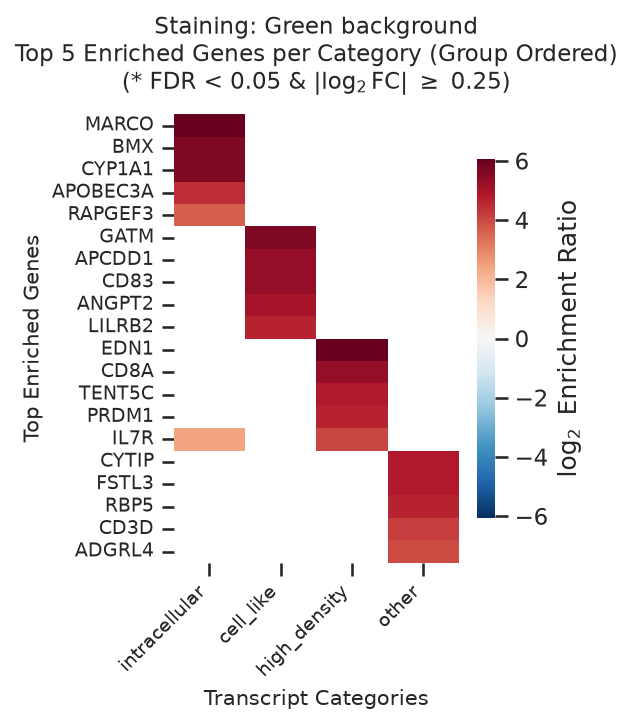

Generating heatmap for staining: Yellow background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Yellow_background.pdf


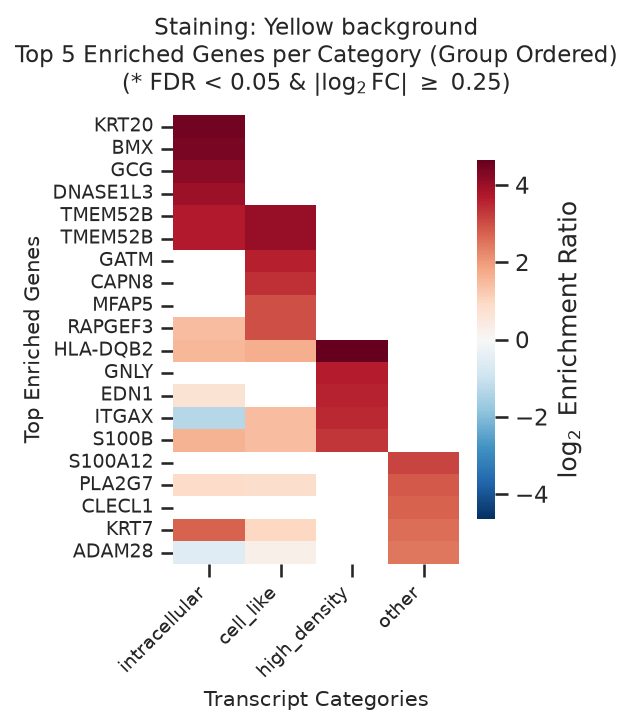

Generating heatmap for staining: Red background
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Red_background.pdf


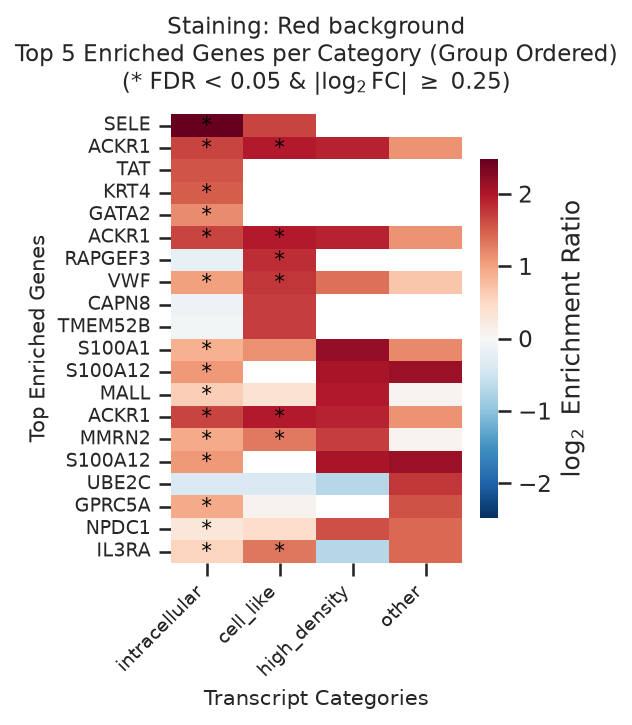

Generating heatmap for staining: CD4
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD4.pdf


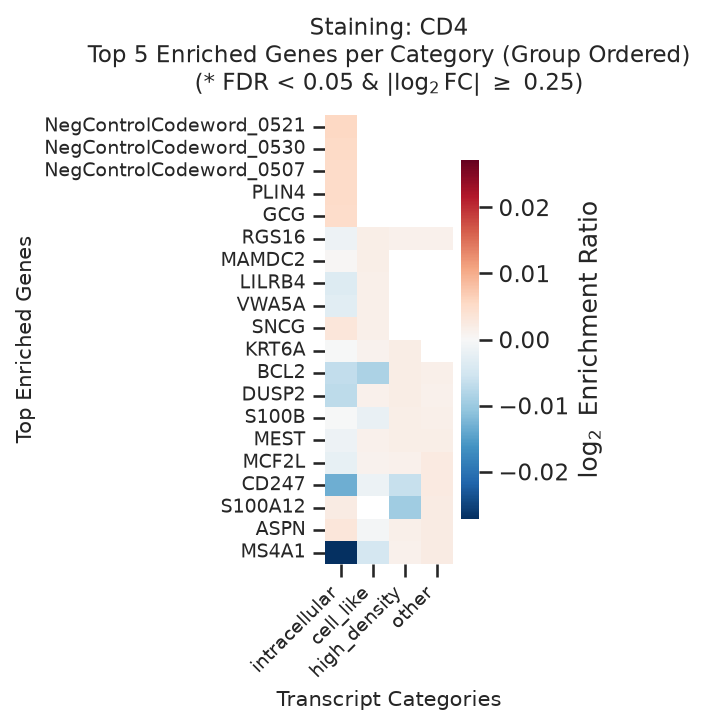

Generating heatmap for staining: CD20
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD20.pdf


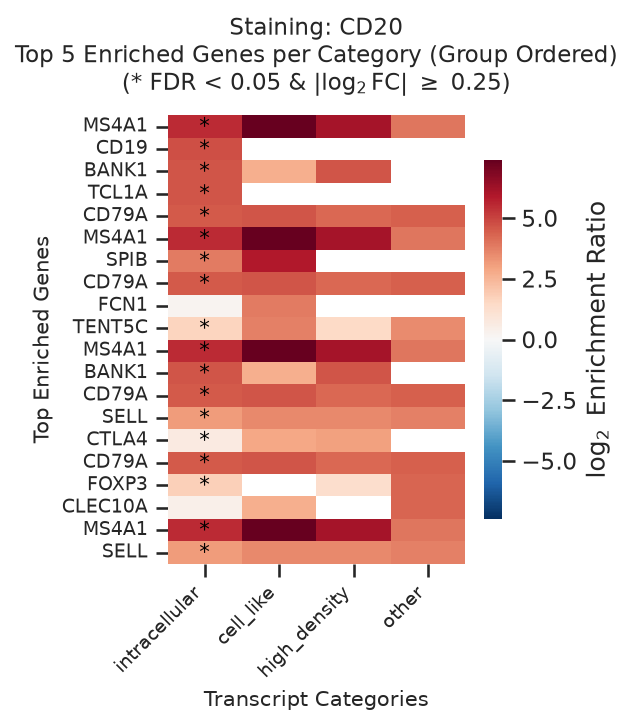

Generating heatmap for staining: CD8A
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD8A.pdf


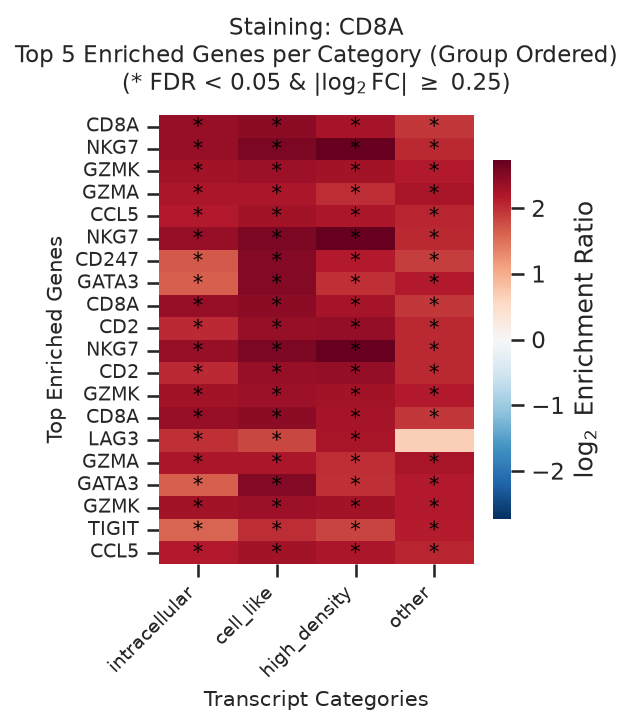

Generating heatmap for staining: CD3E
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD3E.pdf


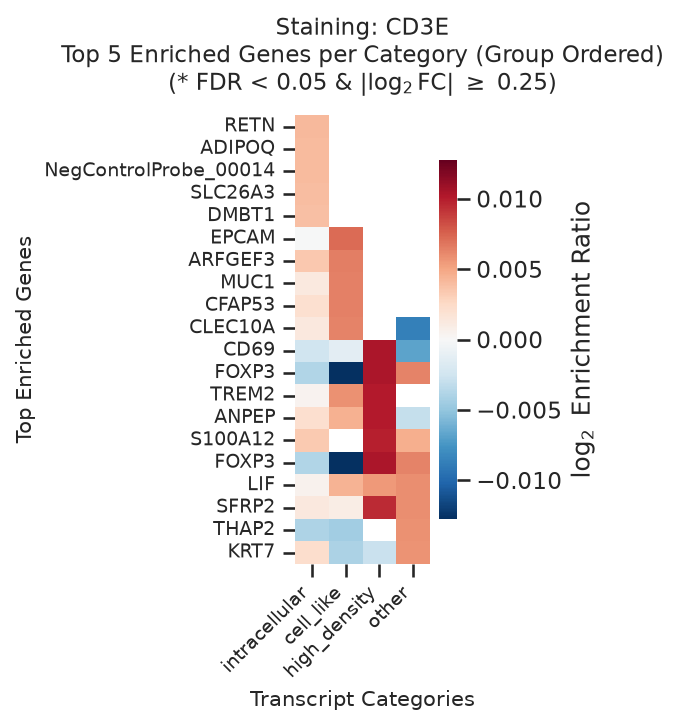

Generating heatmap for staining: CD138
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD138.pdf


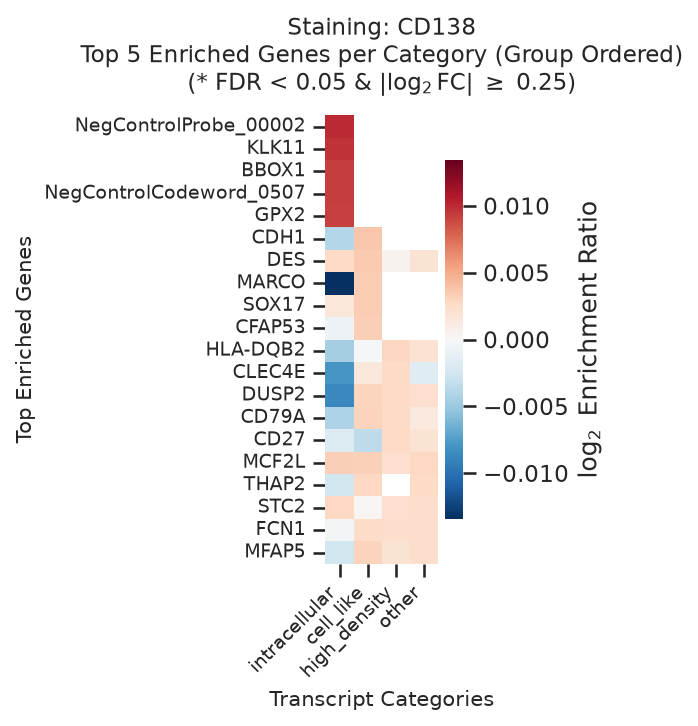

Generating heatmap for staining: HLA-DR
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_HLA-DR.pdf


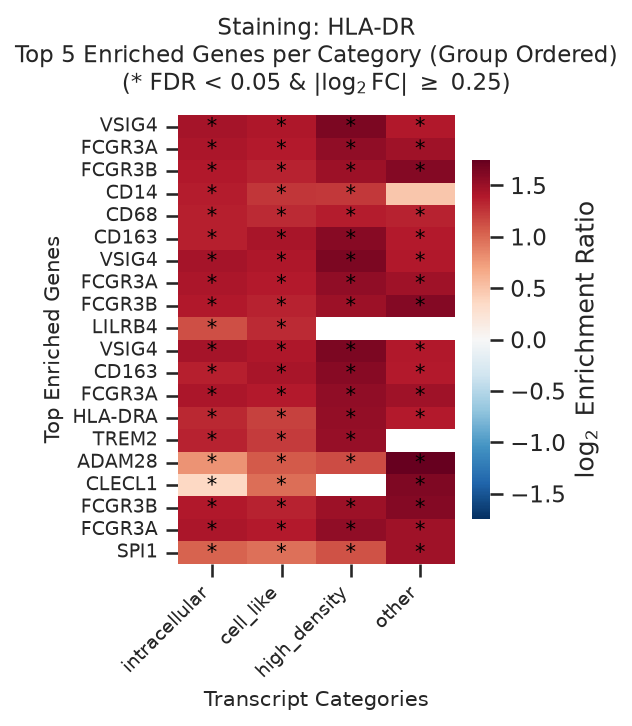

Generating heatmap for staining: CD11c
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD11c.pdf


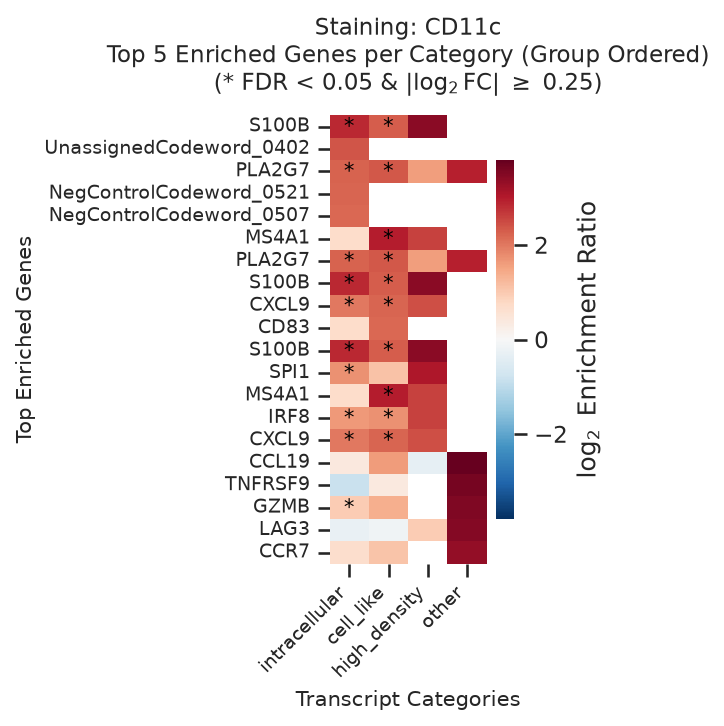

Generating heatmap for staining: CD68
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD68.pdf


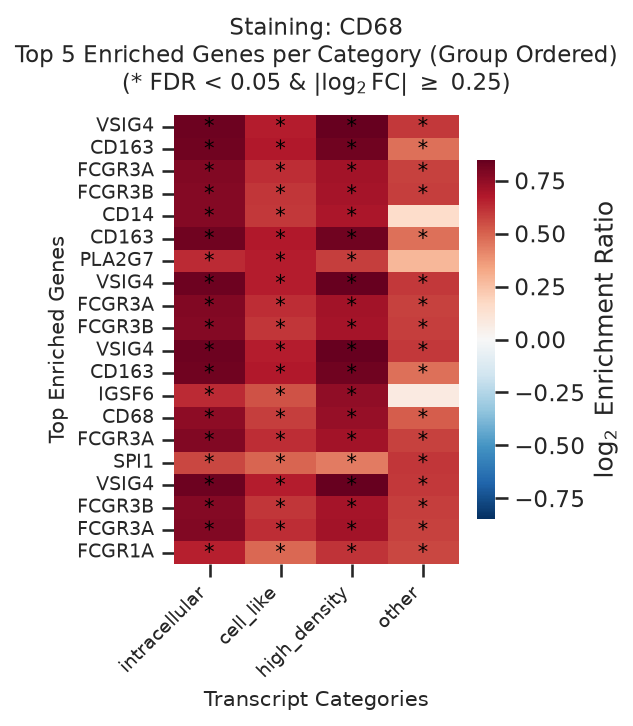

Generating heatmap for staining: CD16
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD16.pdf


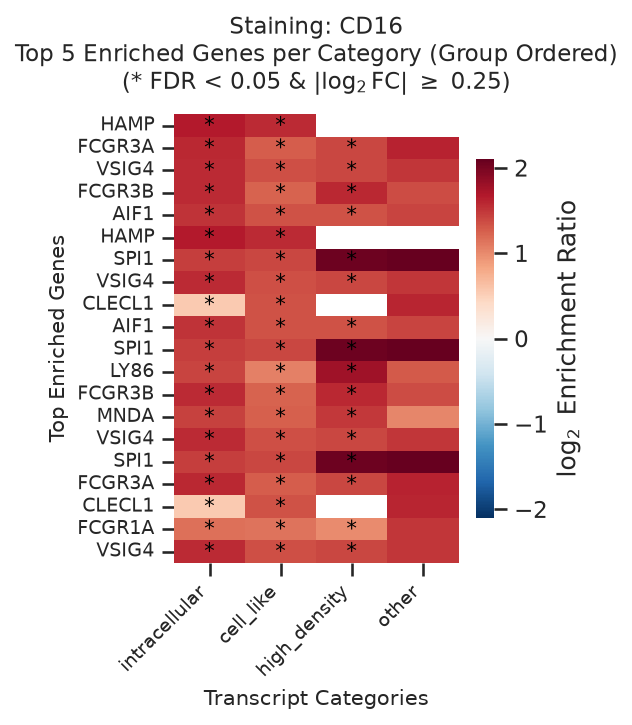

Generating heatmap for staining: GranzymeB
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_GranzymeB.pdf


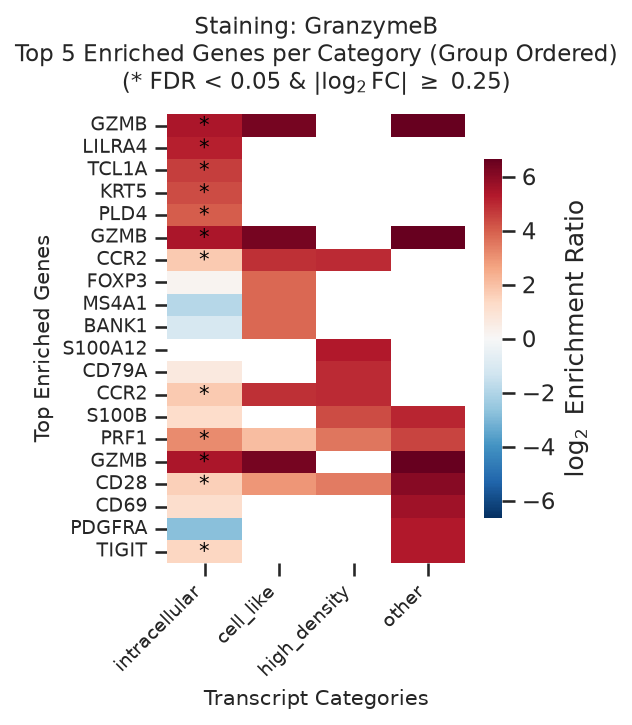

Generating heatmap for staining: CD163
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD163.pdf


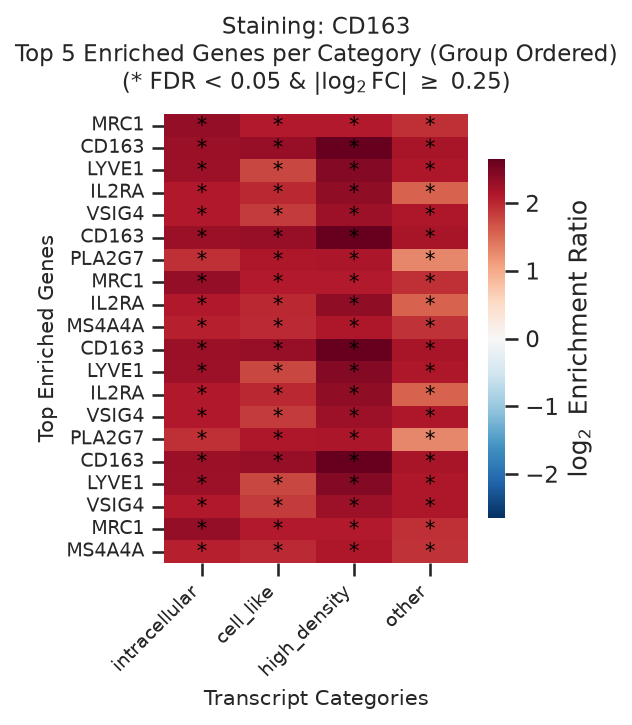

Generating heatmap for staining: PD-1
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_PD-1.pdf


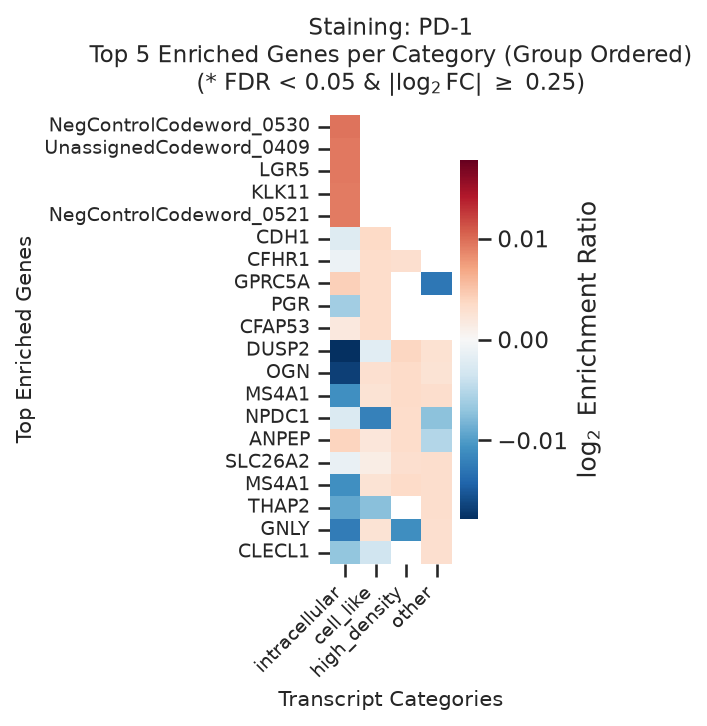

Generating heatmap for staining: VISTA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_VISTA.pdf


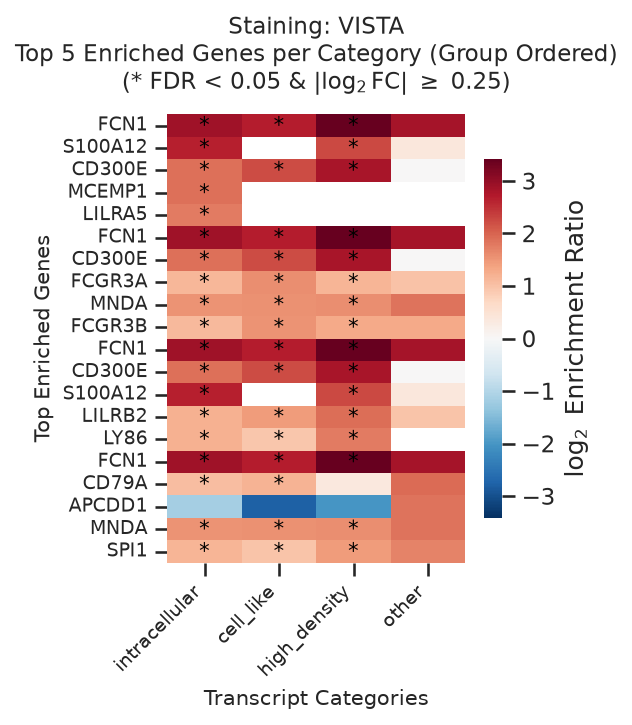

Generating heatmap for staining: PD-L1
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_PD-L1.pdf


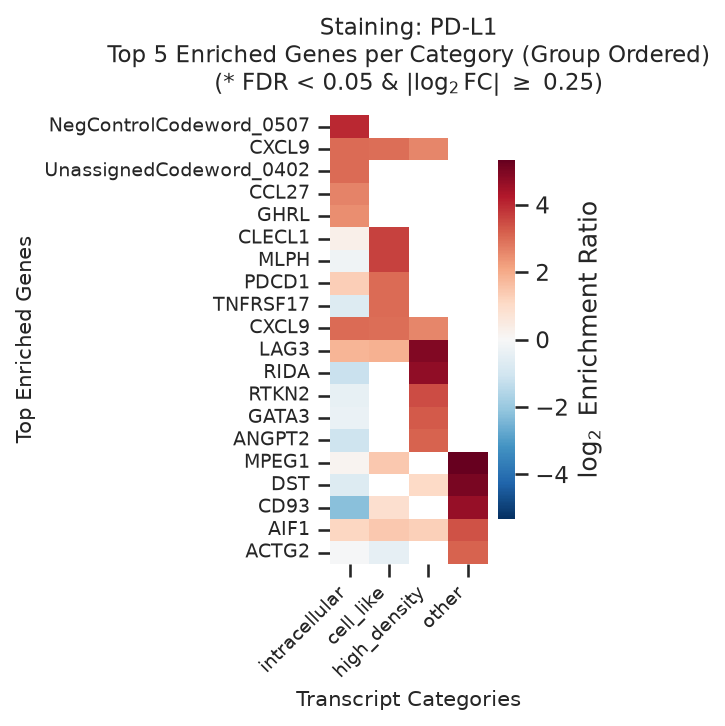

Generating heatmap for staining: LAG-3
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_LAG-3.pdf


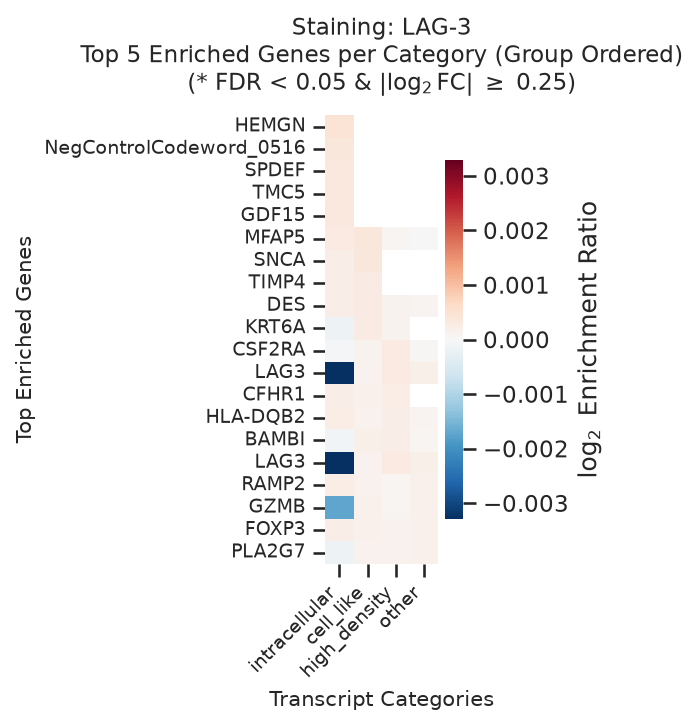

Generating heatmap for staining: CD45RA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD45RA.pdf


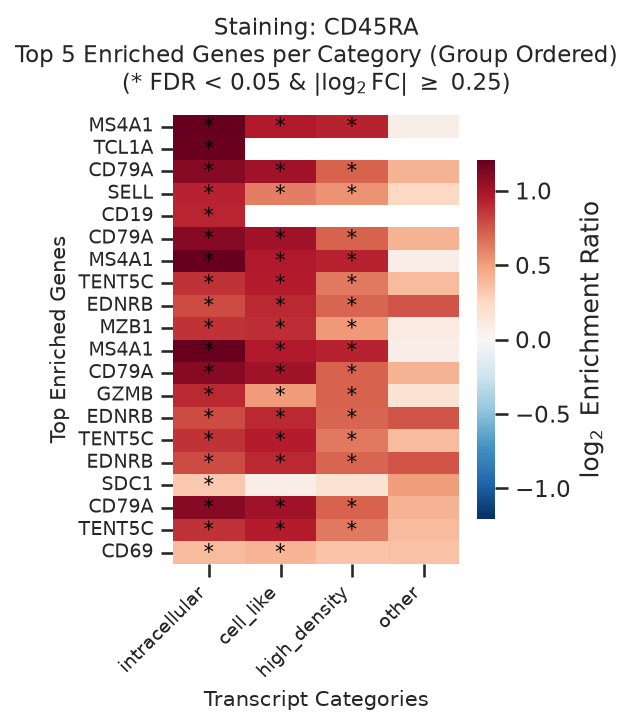

Generating heatmap for staining: PCNA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_PCNA.pdf


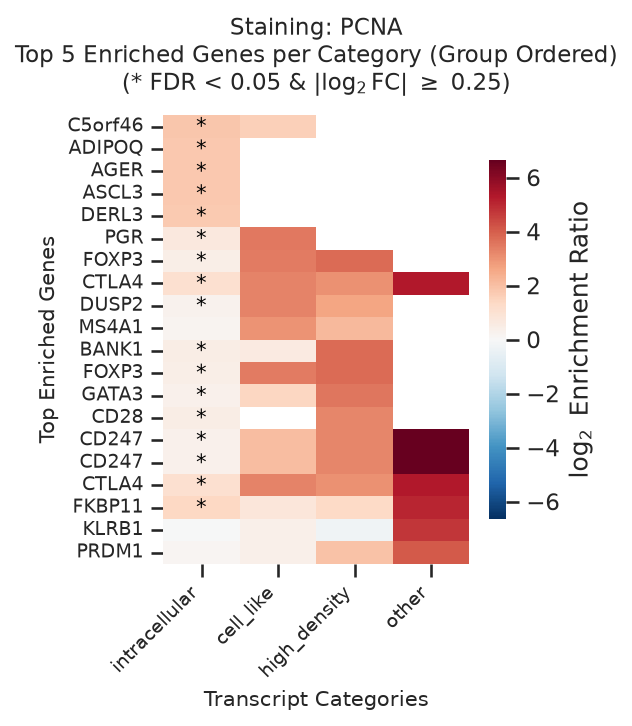

Generating heatmap for staining: CD45RO
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD45RO.pdf


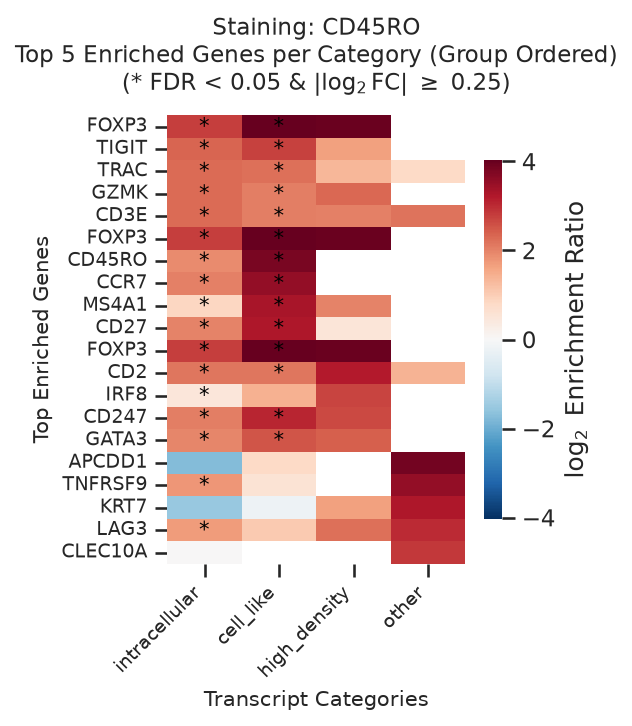

Generating heatmap for staining: Ki-67
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Ki-67.pdf


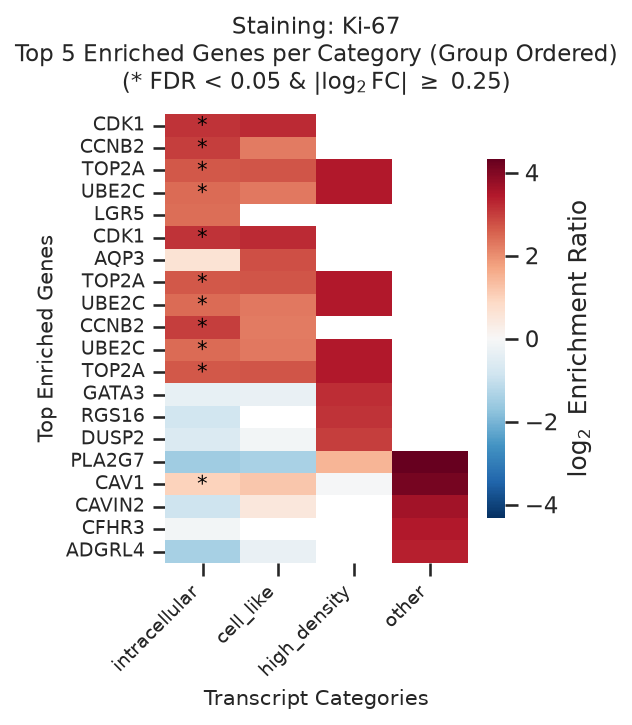

Generating heatmap for staining: Beta-catenin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Beta-catenin.pdf


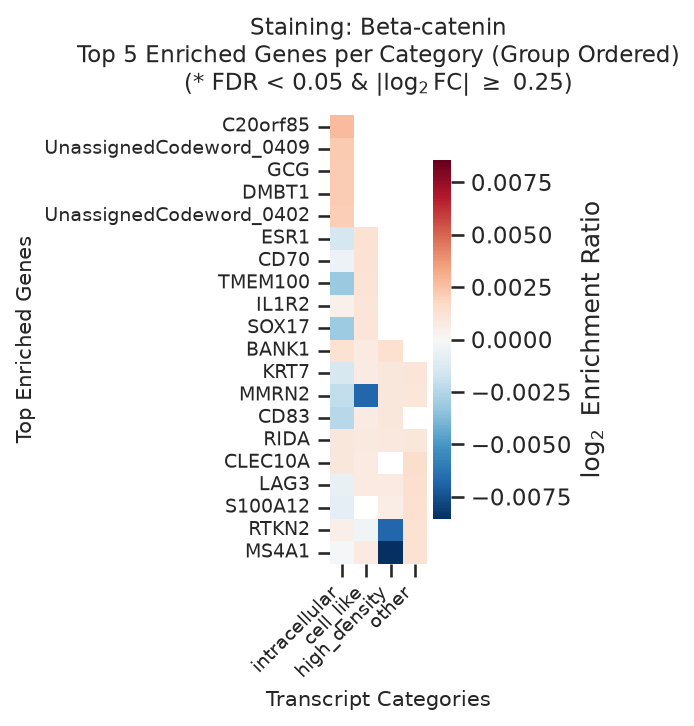

Generating heatmap for staining: CD31
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD31.pdf


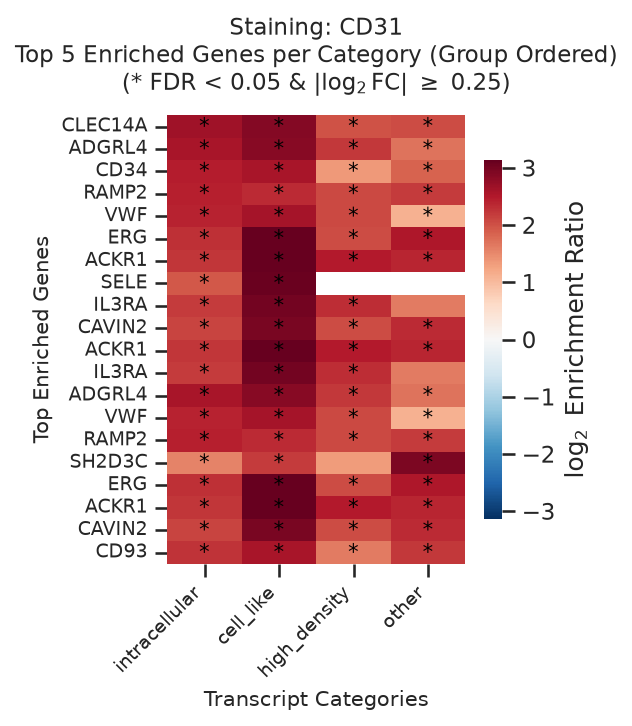

Generating heatmap for staining: PTEN
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_PTEN.pdf


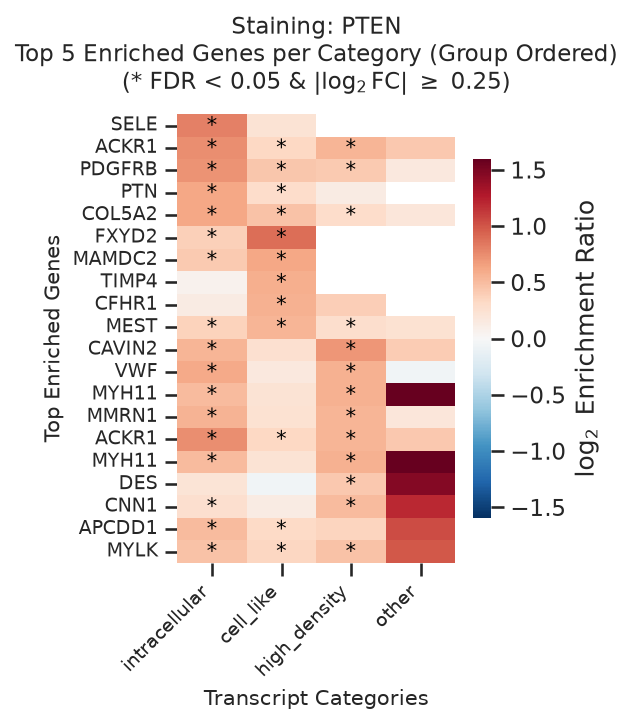

Generating heatmap for staining: PanCK
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_PanCK.pdf


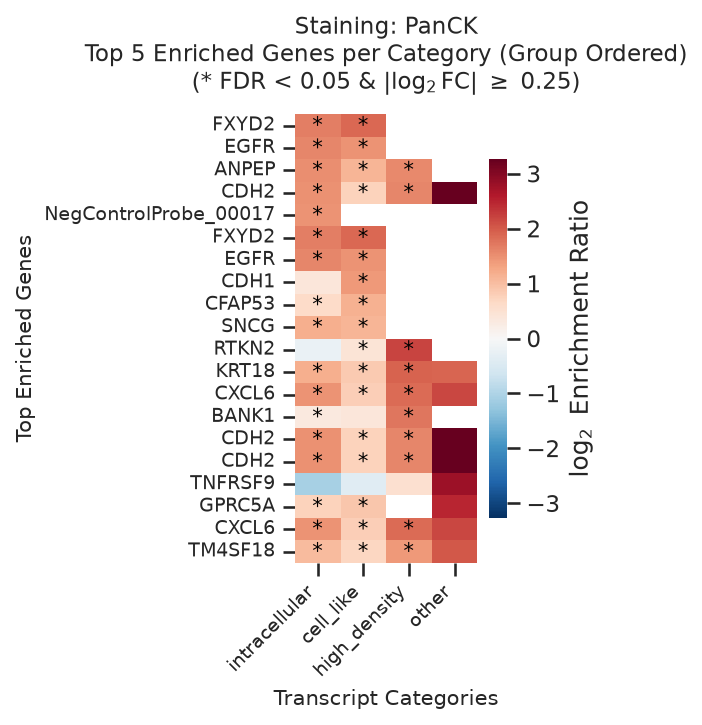

Generating heatmap for staining: Vimentin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_Vimentin.pdf


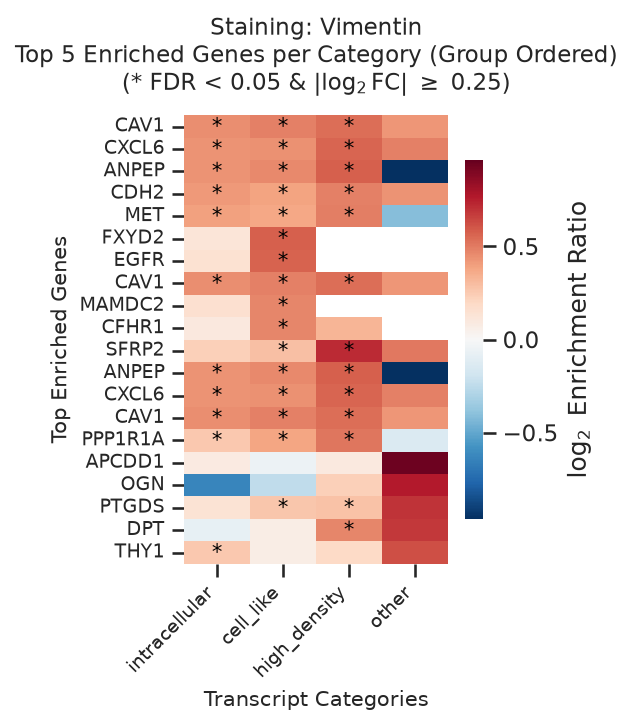

Generating heatmap for staining: alphaSMA
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_alphaSMA.pdf


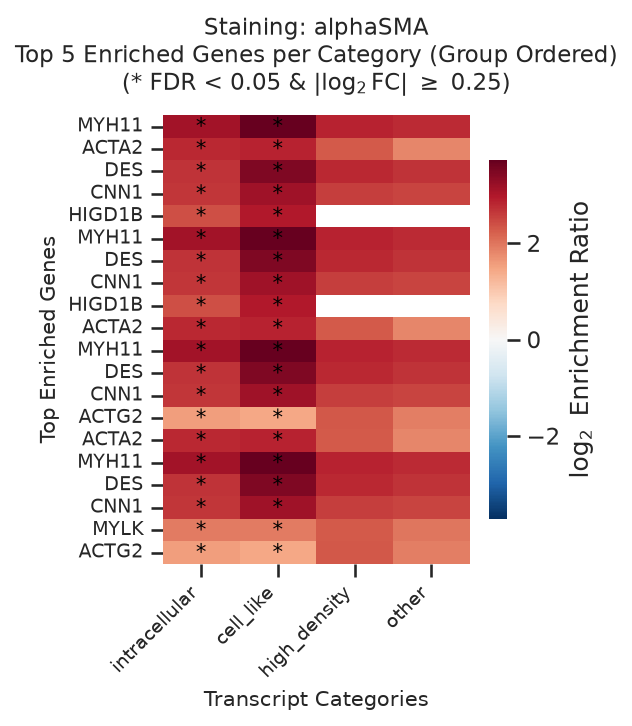

Generating heatmap for staining: CD45
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_CD45.pdf


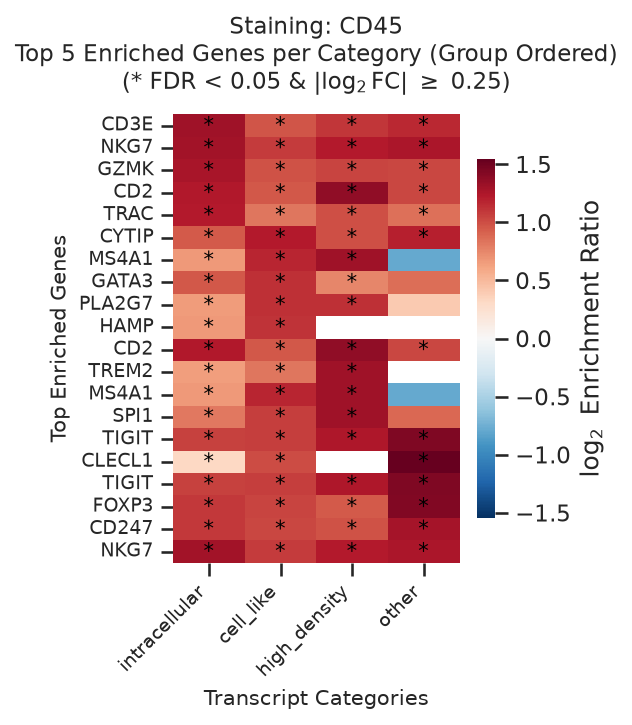

Generating heatmap for staining: E-Cadherin
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_rcc/Heatmap_Top5_Genes_E-Cadherin.pdf


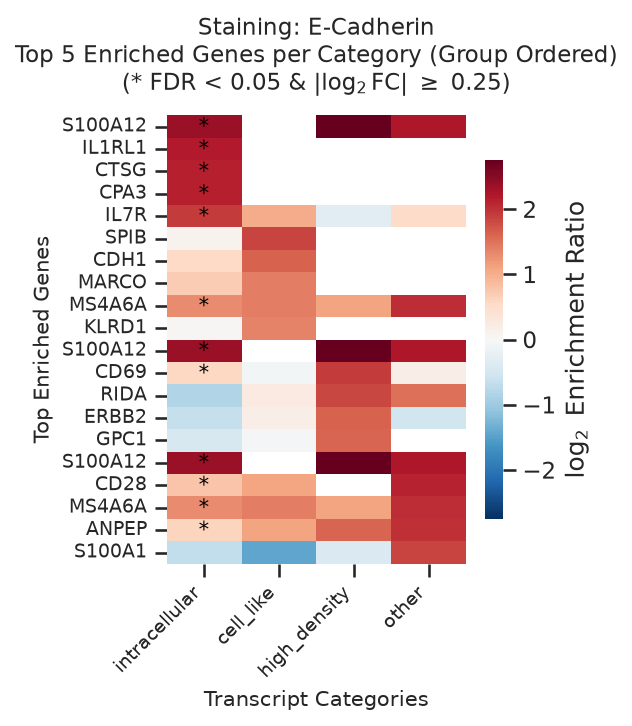

In [86]:
unique_channels = df_gene_category_enrichment["channel"].unique()

for channel in unique_channels:
    print(f"Generating heatmap for staining: {channel}")
    plot_top_genes_heatmap_grouped_order(
        df_gene_category_enrichment=df_gene_category_enrichment,
        target_channel=channel,
        top_n_genes=5,
        saving_path=saving_path,
    )

# Other analysis

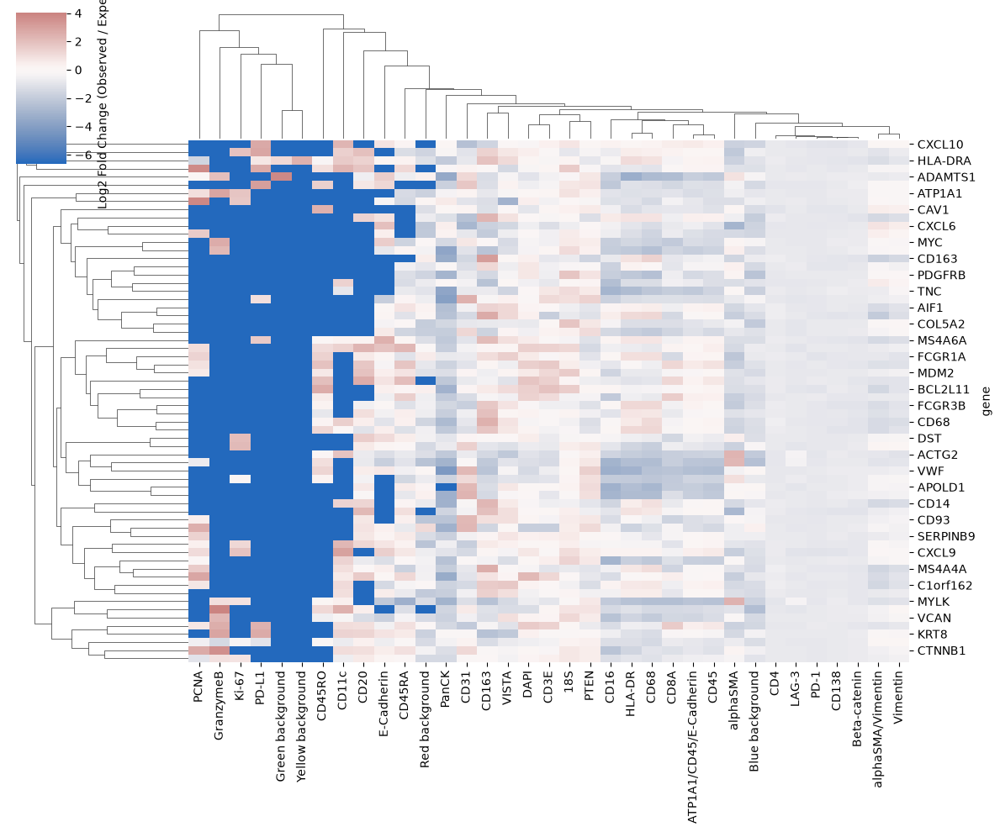

In [34]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Isolate and clean the spatial baseline from df_spatial_summary
spatial_baseline = df_spatial_summary.set_index("Channel Name")["% Positive Pixels (True Extracellular)"]
# Convert from percentage space (0-100) to fraction space (0-1)
spatial_baseline = spatial_baseline / 100.0

# 2. Convert df_v_extra into relative proportions (proportions sum to 1 across columns per row)
# This controls for total transcript count variances per spot/cell
df_v_prop = df_v_extra.div(df_v_extra.sum(axis=1), axis=0)

# 3. Find the intersecting channels present in BOTH dataframes to prevent NaN mismatches
common_channels = df_v_prop.columns.intersection(spatial_baseline.index)

if len(common_channels) == 0:
    raise ValueError(
        "No matching channels found between df_v_extra columns and df_spatial_summary 'Channel Name'.\n"
        f"df_v_extra columns: {list(df_v_prop.columns)}\n"
        f"df_spatial_summary channels: {list(spatial_baseline.index)}"
    )

# Filter and align both datasets to have the exact same columns in the exact same order
df_v_aligned = df_v_prop[common_channels]
baseline_aligned = spatial_baseline.reindex(common_channels)

# 4. Compute the Observed / Expected ratio
ratio_df = df_v_aligned.div(baseline_aligned, axis=1)

# 5. Add a small pseudocount to handle zero-count drops, then compute Log2 Fold Change
pseudocount = 0.01
df_l2fc = np.log2(ratio_df + pseudocount)

# 6. Generate the Clustermap
g = sns.clustermap(
    df_l2fc,
    cmap="vlag",          # Blue (depleted) to Red (enriched) diverging scheme
    center=0,             # 0 equals background baseline expectations
    cbar_kws={'label': 'Log2 Fold Change (Observed / Expected)'},
    figsize=(12, 10)
)

plt.show()

array([[2, 3, 5, ..., 3, 3, 4],
       [3, 4, 5, ..., 3, 3, 3],
       [4, 5, 5, ..., 3, 3, 3],
       ...,
       [2, 3, 4, ..., 2, 2, 3],
       [3, 4, 4, ..., 1, 1, 3],
       [3, 3, 2, ..., 1, 1, 3]], dtype=uint16)

Notes (pseudo-code, not run):

```
roi=(0,100,0,100) #xmin, xmax, ymin,ymax
c='DAPI'
in sdata['morphology_focus'].scale0.c find the index of my channel c
np.array(sdata['morphology_focus'].scale0.image[5,100:200,0:200]) # 5 is channel position, the others are roi
g=[list of selected genes']
trans=sdata['transcripts'].compute() # for gene g only
trans['x_plot']=trans['x']-trans['x'].min()
trans['y_plot']=trans['y']-trans['y'].min()
# then filter ori
sdata['cell_boundaries'] # find miminmal of x and y and also substract
# then filter for roi only
plt.scatter of spatial points colored by whatever I nidicate 
plt.scatter of spatial points
```

In [89]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from shapely.geometry import box
from shapely.affinity import translate, scale
import spatialdata as sd
import os

def plot_scaled_image_roi(
    sdata: sd.SpatialData,
    roi: tuple[float, float, float, float],  # (xmin, xmax, ymin, ymax) in POINT/SHAPE space
    scale_factor: float = 0.2125,            # point_space / image_space ratio
    channel: str = "DAPI",
    gene_list: list[str] | None = None,
    color_key: str = "gene",
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    shapes_key: str = "cell_boundaries",
    points_key: str = "transcripts",
    figsize: tuple[float, float] = (8, 8),
    bg_colormap: str = "gray",
    scatter_size: float = 15.0,
    binarization_threshold: float | None = None,  # Directly pass numerical threshold value
    boundary_edgecolor: str = "white",             # Customize cell boundary stroke color
    boundary_linewidth: float = 1.0,              # Customize cell boundary thickness
    points_cmap: str | None = None,               # Dynamic colormap name for points (e.g. "magma", "Set1")
    saving_path: str | None = None,               # Optional file target destination path
) -> tuple[plt.Figure, plt.Axes]:
    """Plots a local coordinate ROI, preserving image quality by upscaling 
    transcripts and shapes to match the high-resolution image crop space.
    """
    xmin, xmax, ymin, ymax = roi
    
    # Calculate high-res native image crop pixel bounds first
    img_xmin = int(np.floor(xmin / scale_factor))
    img_xmax = int(np.ceil(xmax / scale_factor))
    img_ymin = int(np.floor(ymin / scale_factor))
    img_ymax = int(np.ceil(ymax / scale_factor))
    
    # -------------------------------------------------------------------------
    # 1. LOAD & UPSCALE TRANSCRIPTS
    # -------------------------------------------------------------------------
    points_lazy = sdata.points[points_key]
    
    if gene_list is not None:
        gene_col = "gene" if "gene" in points_lazy.columns else "feature_name"
        points_lazy = points_lazy[points_lazy[gene_col].isin(gene_list)]
        
    transcripts = points_lazy.compute()
    
    # Global spatial offset to orient points to relative (0,0) point space
    global_xmin = transcripts["x"].min()
    global_ymin = transcripts["y"].min()
    
    # Align raw transcripts to shared point base space
    transcripts["x_scaled"] = transcripts["x"] - global_xmin
    transcripts["y_scaled"] = transcripts["y"] - global_ymin
    
    # Filter for transcripts landing inside the point-space ROI window
    trans_mask = (
        (transcripts["x_scaled"] >= xmin) & (transcripts["x_scaled"] <= xmax) & 
        (transcripts["y_scaled"] >= ymin) & (transcripts["y_scaled"] <= ymax)
    )
    trans_roi = transcripts[trans_mask].copy()
    
    # UPSCALE STEPS: Convert local point adjustments into native image pixel space coords
    trans_roi["x_plot"] = (trans_roi["x_scaled"] / scale_factor) - img_xmin
    trans_roi["y_plot"] = (trans_roi["y_scaled"] / scale_factor) - img_ymin

    # -------------------------------------------------------------------------
    # 2. SHIFT & UPSCALE CELL BOUNDARIES
    # -------------------------------------------------------------------------
    shapes_poly = sdata[shapes_key].copy()
    
    # Shift raw structures down into relative point base space
    shapes_poly["geometry"] = shapes_poly["geometry"].apply(
        lambda g: translate(g, xoff=-global_xmin, yoff=-global_ymin)
    )
    
    # Filter geometries hitting our point-space ROI box
    roi_box = box(xmin, ymin, xmax, ymax)
    shapes_roi = shapes_poly[shapes_poly.geometry.intersects(roi_box)].copy()
    
    # UPSCALE STEPS: Scale shapes out to native resolution, then shift by high-res image index offsets
    shapes_roi["geometry"] = shapes_roi["geometry"].apply(
        lambda g: translate(
            scale(g, xfact=1.0/scale_factor, yfact=1.0/scale_factor, origin=(0, 0)),
            xoff=-img_xmin, 
            yoff=-img_ymin
        )
    )
    gdf_roi = gpd.GeoDataFrame(shapes_roi, geometry="geometry")

    # -------------------------------------------------------------------------
    # 3. EXTRACT NATIVE HIGH-RES IMAGE CROP
    # -------------------------------------------------------------------------
    img_node = sdata.images[image_key][scale_key]
    img_element = img_node.image if hasattr(img_node, "image") else img_node
    
    if "c" in img_element.coords:
        channel_names = [str(ch) for ch in img_element.coords["c"].values]
        if channel in channel_names:
            ch_idx = channel_names.index(channel)
        else:
            raise ValueError(f"Channel '{channel}' not found. Options: {channel_names}")
    else:
        ch_idx = 0
    
    # Bound-check safety guards against the raw array boundaries
    img_h, img_w = img_element.shape[-2], img_element.shape[-1]
    img_xmin = max(0, min(img_w, img_xmin))
    img_xmax = max(0, min(img_w, img_xmax))
    img_ymin = max(0, min(img_h, img_ymin))
    img_ymax = max(0, min(img_h, img_ymax))

    # Grab the high-res slice cleanly
    img_crop = img_element[ch_idx, img_ymin:img_ymax, img_xmin:img_xmax].compute()
    img_np_highres = np.array(img_crop)
    
    # Apply threshold filtering on full-resolution data
    is_binarized = binarization_threshold is not None
    if is_binarized:
        img_np_highres = (img_np_highres > binarization_threshold).astype(np.float32)

    # -------------------------------------------------------------------------
    # 4. PLOT CANVAS (IN TRUE HIGH-RES IMAGE PLOT SPACE)
    # -------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)
    
    # Extent accurately spans the actual high-res pixel width and height
    plot_width = img_xmax - img_xmin
    plot_height = img_ymax - img_ymin
    
    vmin_val = 0 if is_binarized else None
    vmax_val = 1 if is_binarized else None
    
    ax.imshow(
        img_np_highres, 
        cmap=bg_colormap, 
        origin="lower", 
        extent=[0, plot_width, 0, plot_height], 
        vmin=vmin_val,
        vmax=vmax_val,
        zorder=1
    )
    
    # Render cell boundaries matching pixel-level structures perfectly
    gdf_roi.plot(
        ax=ax, 
        facecolor="none", 
        edgecolor=boundary_edgecolor, 
        linewidth=boundary_linewidth, 
        alpha=0.7, 
        zorder=2
    )
    
    # Render high-resolution localized transcripts 
    if not trans_roi.empty:
        if pd.api.types.is_numeric_dtype(trans_roi[color_key]):
            cmap_choice = points_cmap if points_cmap is not None else "viridis"
            scatter = ax.scatter(
                trans_roi["x_plot"], trans_roi["y_plot"],
                c=trans_roi[color_key], cmap=cmap_choice,
                s=scatter_size, zorder=3, edgecolors="none"
            )
            plt.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
        else:
            # Categorical strings filtered tightly down to local ROI categories
            trans_roi[color_key] = pd.Categorical(trans_roi[color_key].astype(str))
            cats = trans_roi[color_key].cat.categories
            cmap_choice = points_cmap if points_cmap is not None else "tab20"
            cmap = plt.get_cmap(cmap_choice, len(cats))
            
            ax.scatter(
                trans_roi["x_plot"], trans_roi["y_plot"],
                c=trans_roi[color_key].cat.codes, cmap=cmap,
                s=scatter_size, zorder=3, edgecolors="none"
            )
            for idx, cat in enumerate(cats):
                ax.scatter([], [], color=cmap(idx), label=str(cat), s=30)
            ax.legend(title=color_key, bbox_to_anchor=(1.05, 1), loc="upper left", frameon=False)

    ax.set_xlim(0, plot_width)
    ax.set_ylim(0, plot_height)
    ax.set_aspect("equal")
    ax.axis("off")
    
    title_suffix = f" (Binarized Mask > {binarization_threshold})" if is_binarized else ""
    ax.set_title(f"High-Res ROI Alignment | Channel: {channel}{title_suffix}", fontsize=12, fontweight="bold")
    
    plt.tight_layout()
    
    # --- SAVE OPTION ---
    if saving_path is not None:
        # Create output directories automatically if they don't exist yet
        output_dir = os.path.dirname(saving_path)
        if output_dir and not os.path.exists(output_dir):
            os.makedirs(output_dir, exist_ok=True)
        plt.savefig(saving_path, dpi=300, bbox_inches="tight")
        print(f"Plot saved successfully to: {saving_path}")
        
    return fig, ax

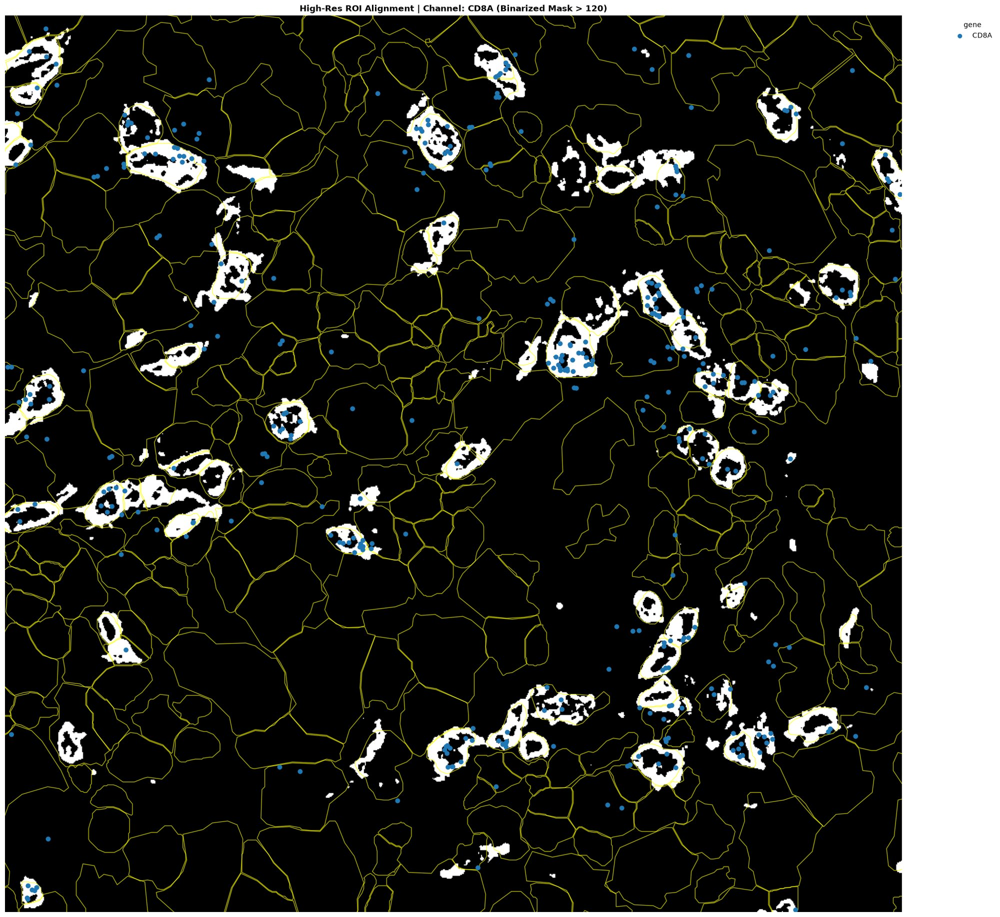

In [95]:
fig, ax = plot_scaled_image_roi(
    sdata=sdata, roi=(200, 400, 0, 200),channel="CD8A",
    gene_list=["CD8A"],boundary_edgecolor='yellow',
    color_key="gene", # or any custom categorical/numerical column inside transcripts
    scatter_size=50.0,binarization_threshold=120,figsize=(20,20))

plt.show()

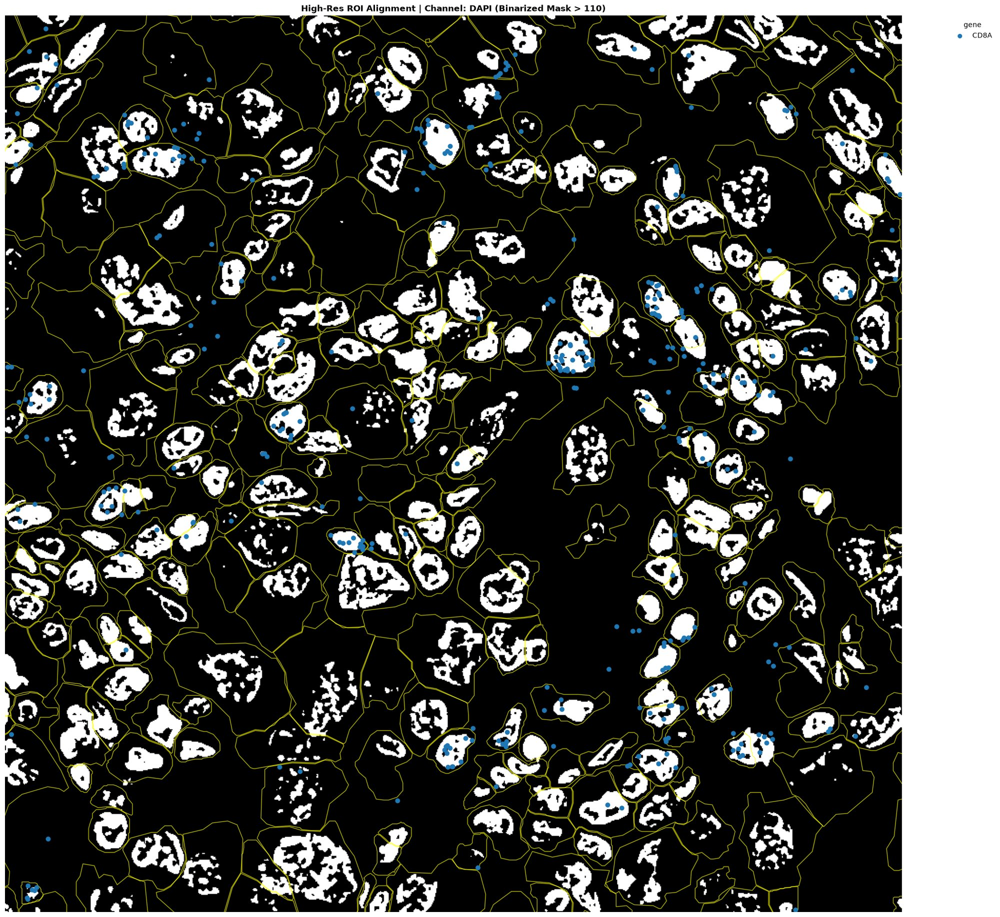

In [92]:
fig, ax = plot_scaled_image_roi(
    sdata=sdata, roi=(200, 400, 0, 200),channel="DAPI",
    gene_list=["CD8A"],boundary_edgecolor='yellow',
    color_key="gene", # or any custom categorical/numerical column inside transcripts
    scatter_size=50.0,binarization_threshold=110,figsize=(20,20))

plt.show()

In [105]:
df_summary

,Channel Name,Intensity Threshold,% Positive Pixels (Signal)
0,DAPI,100,23.72
1,ATP1A1/CD45/E-Cadherin,100,5.28
2,18S,100,0.58
3,alphaSMA/Vimentin,100,1.52
4,Blue background,100,1.50
5,Green background,50,0.00
6,Yellow background,100,0.00
7,Red background,100,0.16
8,CD4,100,36.78
9,CD20,150,0.01


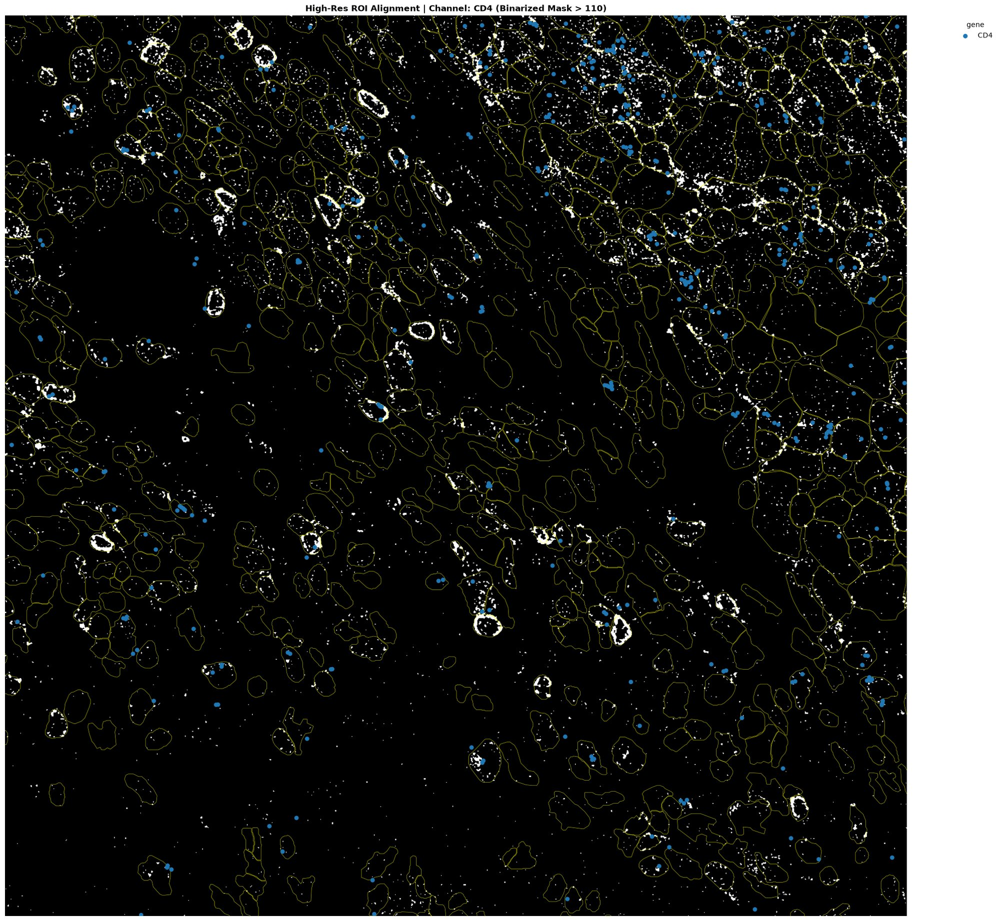

In [115]:
fig, ax = plot_scaled_image_roi(
    sdata=sdata, roi=(2300, 2600, 200, 500),channel="CD4",
    gene_list=["CD4"],boundary_edgecolor='yellow',
    color_key="gene", # or any custom categorical/numerical column inside transcripts
    scatter_size=40.0,binarization_threshold=110,figsize=(20,20),boundary_linewidth=0.5)

plt.show()

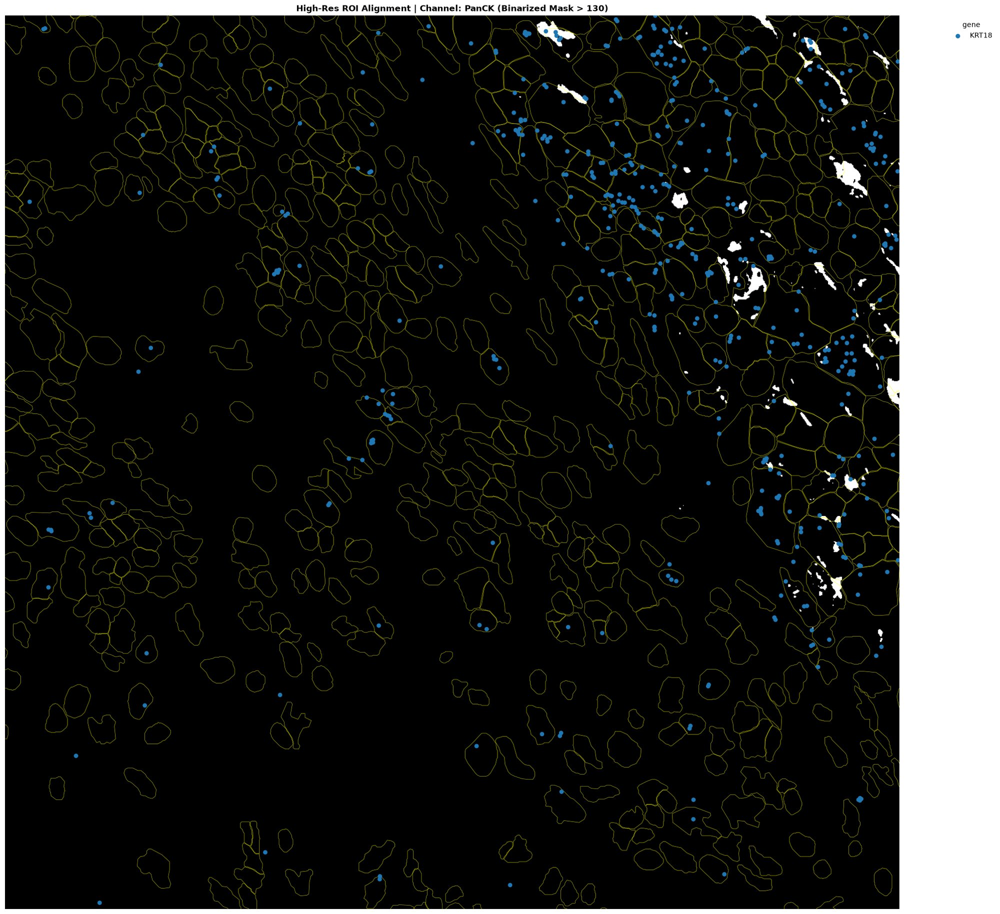

In [121]:
fig, ax = plot_scaled_image_roi(
    sdata=sdata, roi=(2300, 2600, 200, 500),channel="PanCK",
    gene_list=["KRT18"],boundary_edgecolor='yellow',
    color_key="gene", # or any custom categorical/numerical column inside transcripts
    scatter_size=40.0,figsize=(20,20),boundary_linewidth=0.5,binarization_threshold=130)

plt.show()

In [ ]:
# 1. Compute and subsample
transcripts = sdata.points["transcripts"].compute()
subsampled_df = transcripts.sample(frac=0.01, random_state=42)
# 2. Re-parse into a PointsModel and update the layer
sdata.points["transcripts"] = sd.models.PointsModel.parse(subsampled_df)

In [ ]:
import numpy as np
import scanpy as sc
import spatialdata as sd
import xarray as xr


def image_intensities_per_transcript(
    sdata: sd.SpatialData,
    image_key: str,
    scale: str,
    transcript_key: str,
    extracellular: bool = False,
    copy: bool = True,
    gene_key: str = "gene",
) -> sd.SpatialData:
    """
    Extracts image intensities at transcript locations and adds them as a new layer in the SpatialData object.

    Args:
        sdata
            The input SpatialData object.
        image_key
            The key for the image layer in sdata.images.
        scale
            The scale of the image to use.
        transcript_key
            The key for the transcript points in sdata.points.
        extracellular
            Whether to include only extracellular transcripts (default: False). If True, only transcripts where `extracellular` is True are used. If false, all transcripts are used.
        copy
            Whether to create a copy of the SpatialData object (default: True).

    Returns
    -------
        A SpatialData object with the added 'transcripts_image_intensities' layer.  If copy=True, a new SpatialData object is returned. Otherwise, the original sdata object is modified and returned.

    Raises
    ------
        KeyError: If the specified image or transcript key is not found in the SpatialData object.
    """
    try:
        image = sdata.images[image_key][scale]  # Image as xarray.DataArray
        transcripts = sdata.points[transcript_key].compute()  # Transcript coordinates
    except KeyError as e:
        raise KeyError(f"Key not found in sdata: {e}")  # noqa: B904

    imarray = image.image.compute()

    minx = transcripts.x.min()
    maxx = transcripts.x.max()
    transcripts_size_x = maxx - minx
    image_size_x = imarray.shape[2]
    multi_factor_x = image_size_x / transcripts_size_x

    miny = transcripts.y.min()
    maxy = transcripts.y.max()
    transcripts_size_y = maxy - miny
    image_size_y = imarray.shape[1]
    multi_factor_y = image_size_y / transcripts_size_y

    transcripts["x_scaled"] = (transcripts["x"] - minx) * multi_factor_x
    transcripts["y_scaled"] = (transcripts["y"] - miny) * multi_factor_y

    if extracellular:
        transcripts = transcripts[transcripts["extracellular"]]  # Select extracellular transcripts
    else:
        transcripts = transcripts

    # Get (x, y) coordinates of transcripts
    xy_positions = np.column_stack((transcripts["x_scaled"], transcripts["y_scaled"]))
    xy_positions_raw = np.column_stack((transcripts["x"], transcripts["y"]))

    # Interpolate or fetch nearest pixel values
    intensities = image.sel(
        x=xr.DataArray(xy_positions[:, 0], dims="points"), y=xr.DataArray(xy_positions[:, 1], dims="points"), method="nearest"
    )  # Use "linear" for interpolation

    intensity_tab = np.zeros([len(intensities.x.values), 2])
    intensity_tab[:, 0] = intensities.x.values
    intensity_tab[:, 1] = intensities.y.values

    ad_data = intensities.image.values.transpose()
    if ad_data.ndim == 2:  # Check if it is a 2D image
        ad = sc.AnnData(ad_data)
        ad.var.index = intensities.c.values
    else:  # If not, assume it is a 3D image and flatten the last dimension
        ad = sc.AnnData(ad_data.reshape(ad_data.shape[0], -1))
        ad.var.index = [f"{c}_{z}" for c in intensities.c.values for z in range(ad_data.shape[2])]  # Create combined channel and z-slice names.

    ad.obs[gene_key] = list(transcripts[gene_key])  # Add feature names
    ad.obsm["spatial"] = xy_positions_raw  # Add raw spatial coordinates

    # Add the AnnData object as a new spatial data object
    sdata["image_intensity_per_transcript"] = ad

    return sdata if copy else None

import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from sklearn.metrics.pairwise import cosine_similarity
import spatialdata as sd

def refine_urna_by_probabilistic_similarity(
    sdata: sd.SpatialData,
    intensity_adata_key: str = "image_intensity_per_transcript",
    prob_threshold: float = 0.5,copy=False,
):
    # 1. Prepare Data
    transcripts = sdata.points["transcripts"].compute().copy()
    adata = sdata[intensity_adata_key]
    
    # Positional index to map correctly to AnnData rows (0 to N-1)
    transcripts['matrix_pos'] = np.arange(len(transcripts))
    intensity_matrix = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
    
    if len(transcripts) != intensity_matrix.shape[0]:
        raise ValueError(f"Shape mismatch: Transcripts ({len(transcripts)}) vs Matrix ({intensity_matrix.shape[0]})")

    # 2. Compute "Cellular Reference" Signatures 
    # Using 'closest_cell_type' from assigned transcripts only
    cell_mask = transcripts['overlaps_cell'] == True
    
    signatures = {}
    unique_types = transcripts.loc[cell_mask, 'closest_cell_type'].unique()
    
    for ct in unique_types:
        if pd.isna(ct) or ct == "UNASSIGNED": continue
        
        pos_indices = transcripts.loc[(transcripts['closest_cell_type'] == ct) & cell_mask, 'matrix_pos'].values
        if len(pos_indices) > 5: 
            signatures[ct] = intensity_matrix[pos_indices].mean(axis=0)

    if not signatures:
        print("Warning: No cellular signatures found. Check 'overlaps_cell' and 'closest_cell_type'.")
        return sdata

    sig_matrix = np.array(list(signatures.values()))

    # 3. Calculate Similarity for ALL transcripts (Intra + Extra)
    print("Calculating cosine similarities...")
    all_similarities = cosine_similarity(intensity_matrix, sig_matrix)
    transcripts["max_cosine_sim"] = all_similarities.max(axis=1)

    # 4. Bayesian Posterior Calculation
    # We compare the similarity distribution of 'Known Cellular' vs 'Potential URNA'
    scores_inside = transcripts.loc[transcripts["overlaps_cell"] == True, "max_cosine_sim"].dropna().values
    scores_outside = transcripts.loc[transcripts["overlaps_cell"] == False, "max_cosine_sim"].dropna().values

    if len(scores_inside) > 20 and len(scores_outside) > 20:
        print("Calculating Bayesian probability distributions...")
        kde_in = gaussian_kde(scores_inside)
        kde_out = gaussian_kde(scores_outside)
        
        all_scores = transcripts["max_cosine_sim"].values
        li_in = kde_in(all_scores)
        li_out = kde_out(all_scores)
        
        # Posterior: Probability a transcript belongs to the 'Outside' distribution
        # P(URNA | Similarity) = Likelihood_Out / (Likelihood_Out + Likelihood_In)
        transcripts["prob_is_urna_stainings"] = li_out / (li_out + li_in + 1e-10)
        
        # Log the threshold where P=0.5
        db_idx = np.argmin(np.abs(transcripts["prob_is_urna_stainings"] - 0.5))
        print(f"Probabilistic boundary (P=0.5) found at cosine_similarity: {all_scores[db_idx]:.4f}")
    else:
        print("Insufficient data for KDE. Creating null column.")
        transcripts["prob_is_urna_stainings"] = 0.0

    # 5. Define Extracellular (URNA)
    # Must be physically outside a cell AND match the 'Outside' protein signature
    transcripts["extracellular_stainings"] = (transcripts["overlaps_cell"] == False) & (transcripts["prob_is_urna_stainings"] > prob_threshold)

    # Clean up and update sdata
    output_df = transcripts.drop(columns=['matrix_pos'])
    sdata.points["transcripts"] = sd.models.PointsModel.parse(output_df)
    
    return sdata if copy else None


In [ ]:
image_intensities_per_transcript(sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=False, copy=False)

In [ ]:
refine_urna_by_probabilistic_similarity(sdata)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_joint_comparison(df, x_col='prob_is_urna', y_col='prob_is_urna_stainings', hue_col='overlaps_cell', s=2, alpha=0.3):
    """
    Creates a JointPlot with marginal distributions for any two variables in the dataframe.
    """
    # 1. Handle Palette logic
    if hue_col in ['overlaps_cell', 'extracellular', 'extracellular_stainings']:
        palette = {True: '#d62728', False: '#1f77b4'}
    elif df[hue_col].nunique() > 10:
        palette = sns.color_palette("husl", df[hue_col].nunique())
    else:
        palette = "deep"

    # 2. Initialize the JointGrid
    g = sns.JointGrid(data=df, x=x_col, y=y_col, hue=hue_col, palette=palette)

    # 3. Plot the Scatter in the center
    g.plot_joint(sns.scatterplot, s=s, alpha=alpha, edgecolor=None)

    # 4. Plot the Marginal Distributions (KDEs)
    # common_norm=False allows smaller groups (like rare niches) to be visible in density
    g.plot_marginals(sns.kdeplot, fill=True, alpha=0.2, common_norm=False)

    # 5. Dynamic Formatting
    g.fig.set_size_inches(7, 6)
    
    # Clean up labels for the title
    title_x = x_col.replace('_', ' ').title()
    title_y = y_col.replace('_', ' ').title()
    g.fig.suptitle(f"{title_x} vs {title_y}\nColored by: '{hue_col}'", 
                   fontweight='bold', y=1.02)
    
    g.ax_joint.set_xlabel(title_x)
    g.ax_joint.set_ylabel(title_y)

    # 6. Add Consensus line only if axes have similar ranges (e.g., both are 0-1 probabilities)
    x_min, x_max = df[x_col].min(), df[x_col].max()
    y_min, y_max = df[y_col].min(), df[y_col].max()
    
    if (0 <= x_min <= 0.1 and 0.9 <= x_max <= 1.0) and (0 <= y_min <= 0.1 and 0.9 <= y_max <= 1.0):
        g.ax_joint.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.4, label='Consensus')
    
    # Legend handling
    plt.legend(title=hue_col.replace('_', ' ').title(), bbox_to_anchor=(1.2, 1), loc='upper left')
    
    plt.show()

# --- Example Usage ---
# df = sdata.points["transcripts"].compute()

# Compare transcriptomic prob vs staining prob
# plot_joint_comparison(df, x_col='prob_is_urna', y_col='prob_is_urna_stainings')

# Compare raw similarity vs staining probability
# plot_joint_comparison(df, x_col='max_cosine_sim', y_col='prob_is_urna_stainings', hue_col='extracellular_stainings')

In [ ]:
# Execution Examples
output_transcripts = sdata.points["transcripts"].compute()

# 1. Color by segmentation status
plot_joint_comparison(output_transcripts, hue_col='overlaps_cell', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')

# 1. Color by segmentation status
plot_joint_comparison(output_transcripts, hue_col='extracellular', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(output_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')

In [ ]:
out_transcripts=output_transcripts[output_transcripts['overlaps_cell']==False]
confusion_extracellular=pd.crosstab(out_transcripts['extracellular'],out_transcripts['extracellular_stainings'])
# 1. Color by segmentation status
plot_joint_comparison(out_transcripts, hue_col='overlaps_cell', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='nucleus_distance')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='cosine_similarity')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='assignment_score')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,y_col='max_cosine_sim', x_col='cosine_similarity')
plot_joint_comparison(out_transcripts, hue_col='extracellular', s=1,y_col='max_cosine_sim', x_col='cosine_similarity')

In [ ]:
from scipy.stats import gaussian_kde

def compute_consensus_urna_probability(df, x_col='cosine_similarity', y_col='max_cosine_sim'):
    """
    Computes a consensus probability of being extracellular using 2D KDE 
    over transcriptomic and staining similarities.
    """
    # 1. Define the two populations in 2D space
    # Inside = 'Ground Truth' Cellular
    # Outside = Potential URNA
    mask_in = df['overlaps_cell'] == True
    mask_out = df['overlaps_cell'] == False
    
    # Prepare coordinates: shape (2, N)
    train_in = np.vstack([df.loc[mask_in, x_col], df.loc[mask_in, y_col]])
    train_out = np.vstack([df.loc[mask_out, x_col], df.loc[mask_out, y_col]])
    
    # 2. Fit 2D KDEs
    print("Fitting 2D Bayesian distributions...")
    kde_in = gaussian_kde(train_in)
    kde_out = gaussian_kde(train_out)
    
    # 3. Evaluate all points
    # We evaluate every transcript's (x, y) pair against both 2D distributions
    all_pts = np.vstack([df[x_col], df[y_col]])
    
    li_in = kde_in(all_pts)
    li_out = kde_out(all_pts)
    
    # 4. Compute 2D Posterior (Uniform Priors)
    df["prob_is_urna_consensus"] = li_out / (li_out + li_in + 1e-10)
    
    return df

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

def refine_urna_by_consensus_2d_optimized(sdata, transcript_key="transcripts", prob_threshold=0.5):
    transcripts = sdata.points[transcript_key].compute().copy()
    cols = ['cosine_similarity', 'max_cosine_sim']
    
    # 1. Clean data (No NaNs allowed)
    valid_mask = np.isfinite(transcripts[cols]).all(axis=1)
    df_v = transcripts[valid_mask]

    # 2. SUBSAMPLE to train (Learning the 'shape' of the data)
    # We only need a representative slice to build the 2D map
    train_size = 20000 
    df_in = df_v[df_v['overlaps_cell'] == True]
    df_out = df_v[df_v['overlaps_cell'] == False]
    
    s_in = df_in.sample(min(len(df_in), train_size))
    s_out = df_out.sample(min(len(df_out), train_size))

    # Fit the 2D KDEs
    kde_in = gaussian_kde(np.vstack([s_in[cols[0]], s_in[cols[1]]]))
    kde_out = gaussian_kde(np.vstack([s_out[cols[0]], s_out[cols[1]]]))

    # 3. CHUNK the evaluation (Processing in bite-sized pieces)
    probs = np.full(len(transcripts), 0.5, dtype=np.float32)
    valid_idx = np.where(valid_mask)[0]
    all_coords = np.vstack([transcripts.loc[valid_mask, cols[0]], 
                            transcripts.loc[valid_mask, cols[1]]])

    chunk_size = 100000 
    print(f"Processing {all_coords.shape[1]:,} points...")
    
    for i in range(0, all_coords.shape[1], chunk_size):
        end = i + chunk_size
        chunk = all_coords[:, i:end]
        
        li_in = kde_in(chunk)
        li_out = kde_out(chunk)
        
        probs[valid_idx[i:end]] = li_out / (li_out + li_in + 1e-10)

    transcripts["prob_is_urna_consensus"] = probs
    transcripts["extracellular_consensus"] = (transcripts["overlaps_cell"] == False) & \
                                             (transcripts["prob_is_urna_consensus"] > prob_threshold)

    sdata.points[transcript_key] = sd.models.PointsModel.parse(transcripts)
    return sdata

In [ ]:
refine_urna_by_consensus_2d_optimized(sdata, transcript_key="transcripts", prob_threshold=0.5)

# --- STEP 4: Visualize Results ---
df_final = sdata["transcripts"].compute()

# Plot the 2D decision space
plot_joint_comparison(
    df_final, 
    x_col='cosine_similarity', 
    y_col='max_cosine_sim', 
    hue_col='prob_is_urna_consensus'
)

In [ ]:
main_path = "/media/sergio/Meninges/troutpy/rois/"
files = os.listdir(main_path)

In [ ]:
for file in files:
    inpath = os.path.join(main_path, file)
    print(inpath)
    #try:
    run_exrna_analysis_pipeline(
        inpath=inpath,
        binsize=3,  # SAiNSC bin size
        background_filter=0.4,  # SAiNSC background threshold
        gaussian_kernel_key=2.0,  # SAiNSC Gaussian sigma
        sainsc_threads=4,  # Number of threads for SAiNSC
        percentile_threshold=10,  # Percentile to call extracellular
        square_size=10,  # Microns for aggregation bins
        min_counts_env=5,  # Min counts for neighbor estimate
        spatial_var_neighbors=10,  # Neighbors for spatial variability
        colocalization_threshold=1,  # Threshold for colocalization
        min_logfoldratio=0.0,  # Filter threshold on logfoldratio
        lambda_decay=0.5,  # Decay constant for source scoring
        source_njobs=2,  # Jobs for compute_source_score
        diffusion_params={  # Any extra args for diffusion_results
            "x_col": "mean_displacement",
            "y_col": "-log_ks_pval",
            "label_top_n_x": 3,
            "label_top_n_y": 3,
            "label_bottom_n_x": 3,
            "label_bottom_n_y": 3,
            "y_logscale": False,
            "title": None,
            "palette": "troutpy",
        },
        scatter_params=[  # List of metric_scatter calls
            ("logfoldratio_over_noise", "extracellular_proportion", 5, 0, 0, 0),
            ("in_out_spearmanR", "extracellular_proportion", 5, 0, 5, 0),
            ("in_out_spearmanR", "moran_I", 0, 5, 0, 5),
            ("proportion_of_colocalized", "extracellular_proportion", 5, 0, 5, 0),
        ],
        spatial_map_categories=[
            "mean_displacement",
            "logfoldratio_over_noise",
            "in_out_spearmanR",
            "moran_I",
            "extracellular_proportion",
            "proportion_of_colocalized",
        ],
        spatial_map_top=3,
        spatial_map_bottom=3,
        spot_size_cells=10,
        spot_size_extra=15,
    )
    #except:
    #    print('not possible to run')